# Read me first

This notebook is the whole solution: the exploration, the features, the two models, and both problems. It is long on purpose. The search, including what failed, is part of the answer. This first cell is the map; every number below it is printed by a code cell further down.

Task: Select SOLUSDT maker fills to maximize the summed 1 s profit. Two problems: all fills (`BEST_PRICE_TRADES = True`), and only the fills strictly past the best quote (`False`).

Problem 1: A gradient boosted trees regressor on 17 causal features (7 direction, 10 risk), trained to predict the 1 s profit; take a fill iff the prediction is positive. Month-out validation: held-out April +63.52 of summed return, about 34% of the oracle (the imb1>0 rule gets +51.40, accept-all -101.23); held-out February +110.65, about 18% (against +75.90 and -292.68). A neural net on the same features lands just under the trees (+62.51, +108.33). Hand-in: the trees (`solution/p1_gbt.joblib`).

Problem 2: On deep fills the expected profit is negative almost everywhere: taking everything loses -132.76 over the period and even the oracle only makes +110.07. The right output is to skip almost everything. With the two hidden-liquidity columns added (nineteen features), the trees end at +0.04 / -1.15 on the held-out months and the net at 0.00 / -0.00; every rescue idea fails too. Hand-in: the net (`solution/p2_nn.joblib`).

Map:
- Starter cells (shipped with the repo): sample generation, monthly summary, profit distribution, toy strategy.
- 1.1 Brainstorming: First the ground work: the notation and a shared toolbox, a parity check on the book cleaning, the general information (the 53 ms strobe, measured on every day), the baselines (oracle, accept-all, momentum, contrarian), and the anatomy of the losses (no fat outlier; the worst 5% of fills carry about half the loss). Then the feature hunt, block by block, each block with the same shape (motivation, code, interpretation): trade size and |move| (risk, not direction), cross-asset lead-lag (no lead), book imbalance (the one real direction signal), trade flow (an echo of the imbalance), cross-asset book imbalance (BTC and ETH add), the deviation from the 1 s average (and its BTC/ETH versions), the risk screen (quote flips, depth, cross-asset |move|, the print past the stale quote, the spread), and the support behind the fill price. The rule throughout: a feature that adds something genuine goes into the model; echoes and zeros stay out.
- 1.2 Model building: The feature vector $\phi$, why trees, how they are trained and validated, the report, then the same for the net, and the interpretations.
- 2.1 Brainstorming (deep fills): The set and its shape (half the fills lose), the two screens on it (direction dies there, risk gets stronger, deeper imbalance does not help and hidden-liquidity).
- 2.2 Model building: The same recipe on nineteen features, the reports, the rescue attempts (a prior from problem 1, reversal signals, the hour of the day, leaf grids: everything stays around zero), and the honest conclusion.
- The last cell saves the four trained models to `solution/`.

The formal background (how I understand the order book, the engine, and this problem, written bottom-up while learning it) is in `JOURNAL.md`. The short writeup asked by the README is `WRITEUP.md`.

# Starter sample generation

Build SOLUSDT maker-trade samples from BTCUSDT/ETHUSDT/SOLUSDT market data files.

In [1]:
from pathlib import Path
import importlib
import sys

ROOT = Path.cwd()
if not (ROOT / "utils").exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

import utils.starter_samples as starter_samples
starter_samples = importlib.reload(starter_samples)
build_samples = starter_samples.build_samples
toy_strategy_stats = starter_samples.toy_strategy_stats
monthly_profit_summary = starter_samples.monthly_profit_summary


# Folder created by ./copy_data.sh.
MARKET_DATA_PATH = ROOT / "data/market_data"
# First public date to generate samples for.
START_DATE = "20260201"
# Last public date to generate samples for.
END_DATE = "20260430"
# Events at or after sample time minus this latency are hidden from prediction.
LATENCY_US = 10_000
# Keep the first trade per maker direction in each window.
SELECT_WINDOW_US = 100_000
# If False, keep only trades strictly deeper than the prior best price.
BEST_PRICE_TRADES = True
# Maker rebate added to the 1s target, in basis points.
REBATE_BPS = 0.0
# Future horizon used for the profit target.
PROFIT_HORIZON_US = 1_000_000


Generate samples from cleaned market data and save them locally.

I changed this cell so it doesn't rebuild the samples every time. Compare it to the repo version.

In [2]:
# Number of dates processed in parallel. Lower this if RAM is tight.
WORKERS = 16
import pandas as pd

# Where to cache the built samples. The best-price flag changes the sample set, so the
# two task variants get separate cache files and never clobber each other.
_suffix = "" if BEST_PRICE_TRADES else "_deep"
SAMPLES_OUTPUT_PATH = ROOT / f"data/samples/starter_samples{_suffix}.parquet"

# Building from raw data takes a few minutes. Left False, this cell just reloads the cached
# parquet when it already exists, so reopening the notebook is instant. Set it True (or
# delete the file) to force a fresh rebuild, e.g. before handing in, or after changing any
# of the sample-generation parameters above (the cache does not track those).
REBUILD_SAMPLES = False

if not REBUILD_SAMPLES and SAMPLES_OUTPUT_PATH.exists():
    samples = pd.read_parquet(SAMPLES_OUTPUT_PATH)
    print(f"loaded {len(samples):,} cached rows from {SAMPLES_OUTPUT_PATH}")
else:
    # One row per first SOLUSDT maker-side trade in each 100ms bucket.
    samples = build_samples(
        market_data_root=MARKET_DATA_PATH,
        start_date=START_DATE,
        end_date=END_DATE,
        latency_us=LATENCY_US,
        select_window_us=SELECT_WINDOW_US,
        best_price_trades=BEST_PRICE_TRADES,
        rebate_bps=REBATE_BPS,
        profit_horizon_us=PROFIT_HORIZON_US,
        workers=WORKERS,
    )
    SAMPLES_OUTPUT_PATH.parent.mkdir(parents=True, exist_ok=True)
    samples.to_parquet(SAMPLES_OUTPUT_PATH, index=False, compression="zstd")
    print(f"wrote {len(samples):,} rows to {SAMPLES_OUTPUT_PATH}")

monthly_profit_summary(samples)


loaded 30,337,634 cached rows from data/samples/starter_samples.parquet


,month,count,sum_total,sum_positive,zero_pct,positive_pct,negative_pct
0,202602,11244140,-292.679922,611.548618,46.196677,21.932438,31.870886
1,202603,10606894,-195.290162,365.982903,57.762942,16.812688,25.424370
2,202604,8486600,-101.230506,184.229274,71.283459,11.246282,17.470259


Plot the 1-second profit distribution for all generated samples in basis points. The y-axis is logarithmic so the tails remain visible.

zero-profit samples: 17,370,815 / 30,337,634 (57.26%)


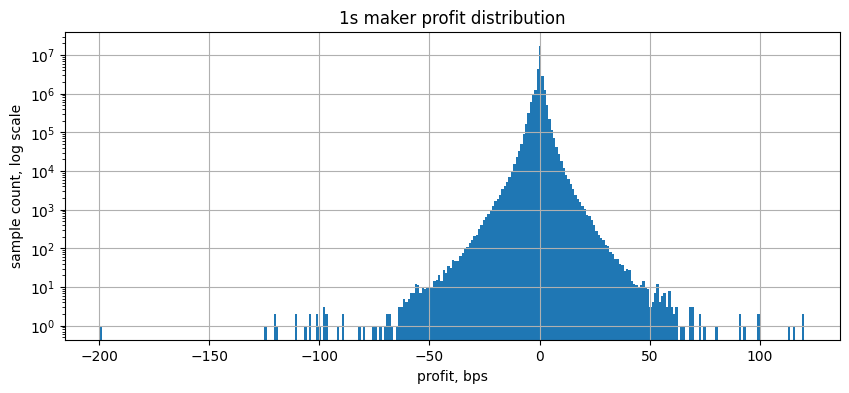

count    3.033763e+07
mean    -1.942144e-01
std      1.940726e+00
min     -1.996981e+02
1%      -6.133715e+00
10%     -2.239892e+00
50%      0.000000e+00
90%      1.203659e+00
99%      5.192108e+00
max      1.202749e+02
Name: profit_1s_with_rebate, dtype: float64

In [4]:
import matplotlib.pyplot as plt

profit_bps = samples["profit_1s_with_rebate"] * 10_000.0
zero_count = int((profit_bps == 0.0).sum())
zero_fraction = zero_count / len(profit_bps)
print(f"zero-profit samples: {zero_count:,} / {len(profit_bps):,} ({zero_fraction:.2%})")

ax = profit_bps.hist(bins=300, figsize=(10, 4), log=True)
ax.set_title("1s maker profit distribution")
ax.set_xlabel("profit, bps")
ax.set_ylabel("sample count, log scale")
plt.show()

profit_bps.describe(percentiles=[0.01, 0.10, 0.50, 0.90, 0.99])


Run a toy momentum rule to show the expected evaluation shape by month. It selects maker bid trades when the recent mid-price move is above the threshold, and maker ask trades when the move is below the negative threshold.

In [5]:
# Toy momentum rule: buy maker bid trades after an upward move, sell maker ask trades after a downward move.
toy_strategy_stats(samples, threshold_bps=0.0)

utils/starter_samples.py:317: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  return data.groupby("month").apply(selected_stats).reset_index()


,month,samples,selected,sum_profit_1s,avg_bps,p50_bps,p90_bps
0,202602,11244140.0,2761321.0,-58.305560,-0.211151,0.0,2.517306
1,202603,10606894.0,2000008.0,-24.234308,-0.121171,0.0,2.222716
2,202604,8486600.0,1045222.0,-7.122010,-0.068139,0.0,1.246261


# 1. The first problem

## 1.1 Brainstorming

Lets brainstorm the features that are relevant in building a model. This part consists of searching them, analysing them. Some of them may be irrelevant. I just test everything I have in mind.

I used Claude to generate the code and brainstorm some ideas. I corrected him multiple times and guided him on some points. He wrote most of the code: I don't memorize voc (but I will at some point!).

Before starting thinking of feature, here is some natural core concepts, notation, and shared helpers that came back in my analysis and after writing the JOURNAL.md that served as a way for me to understand what were talking about and essentially what is market making in deeper details. So to have something unified and not messy, I fix them once here, then define the helper functions that compute them. Recall there are two data feeds: the order book (snapshots) and the public trades (the fills come from the trades). Both are exemplified in the general-information cell below.

Let $X \in \{\mathrm{SOL}, \mathrm{BTC}, \mathrm{ETH}\}$ range over the three coins, and tag every book quantity with the coin $X$ it is read from. In dependency order:

- **Coin $X$'s book:** a snapshot is one row $r$ of coin $X$'s orderbook feed, a photo of the book published on the strobe. It carries 10 levels $i \in \{1, \dots, 10\}$ (the README says 10, so $i \le 10$ is the deepest I can ever read), with $i = 1$ the best quote (highest bid, lowest ask) and $i$ stepping away from the touch. In snapshot $r$, level $i$ has bid/ask prices $P^X_{b,i}(r), P^X_{a,i}(r)$ and resting sizes $V^X_{b,i}(r), V^X_{a,i}(r)$ (the bid_price_i / ask_price_i / bid_size_i / ask_size_i columns). One snapshot looks like this (a real example is printed in the general-information cell below):

```
  server_time | for each level i = 1..10:   bid  P^X_{b,i}(r) x V^X_{b,i}(r)    ask  P^X_{a,i}(r) x V^X_{a,i}(r)
```

- **Backward as-of** $f^{\leftarrow,X}(t)$: the book arrives as discrete snapshots, a strobe (its cadence is measured just below), so I never read it instantaneously. For a time $t$, let $R^X(t)$ be the last snapshot of coin $X$ at or before $t$. Then any book quantity $f^X$ (a rational number in the end) has an as-of value $f^{\leftarrow,X}(t) := f^X\big(R^X(t)\big)$, its value in that snapshot. In particular, we have the as-of sizes and prices $V^{\leftarrow,X}_{b,i}(t) = V^X_{b,i}\big(R^X(t)\big)$ and $P^{\leftarrow,X}_{b,i}(t) = P^X_{b,i}\big(R^X(t)\big)$, which feed the as-of mid.

- **As-of mid** $m^{\leftarrow,X}(t) = \tfrac12\big(P^{\leftarrow,X}_{b,1}(t) + P^{\leftarrow,X}_{a,1}(t)\big)$: the level-1 mid of the as-of snapshot $R^X(t)$.

- **Candidate fill** $x$: a maker trade I could decide to take (one row of any coin samples table, a thinned trade). Since $x$ is a specific trade it already carries its own coin, so everything read off it, and the following notions needs no coin tag: 

- **Time** the time of the trade $x$ is denoted $T(x)$ (its server_time).

- **Side** I attribute a sign specific to the side of the maker trade $x$ by $\sigma(x) = +1$ for a maker bid (a long) and $\sigma(x) = -1$ for a maker ask (a short).

- **Cutoff** $c(x) = T(x) - \lambda$, with $\lambda = 10$ ms the latency (the README's LATENCY_US, exposed as the events_before_server_time column). The causal rule the whole notebook obeys: a feature may read only events with server_time $\le c(x)$. 

- **Profit** The 1s profit label, written $\pi(x)$ (the profit_1s_with_rebate column, a return; its horizon is the README's PROFIT_HORIZON_US), is the one thing allowed to look past the fill.

- Concretely the row looks like this (an example with real numbers is printed in the general-information cell below):

```
  server_time   dir       price   volume | events_before_server_time | profit_1s_with_rebate
    = T(x)     = side σ   = P(x)  = V(x)  |     = c(x) = T(x) − λ      |  = π(x), the 1s label (forward)
```

- **Drift** $\Delta^X(x) = m^{\leftarrow,X}(c(x)) - m^{\leftarrow,X}(c(x) - 1\,\mathrm{s})$: coin $X$'s mid move over the second before the cutoff. The column sol_mid_move_1s_bps is $\Delta^{\mathrm{SOL}}(x)$ as a normalized return, $\Delta^{\mathrm{SOL}}(x) / m^{\leftarrow,\mathrm{SOL}}(c(x) - 1\,\mathrm{s}) \times 10^4$ (bps).

The specialization to my task: I only ever decide on SOLUSDT trades, so every candidate fill $x$ is a SOL trade. BTC and ETH never produce fills; they are side information, entering only through features that I read causally at the cutoff $c(x)$. So far those features are book-based, but nothing stops a later one from using any coin's data (book or trades). So SOL is what I trade, the other coins are there to help me decide.

The helpers below compute exactly these, so the later cells stay short and the causal convention lives in one place: `load_book` / `load_trades` (read one coin-day and apply the one validity filter I use everywhere: drop the server_time = 0 session sentinels, the crossed books, and the one-sided ask = 9999999999 rows, so every later cell already works on cleaned books and trades), `asof` (the backward read $f^{\leftarrow,X}$, my no-look-ahead rule in a single function), `side_sign` ($\sigma$), and the test helpers reused across the feature cells: a NaN-safe `corr`, `decile_profit` (mean profit by feature decile), and `partial_corr` (does a feature add over controls).

A note on these loaders: I checked them against the starter's `read_day` (in `utils/starter_samples.py`, the code that built the samples), and the overlap is on purpose. `read_day` reads only the best-of-book, so it can't hand me the resting sizes the imbalance features need. So `load_book` re-reads the book with the size and price levels, and adds one guard `read_day` skips: the `ask < 4*bid` bound on the one-sided sentinel rows. So the little duplication in the cleaning is deliberate, not me redoing its work. The samples (the label `profit_1s_with_rebate` and the drift `sol_mid_move_1s_bps`) were built with `read_day`'s looser filter though, so right after the toolbox I check whether that matters for the label and the drift.

In [2]:
# ===================== shared toolbox (used by the analysis cells below) =====================
# Small primitives I reuse in every feature cell, so the causal convention and the book cleaning
# live in ONE place. Defined once here, right after the starter, then called downstream.
import numpy as np, pandas as pd

# Load one coin-day book, keep only sane snapshots, sorted by time. size_levels/price_levels say
# how many L1..Ln columns to pull (<=10, the feed's depth). THE book filter lives here, once:
# drop session sentinels (server_time=0), crossed books, and the one-sided ask=9999999999 rows
# (a real touch spread is a few bps, so ask past 4x bid can be assumed to be a glitch or a
# troller hence it defines a good filter: this is an assumption, I am happy to acknowledge
# I was wrong (please notice it to me in the review)).
def load_book(sym, day, size_levels=1, price_levels=1):
    cols = ["server_time", "bid_price_1", "ask_price_1"]
    cols += [f"bid_size_{i}"  for i in range(1, size_levels + 1)]
    cols += [f"ask_size_{i}"  for i in range(1, size_levels + 1)]
    cols += [f"bid_price_{i}" for i in range(2, price_levels + 1)]
    cols += [f"ask_price_{i}" for i in range(2, price_levels + 1)]
    b = pd.read_parquet(MARKET_DATA_PATH / f"{sym}/{day}_orderbook_10.parquet",
                        columns=list(dict.fromkeys(cols)))
    return b[(b.server_time > 0) & (b.bid_price_1 > 0) & (b.ask_price_1 > b.bid_price_1)
             & (b.ask_price_1 < 4 * b.bid_price_1)].sort_values("server_time", kind="mergesort")

# Load one coin-day trades, valid rows only, sorted by time.
def load_trades(sym, day):
    tr = pd.read_parquet(MARKET_DATA_PATH / f"{sym}/{day}_trades.parquet",
                         columns=["server_time", "aggressor_dir", "price", "volume"])
    return tr[(tr.server_time > 0) & (tr.price > 0) & (tr.volume > 0)].sort_values("server_time", kind="mergesort")

# THE causal read: value from the last event at server_time <= cutoff - lag (NaN if none). This is
# the one backward as-of every feature obeys (a feature may only see events up to the cutoff c(x)).
def asof(times, vals, cutoffs, lag_us=0):
    idx = np.searchsorted(times, np.asarray(cutoffs) - lag_us, side="right") - 1
    out = np.full(len(idx), np.nan); ok = idx >= 0
    out[ok] = np.asarray(vals)[idx[ok]]
    return out

# maker-side sign, +1 bid (long), -1 ask (short): folds the two sides onto one axis where >0 = my way.
def side_sign(dir_series):
    return np.where(np.asarray(dir_series) == "bid", 1.0, -1.0)

# NaN-safe Pearson correlation.
def corr(a, b):
    d = pd.DataFrame({"a": np.asarray(a, float), "b": np.asarray(b, float)}).replace([np.inf, -np.inf], np.nan).dropna()
    return d["a"].corr(d["b"])

# mean 1s profit (bps) by signed-feature decile: the workhorse sort test. Returns n / mean_bps / win_pct.
def decile_profit(feat, prof_bps, k=10):
    d = pd.DataFrame({"f": np.asarray(feat, float), "p": np.asarray(prof_bps, float)}).replace([np.inf, -np.inf], np.nan).dropna()
    q = pd.qcut(d["f"], k, labels=False, duplicates="drop"); g = d.groupby(q)
    return pd.DataFrame({"n": g["p"].size(), "mean_bps": g["p"].mean(),
                         "win_pct": g["p"].apply(lambda x: (x > 0).mean() * 100)})

# partial corr of profit & feat controlling for `controls` (dict name->array): residualize both on
# [1, controls] and correlate the residuals. The "does it ADD" test. NaN if feat is spanned by controls.
def partial_corr(prof, feat, controls):
    df = pd.DataFrame({"p": np.asarray(prof, float), "f": np.asarray(feat, float)})
    for k, v in controls.items(): df[k] = np.asarray(v, float)
    df = df.replace([np.inf, -np.inf], np.nan).dropna()
    A = np.column_stack([np.ones(len(df))] + [df[k].to_numpy() for k in controls])
    rz = lambda y: y - A @ np.linalg.lstsq(A, y, rcond=None)[0]
    rf = rz(df["f"].to_numpy())
    if np.std(rf) < 1e-12: return np.nan
    return np.corrcoef(rz(df["p"].to_numpy()), rf)[0, 1]

A quick parity check before I lean on `load_book` everywhere. The shipped samples (the label `profit_1s_with_rebate` and the drift `sol_mid_move_1s_bps`) were built by the starter's `read_day`, whose book filter has no `ask < 4*bid` bound. My feature loader `load_book` adds that bound, to drop the one-sided `ask = 9999999999` rows so a feature read (an imbalance, a price) never sits on a glitch snapshot. That guard earns its place on the feature side. But it also means my features clean the book a touch stricter than the samples were cleaned. So the fair question: if I rebuilt the label and the drift with my strict filter, would they move? I check it right here, in front of you. I rebuild both ways and diff.

In [7]:
# Parity check on the book cleaning: does load_book's stricter filter (ask < 4*bid) change the LABEL
# (profit_1s_with_rebate) or the DRIFT (sol_mid_move_1s_bps)? The shipped samples were built by
# utils/starter_samples.py:read_day, whose book filter has NO ask<4*bid bound; load_book adds it. So I
# rebuild the label and drift BOTH ways and diff, here, in front of you. _rebuild mirrors the starter's
# build_day_samples with a filter switch (best_price_trades honored via BEST_PRICE_TRADES from the config).
import numpy as np, pandas as pd

PAR_DAYS = sorted(samples["date"].unique())

# read_day keeps server_time>0 & bid>0 & ask>bid; load_book ALSO requires ask<4*bid. Count the rows
# where the two filters disagree (kept by read_day, dropped by load_book): the whole universe of impact.
def _n_divergent(day):
    b = pd.read_parquet(MARKET_DATA_PATH / f"SOLUSDT/{day}_orderbook_10.parquet",
                        columns=["server_time", "bid_price_1", "ask_price_1"])
    keep = (b.server_time > 0) & (b.bid_price_1 > 0) & (b.ask_price_1 > b.bid_price_1)
    return int((keep & ~(b.ask_price_1 < 4 * b.bid_price_1)).sum())
_div = {d: n for d in PAR_DAYS if (n := _n_divergent(d))}
print(f"book rows where the two filters disagree, over all {len(PAR_DAYS)} days: {sum(_div.values())}"
      f"   (on days: {', '.join(_div) or 'none'})")

# rebuild one day's samples, mirroring build_day_samples, with strict = load_book's filter.
def _rebuild(day, strict):
    b = pd.read_parquet(MARKET_DATA_PATH / f"SOLUSDT/{day}_orderbook_10.parquet",
                        columns=["server_time", "bid_price_1", "ask_price_1"])
    keep = (b.server_time > 0) & (b.bid_price_1 > 0) & (b.ask_price_1 > b.bid_price_1)
    if strict: keep &= (b.ask_price_1 < 4 * b.bid_price_1)                      # the extra load_book bound
    bk = b[keep].sort_values("server_time", kind="mergesort").reset_index(drop=True)
    tr = pd.read_parquet(MARKET_DATA_PATH / f"SOLUSDT/{day}_trades.parquet",
                         columns=["server_time", "aggressor_dir", "price", "volume"])
    tr = tr[(tr.server_time > 0) & (tr.price > 0) & (tr.volume > 0)].sort_values("server_time", kind="mergesort")
    tr["dir"] = np.where(tr.aggressor_dir.astype(int) == 0, "ask", "bid")       # maker side = flip aggressor
    tr["cut"] = tr.server_time.astype("int64") - LATENCY_US                     # events_before_server_time
    prior = bk.rename(columns={"server_time": "pt", "bid_price_1": "pb", "ask_price_1": "pa"})
    tr = pd.merge_asof(tr.sort_values("cut", kind="mergesort"), prior, left_on="cut", right_on="pt",
                       direction="backward").dropna(subset=["pb", "pa"])
    if not BEST_PRICE_TRADES:                                                   # deep-fills variant only
        tr = tr[((tr.dir == "bid") & (tr.price < tr.pb)) | ((tr.dir == "ask") & (tr.price > tr.pa))]
    tr["bucket"] = tr.server_time.astype("int64") // SELECT_WINDOW_US           # first trade per (dir, window)
    s = tr.sort_values("server_time", kind="mergesort").drop_duplicates(["dir", "bucket"], keep="first")
    s["ft"] = s.server_time.astype("int64") + PROFIT_HORIZON_US                 # mark-out time T+1s
    fut = bk.rename(columns={"server_time": "qt", "bid_price_1": "fb", "ask_price_1": "fa"})
    s = pd.merge_asof(s.sort_values("ft", kind="mergesort"), fut, left_on="ft", right_on="qt",
                      direction="forward").dropna(subset=["fb", "fa"])
    s["profit"] = np.where(s.dir == "bid", (s.fb - s.price) / s.price, (s.price - s.fa) / s.price) + REBATE_BPS / 1e4
    def _mid(s, left, out):                                                     # as-of mid at a time column
        m = bk.assign(m=(bk.bid_price_1 + bk.ask_price_1) / 2)[["server_time", "m"]] \
              .rename(columns={"server_time": out + "t", "m": out})
        return pd.merge_asof(s.sort_values(left, kind="mergesort"), m, left_on=left, right_on=out + "t", direction="backward")
    s = _mid(s, "cut", "mc"); s["cb"] = s.cut - PROFIT_HORIZON_US; s = _mid(s, "cb", "mp")
    s["drift"] = (s.mc - s.mp) / s.mp * 1e4
    return s.dropna(subset=["profit", "mc", "mp"])[["server_time", "dir", "profit", "drift"]].reset_index(drop=True)

# on each day that can differ: (1) my loose rebuild must equal the SHIPPED samples (validates the rebuild),
# (2) loose vs strict is the actual question. Fall back to one day if nothing diverges.
cache = samples[["date", "server_time", "dir", "profit_1s_with_rebate", "sol_mid_move_1s_bps"]]
n_moved = n_diff = 0; worst_p = worst_d = 0.0
for day in (_div or PAR_DAYS[:1]):
    L, S = _rebuild(day, False), _rebuild(day, True)
    C = cache[cache.date == day]
    v = L.merge(C, on=["server_time", "dir"])
    assert len(v) == len(L) == len(C) and (v.profit - v.profit_1s_with_rebate).abs().max() < 1e-12 \
        and (v.drift - v.sol_mid_move_1s_bps).abs().max() < 1e-9, f"{day}: loose rebuild != shipped samples"
    m = L.merge(S, on=["server_time", "dir"], how="outer", suffixes=("_L", "_S"), indicator=True)
    n_moved += int((m._merge != "both").sum())
    d = m[m._merge == "both"]
    n_diff += int(((d.profit_L - d.profit_S).abs() > 1e-12).sum() + ((d.drift_L - d.drift_S).abs() > 1e-9).sum())
    worst_p = max(worst_p, float((d.profit_L - d.profit_S).abs().max()))
    worst_d = max(worst_d, float((d.drift_L - d.drift_S).abs().max()))
print("loose rebuild reproduces the shipped samples on those days (checked).")
print(f"loose vs strict:  samples added or dropped = {n_moved}   samples with a changed label or drift = {n_diff}")
print(f"                  max |change in label| = {worst_p:.2e} (fraction)   max |change in drift| = {worst_d:.2e} bps")

book rows where the two filters disagree, over all 89 days: 5   (on days: 20260212, 20260315, 20260405, 20260421)
loose rebuild reproduces the shipped samples on those days (checked).
loose vs strict:  samples added or dropped = 0   samples with a changed label or drift = 0
                  max |change in label| = 0.00e+00 (fraction)   max |change in drift| = 0.00e+00 bps


So it does not move. The two filters disagree on only a handful of book rows over the whole period (the count printed above), all one-sided `9999999999` asks, and none of them is the snapshot a 1s mark-out or a drift read lands on. Rebuilding the label and the drift with the strict filter hands back the exact same samples, zero changed. So the shipped label and drift are safe as they are, and the `ask < 4*bid` guard stays where it belongs, on the feature reads in `load_book`.

Now lets confirm the general information (the notions introduced above that rely on the README) and get some information the whole notebook leans on, printed once up front: how fast each book updates (the strobe), the latency and profit horizon (both README config), how many levels each feed carries, one example row of each feed (a book snapshot and a candidate fill), and the causal timeline every fill sits in.

In [3]:
# General information the whole notebook leans on, printed once up front: how fast each book updates
# (the strobe), the latency and profit horizon from the config, how many levels each feed carries, and
# the causal timeline every fill sits in.
import pandas as pd, pyarrow.parquet as pq

COINS = ("SOLUSDT", "BTCUSDT", "ETHUSDT")

# (a) book update cadence (the strobe) for each coin, checked on EVERY day: the median gap between
# consecutive snapshots per day, then the spread of those daily medians. Drop the server_time = 0
# session-open sentinels so the 0 -> first-time jump doesn't wreck the numbers. I print all three
# because later cells put the coins on one shared clock.
_days = sorted(p.name[:8] for p in (MARKET_DATA_PATH / "SOLUSDT").glob("*_orderbook_10.parquet"))
for _sym in COINS:
    _med, _mx = [], []
    for _d in _days:
        _bk = pd.read_parquet(MARKET_DATA_PATH / f"{_sym}/{_d}_orderbook_10.parquet", columns=["server_time"])["server_time"]
        _bk = _bk[_bk > 0].sort_values()
        _g = _bk.diff().dropna() / 1000
        _med.append(_g.median()); _mx.append(_g.max())
    _med, _mx = pd.Series(_med), pd.Series(_mx)
    print(f"{_sym} daily median book gap over {len(_days)} days: median {_med.median():.0f} ms  min {_med.min():.0f} ms  max {_med.max():.0f} ms; "
          f"longest single gap {_mx.max()/1000:.0f} s (on {_days[int(_mx.idxmax())]})")

# (b) latency and profit horizon, read from the config above (not hard-coded).
_lat = int(LATENCY_US / 1000)          # ms before the fill my information freezes
_hor = int(PROFIT_HORIZON_US / 1e6)    # s past the fill the label looks
print(f"\nlatency = {_lat} ms   profit horizon = {_hor} s")

# (c) how many levels N each feed carries: bid_price_i / ask_price_i / bid_size_i / ask_size_i for
# i = 1..N. The name orderbook_10 suggests 10, but I count from the columns rather than assume.
for _sym in COINS:
    _levels = sum(1 for cc in pq.ParquetFile(MARKET_DATA_PATH / f"{_sym}/20260317_orderbook_10.parquet").schema.names if cc.startswith("ask_price_"))
    print(f"{_sym} book levels in the feed: {_levels}")

# (d) one book snapshot r, so the other feed's row shape is concrete too: server_time plus, per level
# i, the bid/ask price and size. One real SOLUSDT orderbook_10 row (top 3 of the 10 levels shown).
_bkcols = ["server_time"] + [f"{_s}_{_k}_{_i}" for _i in (1, 2, 3) for _s in ("bid", "ask") for _k in ("price", "size")]
_br = pd.read_parquet(MARKET_DATA_PATH / "SOLUSDT/20260317_orderbook_10.parquet", columns=_bkcols)
_br = _br[(_br.server_time > 0) & (_br.bid_price_1 > 0) & (_br.ask_price_1 > _br.bid_price_1) & (_br.ask_price_1 < 2 * _br.bid_price_1)]
_r = _br.iloc[len(_br) // 2]
print("\none book snapshot r (a SOLUSDT orderbook_10 row, top 3 of 10 levels):")
print(f"    server_time = {int(_r.server_time)}")
for _i in (1, 2, 3):
    print(f"    L{_i}  bid {_r[f'bid_price_{_i}']:>7} x {_r[f'bid_size_{_i}']:<8}  ask {_r[f'ask_price_{_i}']:>7} x {_r[f'ask_size_{_i}']:<8}")

# (e) one candidate fill x, so the row shape is concrete: server_time is T(x), dir gives the side
# sigma(x), price/volume are P(x)/V(x), events_before_server_time is the cutoff c(x), and profit is
# the forward 1s label. One real samples row:
_x = samples.iloc[0]
print("\none candidate fill x (a SOL samples row):")
for _f, _v, _lab in [("server_time", _x.server_time, "T(x)"),
                     ("events_before_server_time", _x.events_before_server_time, "c(x) = T(x) - latency"),
                     ("dir", _x.dir, "side, sigma(x)"), ("price", _x.price, "P(x)"),
                     ("volume", _x.volume, "V(x)"),
                     ("profit_1s_with_rebate", f"{_x.profit_1s_with_rebate:+.6f}", "pi(x), 1s label, forward")]:
    print(f"    {_f:26s} = {str(_v):>18}   [{_lab}]")

# (f) Since SOL is what I trade, BTC and ETH are side information. I have only one situation I care
# about: the causal situation every sample is in. There is one fill at time T, but I must decide
# whether to take it using only what was known a latency before it. The ms and s are the _lat/_hor above.
print(f"""
this is the situation we are in, for one sample x (fill at time T(x)):

   ... events ≤ c(x)]            (c(x) ──{_lat}ms──> T(x))   (T(x) ──────{_hor} s──────> T(x)+{_hor}s]
      the window I'm allowed      latency gap                the profit window
      features only here           forbidden                  forbidden (the label, looks ahead)

   where c(x) = T(x) − {_lat}ms = the cutoff (the events_before_server_time column). A feature may use only
   events with server_time ≤ c(x). The {_hor} s profit is the one thing allowed to look past the fill.""")

SOLUSDT daily median book gap over 89 days: median 53 ms  min 51 ms  max 57 ms; longest single gap 281 s (on 20260423)


BTCUSDT daily median book gap over 89 days: median 52 ms  min 51 ms  max 52 ms; longest single gap 282 s (on 20260423)


ETHUSDT daily median book gap over 89 days: median 52 ms  min 51 ms  max 52 ms; longest single gap 281 s (on 20260423)

latency = 10 ms   profit horizon = 1 s
SOLUSDT book levels in the feed: 10
BTCUSDT book levels in the feed: 10
ETHUSDT book levels in the feed: 10

one book snapshot r (a SOLUSDT orderbook_10 row, top 3 of 10 levels):
    server_time = 1773748360795000
    L1  bid   93.82 x 1871.08   ask   93.83 x 523.4   
    L2  bid   93.81 x 1099.28   ask   93.84 x 1131.43 
    L3  bid    93.8 x 1361.25   ask   93.85 x 3604.0  

one candidate fill x (a SOL samples row):
    server_time                =   1769904007971000   [T(x)]
    events_before_server_time  =   1769904007961000   [c(x) = T(x) - latency]
    dir                        =                ask   [side, sigma(x)]
    price                      =             105.48   [P(x)]
    volume                     =               0.05   [V(x)]
    profit_1s_with_rebate      =          -0.000095   [pi(x), 1s label, forward]

this 

So: each book updates on basically the same strobe, and this holds on every one of the 89 days, not just one. The daily median gap is 53 ms for SOL (the 89 daily medians stay between 51 and 57 ms) and 52 ms for BTC and ETH (51 to 52 ms). That is the finest time resolution any book-based feature can have, on any day of the period. The same check surfaces one anomaly: the longest single gap is around 281 s, on all three books on the same day (2026-04-23), so the venue itself went quiet for almost five minutes. Fills right after that window read a book that stale, and their 1 s label marks out on the first snapshot after the gap. It is one short window in 89 days; I leave those fills in, and the model treats them like any other. Latency is 10 ms and the profit horizon 1 s (the config), and each feed carries 10 levels. It also prints one example fill row, so the row shape is concrete: server_time is T(x), dir the side, price and volume are P(x) and V(x), and events_before_server_time is the cutoff c(x).

Now, we can start.

I first make a little note for myself to explain the toy strategy. For each candidate fill $x$ (side fixed, bid = long, ask = short) the strategy takes the fill only when the recent drift $\Delta^{\mathrm{SOL}}(x)$ (defined in the concepts cell above) points the same way as the side. At the default threshold 0 that is: take iff $\Delta^{\mathrm{SOL}}(x) > 0$ for a long, or $\Delta^{\mathrm{SOL}}(x) < 0$ for a short. So it's a bet that the recent drift continues into the next second.

The starter of this notebook already prints monthly profit; I want three more numbers. First, the best score you could get if you could see the future and kept only the winning trades, call it the oracle. Second, what share of trades win each month. Third, how a naive contrarian rule does: the mirror image of the toy momentum rule, betting the recent drift reverses rather than continues. The point is just to see what I'm aiming at, and to check that the drift has some momentum. I also plot the four rules over time, each one's profit accumulated day by day, to see how far each sits from the oracle.

=== score ladder (total Feb-Apr) ===
accept_all        :     -589.201
oracle_max        :     1161.761   (selected 5,203,845)
reverse_contrarian:     -239.231   (selected 5,970,172)
toy_momentum      :      -89.662   (selected 5,806,551)


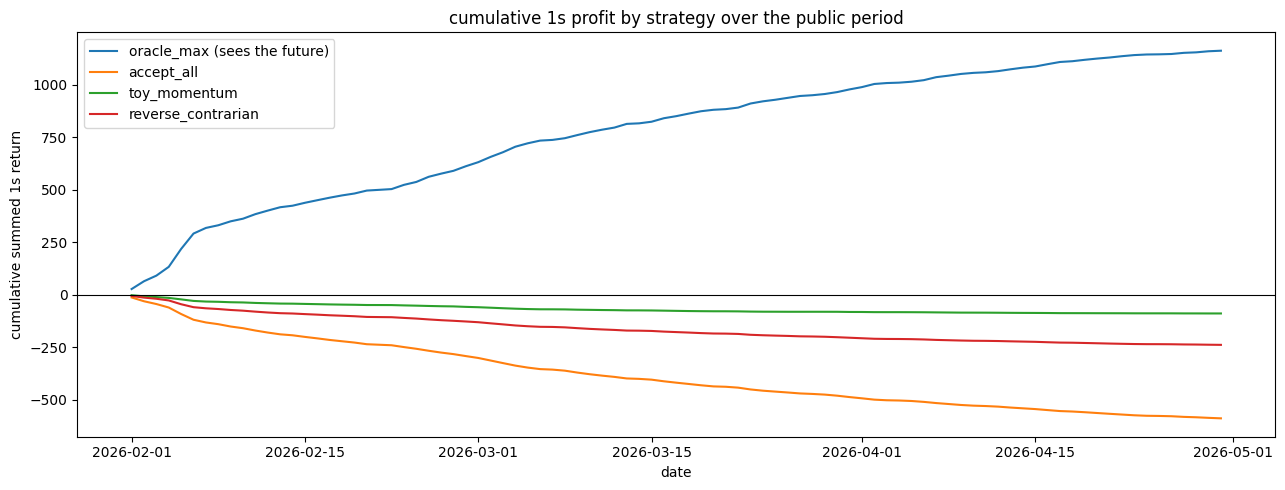

,strategy,month,selected,sum_profit_1s,avg_bps,p90_bps
0,oracle_max,202602,2466114,611.548618,2.479807,4.829751
1,oracle_max,202603,1783304,365.982903,2.052274,3.579952
2,oracle_max,202604,954427,184.229274,1.930261,3.535235
3,reverse_contrarian,202602,2853002,-127.873181,-0.448206,2.413127
4,reverse_contrarian,202603,2036681,-77.363843,-0.379853,1.226242
5,reverse_contrarian,202604,1080489,-33.993565,-0.314613,1.203659
6,toy_momentum,202602,2761321,-58.305560,-0.211151,2.517306
7,toy_momentum,202603,2000008,-24.234308,-0.121171,2.222716
8,toy_momentum,202604,1045222,-7.122010,-0.068139,1.246261


In [9]:
# A few baselines before any model, just to know what I'm aiming at. The score of any rule is
# the summed return over the trades it takes, sum_{x in A} pi(x), with pi(x) =
# profit_1s_with_rebate. I build a few choices of the taken set A and compare their sums.
import numpy as np
import pandas as pd

# pi(x) for every trade, as a plain numpy array (pulled once so the helper doesn't recopy millions of rows).
ret_np    = samples["profit_1s_with_rebate"].to_numpy()
# each trade's month label "YYYYMM" (first 6 chars of its "YYYYMMDD" date), used to group by month.
month_arr = samples["date"].str[:6].to_numpy()

# Helper: score one rule. Given a boolean mask A (take = True), group the taken trades by month
# and report, per month: how many were taken, the summed return sum pi (the real score), the mean
# return in bps (mean pi * 1e4), and the 90th percentile in bps. Same code scores every rule.
def strategy_stats(selected_mask, name):
    # force a numpy bool array so it can index ret_np / month_arr
    m = np.asarray(selected_mask)
    # the taken returns ret_np[m], grouped by their month month_arr[m]
    g = pd.Series(ret_np[m]).groupby(month_arr[m])
    out = pd.DataFrame({
        "selected":      g.size(),                      # |A_month|: count of taken trades
        "sum_profit_1s": g.sum(),                       # sum_{x in A_month} pi(x): the score
        "avg_bps":       g.mean() * 1e4,                # mean pi over the month, *1e4 -> bps
        "p90_bps":       g.quantile(0.9) * 1e4,         # 90th percentile of pi, *1e4 -> bps
    }).reset_index(names="month")
    # tag each row with the rule's name so several rules stack into one table
    out.insert(0, "strategy", name)
    return out

# the one feature the starter hands me: SOL's mid drift over the second before the cutoff,
# i.e. Delta(x) as a normalized return (the sol_mid_move_1s_bps of the toy-strategy note above).
sig = samples["sol_mid_move_1s_bps"]
# our maker side: dir = "bid" means our resting buy got hit (a long) (the agressor sell)
is_bid = samples["dir"] == "bid"
# dir = "ask" means our resting sell got hit (a short)
is_ask = samples["dir"] == "ask"
# momentum: take when the recent drift points our way (long after an up-move, short after a down-move)
toy_sel = (is_bid & (sig > 0.0)) | (is_ask & (sig < 0.0))
# contrarian: the exact opposite mask, only there to check momentum has the right sign
rev_sel = (is_bid & (sig < 0.0)) | (is_ask & (sig > 0.0))
# oracle: take exactly the winners, pi(x) > 0. This cheats (pi looks 1s ahead);
oracle_sel = samples["profit_1s_with_rebate"] > 0

# score the three rules and stack them, sorted by rule then month
strat = pd.concat([
    strategy_stats(oracle_sel, "oracle_max"),
    strategy_stats(toy_sel, "toy_momentum"),
    strategy_stats(rev_sel, "reverse_contrarian"),
], ignore_index=True).sort_values(["strategy", "month"]).reset_index(drop=True)

# total over the whole period for each rule (sum of its per-month sums).
print("=== score ladder (total Feb-Apr) ===")
# accept_all takes every trade, so its score is just the grand total sum_x pi(x)
print(f"accept_all        : {ret_np.sum():12.3f}")
# each rule's total = sum of its monthly sum_profit_1s, with the count it took
for name, g in strat.groupby("strategy"):
    print(f"{name:<18}: {g['sum_profit_1s'].sum():12.3f}   (selected {int(g['selected'].sum()):,})")

# Same rules as a picture: each line is the running total of a rule's selected return, day by day.
import matplotlib.pyplot as plt

# map each row's date to an integer day index 0..88 (codes), and list the 89 unique dates
codes, date_uniques = pd.factorize(samples["date"], sort=True)
# the unique dates as a calendar x axis
days = pd.to_datetime(date_uniques, format="%Y%m%d")
# number of distinct days
n_days = len(date_uniques)

# equity curve of a rule: contrib_x = pi(x) if taken else 0, summed per day (bincount),
# then accumulated across days (cumsum).
def daily_cum(mask):
    contrib = np.where(np.asarray(mask), ret_np, 0.0)
    return np.bincount(codes, weights=contrib, minlength=n_days).cumsum()

# the four rules to draw (accept_all = take everything = an all-True mask)
strategies = {
    "oracle_max (sees the future)": oracle_sel,
    "accept_all":                   np.ones(len(samples), dtype=bool),
    "toy_momentum":                 toy_sel,
    "reverse_contrarian":           rev_sel,
}
fig, ax = plt.subplots(figsize=(13, 5))
# one equity curve per rule
for name, mask in strategies.items():
    ax.plot(days, daily_cum(mask), lw=1.5, label=name)
# break-even line at 0
ax.axhline(0, color="black", lw=0.8)
ax.set_title("cumulative 1s profit by strategy over the public period")
ax.set_xlabel("date")
ax.set_ylabel("cumulative summed 1s return")
ax.legend(loc="upper left")
plt.tight_layout()
plt.show()

# the per-month detail table
strat


What I take from these results: momentum loses far less than its contrarian mirror and far less than accept-all, so the recent move already has the right sign, but it is still under 0... so deciding not to trade is better haha. 

The oracle sits at +1162 while every rule I naively tried actually run is < 0... and you can see it straight away in the four graphed lines: the oracle just runs off up top, my rules slide under zero, and they all flatten out by April since there is less and less to grab each month.

Now I want to understand the losses, because with this in mind avoiding bad trades looks at least as (if not more) valuable as catching good ones. I look at three things, matching the code below: (A) whether the losses are a few big disasters or lots of small cuts, (B) what the very worst trades look like, and (C) which days were the worst.

winners 5,203,845  total +1,161.8  avg +2.23 bps
losers  7,762,974  total -1,751.0  avg -2.26 bps
losers / winners ratio = 1.49


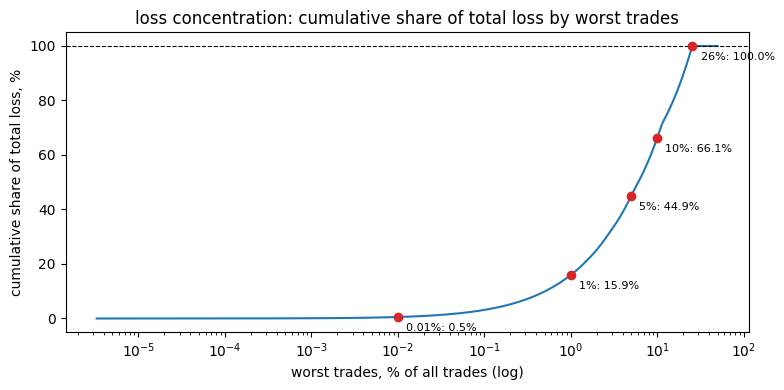

worse than -20 bps (7,114): -18.4  = 1.1% of all losses

=== trades worse than -100 bps (13) ===
    date                     utc dir  price  volume  sol_mid_move_1s_bps         bps
20260425 2026-04-25 00:00:08.186 bid  86.13    0.09             0.000000 -199.698131
20260331 2026-03-31 09:53:38.737 bid  81.47    0.11            -1.227220 -123.972014
20260331 2026-03-31 09:53:38.443 bid  81.47    8.90            -1.227220 -120.289677
20260331 2026-03-31 09:53:38.684 bid  81.47    2.15            -1.227220 -120.289677
20260331 2026-03-31 09:53:38.871 bid  81.47    0.65            -1.227220 -119.062231
20260331 2026-03-31 09:53:39.151 bid  81.47    0.25             0.000000 -110.470112
20260331 2026-03-31 09:53:39.217 bid  81.47    1.22             0.000000 -110.470112
20260331 2026-03-31 09:53:39.420 bid  81.47   87.19             0.000000 -106.787775
20260313 2026-03-13 14:00:42.690 ask  92.05    0.12             1.086543 -104.291146
20260327 2026-03-27 10:37:21.654 bid  84.80    0.22  

In [10]:
# Where do the losses come from? I ask three things below:
# (A) are they a few big disasters or lots of small cuts, (B) what do the single worst
# trades look like, and (C) which days were the worst.
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# work on a copy so the added column doesn't touch the cached samples
d = samples.copy()
# profit in basis points, bps = pi * 1e4 (easier to read than the raw fraction)
d["bps"] = d["profit_1s_with_rebate"] * 1e4
# N = total number of trades
N = len(d)
# pi(x) for every trade, the raw returns
ret = d["profit_1s_with_rebate"]
# total_pos = sum of pi over the winners (pi > 0): everything the winners made
total_pos = ret[ret > 0].sum()
# total_neg = sum of pi over the losers (pi < 0): everything the losers lost (negative)
total_neg = ret[ret < 0].sum()
# counts of winners and losers
n_win = int((ret > 0).sum())
n_los = int((ret < 0).sum())
# winners: count, summed return, and average in bps (total_pos / n_win * 1e4)
print(f"winners {n_win:,}  total +{total_pos:,.1f}  avg {total_pos / n_win * 1e4:+.2f} bps")
# losers: same three numbers
print(f"losers  {n_los:,}  total {total_neg:,.1f}  avg {total_neg / n_los * 1e4:+.2f} bps")
# how many losers per winner
print(f"losers / winners ratio = {n_los / n_win:.2f}")

# (A) Loss concentration: rank every trade worst-first and plot the cumulative share of the total
# loss against the fraction of trades, out to the worst 50%; the labelled dots give the exact
# share at a few percentiles.
ret_sorted = np.sort(ret.to_numpy())                  # all pi, most negative first
cum_loss = np.cumsum(ret_sorted) / total_neg          # cumulative loss share; reaches 1 at the last loser
# log-spaced ranks out to the worst 50% of trades (the loss plateaus at 100% past the losers, ~26%)
idx = np.unique(np.geomspace(1, int(N * 0.5), 600).astype(int)) - 1
plt.figure(figsize=(8, 4))
plt.plot((idx + 1) / N * 100, cum_loss[idx] * 100, "-")
plt.xscale("log")
# mark a few percentiles worst-first and label their cumulative share
for q in [0.0001, 0.01, 0.05, 0.10, n_los / N]:
    k = int(N * q)
    y = cum_loss[k - 1] * 100
    plt.scatter(q * 100, y, color="tab:red", zorder=3)
    plt.annotate(f"{q*100:.2g}%: {y:.1f}%", (q * 100, y), textcoords="offset points", xytext=(6, -10), fontsize=8)
plt.axhline(100, color="black", lw=0.8, ls="--")      # all the loss, reached at the loser share (~26%)
plt.title("loss concentration: cumulative share of total loss by worst trades")
plt.xlabel("worst trades, % of all trades (log)")
plt.ylabel("cumulative share of total loss, %")
plt.tight_layout(); plt.show()
# trades worse than -20 bps (pi < -20 bps), the blow-ups by value not by rank
blow = ret[d["bps"] < -20]
print(f"worse than -20 bps ({len(blow):,}): {blow.sum():.1f}  = {blow.sum() / total_neg:.1%} of all losses")

# (B) The single worst trades: every trade worse than -100 bps (a 1% loss in one second).
worst = d[d["bps"] < -100].sort_values("bps")         # worst first
# turn their server_time (microseconds since epoch) into a readable UTC timestamp
worst["utc"] = pd.to_datetime(worst["server_time"], unit="us")
print(f"\n=== trades worse than -100 bps ({len(worst)}) ===")
# show only the columns that matter for spotting a pattern
print(worst[["date", "utc", "dir", "price", "volume", "sol_mid_move_1s_bps", "bps"]].to_string(index=False))

# (C) The worst days: every day that loses more than twice the median daily return.
# per day: count of trades, summed pi (the accept-all daily score), and the single worst bps
day = d.groupby("date").agg(
    n=("bps", "size"),
    sum_profit=("profit_1s_with_rebate", "sum"),
    worst_bps=("bps", "min"),
)
# add a column: how many trades that day were below -20 bps (count of the indicator pi < -20 bps)
day["n_below_m20bps"] = d.assign(x=d["bps"] < -20).groupby("date")["x"].sum().astype(int)
# threshold = twice the median daily summed return; keep the days below it, worst first
thr = 2 * day["sum_profit"].median()
bad = day[day["sum_profit"] < thr].sort_values("sum_profit")
print(f"\n=== days worse than 2x the median day ({thr:.1f}): {len(bad)} of {len(day)} ===")
print(bad.to_string())

So there is approximatively 3 bad trade for 2 good ones.

Now, what the losses tell me, going (A) to (C):

(A) it is not a few disasters, but it is not an even bleed either. There is no single fat outlier: the worst 0.01% of trades carry only 0.5%, so clipping a handful does nothing. But the loss is concentrated in the worst tail: the worst 5% of trades carry 45% of the loss, the worst 10% two thirds. (I read that off the labelled points, not the curve shape.) The x-axis is log, so a perfectly even bleed would itself look like a convex, exponential curve, and only the level tells me how concentrated the loss is. So I can't avoid a few trades my way out. The model has to constantly avoid a broad worst-tail.

(B) the very worst single trades (the 13 worse than -100 bps, a full 1% lost in a second) are all the same picture: a resting bid getting run over while the price falls off a cliff (the 81.47 cluster on 31 Mar, the lone -200 bps on 25 Apr) or an ask caught in a spike. They come in bursts, same second, same price, and the trailing move on them is often ~0, so the damaging move happened inside the 10 ms gap, where my backward feature can't see it.

(C) the worst days (the ones losing more than twice the median day) are basically all early February: the whole first week, plus the 2nd to 4th of March. That is also where the big losers pile up (about 1500 trades below -20 bps on the 6th alone). Feb seem the most volatile month among the 3: only 46% of fills are flat in Feb vs 58% in March and 71% in April (that flat share is the zero_pct column of the monthly summary up top), so prices move a lot more. So a few rough days carry a big slice of the early bleed. I wouldn't just skip high-vol days though, that's where the most money is too (the oracle makes 611 in Feb vs 184 in April), so the model should be pickier there, not absent.

Conclusion? There is no fat outlier to skip, the loss is concentrated in a broad worst-tail (no single fat outlier, but the worst 5% carry about half), and a model not only needs to dodge a handful of disasters but also kinda constantly win in the middle. A chunk of the worst hits also show flat trailing momentum. This means the move happened in the latency gap. So with what I have, I am blind to them.

A question that stands on its own, and really the one the model faces. The previous check on the losses above looked back from the trades that already lost and asked what they had in common. The model never gets to do that. It sees a trade first, then has to guess. So I turn it around. I take the two things I will know at the cutoff, the trade size and how much the price had just moved, and bucket every trade by each one. Mechanically I just tag each trade with a bucket number, then average the profit of all trades that share a tag. Every trade gets a tag, there is no filter.

The two features get tagged differently. For size I want the same number of trades in each bucket: line all trades up smallest to largest by size, cut into 10 equal piles of trades (each pile is a "decile"), and tag them 0 to 9.

For the move I want fixed value cutoffs instead. The flat second (move = 0) gets its own bucket, then the rest split by how big the move (unsigned) was: 0 to 1.5, 1.5 to 2.5, 2.5 to 4.5, 4.5 to 8, above 8 bps. So it's the other way round from the size split. There I keep the counts equal and let the bucket widths vary. Here I fix the cut points and let the counts vary.

The average in each bucket is the thing we are trying to grow. Depending on the tag this means respectively: by size, the average profit of all trades of about the same size (one size decile); by move, the average profit of all trades whose last second moved about the same amount (one move band, with the flat second on its own). Either way it's just the average profit conditional on that one feature. If this average bends, that feature "sorts" trades in some way (bad from good, good from bad), so it's worth keeping. I show the win rate too. The win rate is just the fraction of a bucket's trades that end above zero. The flat and losing trades still sit in that total. So the win rate counts how often I land above zero. While our above average counts how much. It is possible that one of the average goes up while the other goes down: I can win more often but lose bigger when I am wrong (for e.g.), so that the average still drops.

=== mean 1s profit by trade size (deciles) ===
   med_size  mean_bps
b                    
0     0.060    -0.231
1     0.080    -0.188
2     0.120    -0.345
3     0.200    -0.123
4     0.470    -0.021
5     1.000    -0.037
6     2.190    -0.080
7     5.000    -0.130
8    12.000    -0.334
9    45.540    -0.444

=== mean 1s profit by recent |move| (flat, then by size of the move) ===
                n  mean_bps  win_pct
0        18560911    -0.140    0.123
0-1.5     6393706    -0.243    0.213
1.5-2.5   2453883    -0.287    0.254
2.5-4.5   1685458    -0.330    0.295
4.5-8      954888    -0.373    0.338
>8         288788    -0.410    0.399


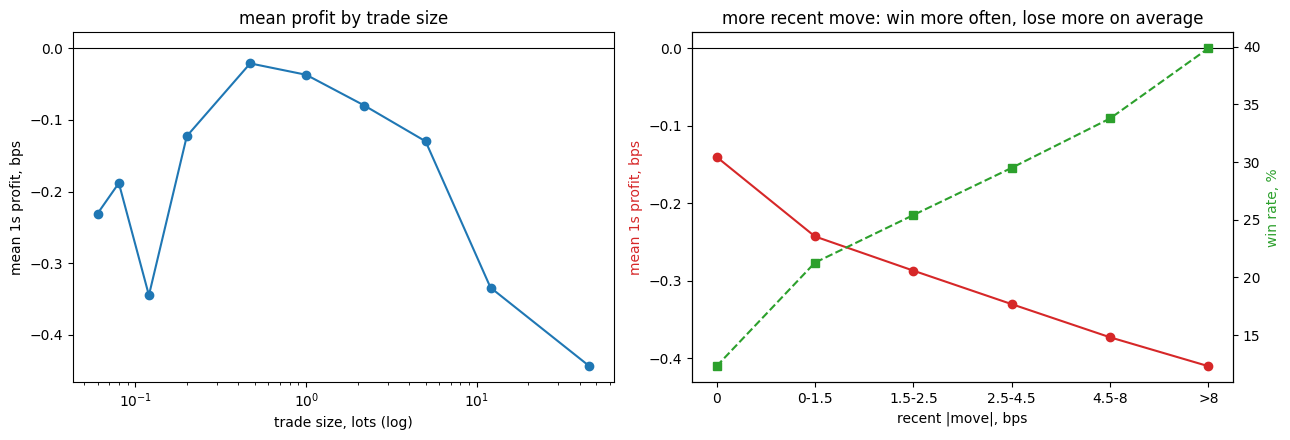

In [11]:
# Turn the loss question around: instead of looking back from the losers, bin every trade by
# the two things known at the cutoff and look at the MEAN 1s profit per bucket (the objective).
# The win rate is shown too.
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# pi(x) in basis points, bps = pi * 1e4
bps = samples["profit_1s_with_rebate"].to_numpy() * 1e4
# win indicator, 1[pi > 0]: did the trade make money
win = (samples["profit_1s_with_rebate"] > 0).to_numpy()
# trade size (volume), one of the two cutoff-known features
vol = samples["volume"].to_numpy()
# recent volatility gauge: |Delta|, the absolute trailing 1s move, the other cutoff-known feature
mv  = samples["sol_mid_move_1s_bps"].abs().to_numpy()

# Tags
# By size: cut vol into 10 equal-count buckets (deciles), tag from 0 to 9; equal counts, varying width.
vbin = pd.qcut(vol, 10, labels=False, duplicates="drop")
# per size bucket: the median size (x in the plot) and mean_bps = E[pi | bucket] * 1e4
vt = (pd.DataFrame({"b": vbin, "bps": bps, "vol": vol})
        .groupby("b").agg(med_size=("vol", "median"), mean_bps=("bps", "mean")))

# By recent move: the value piles up at exactly 0 (the second was flat), so 0 gets its own
# bucket, then the moving trades are split by the size of the move with fixed bps cut points.
# (Equal-count bins fail here: with most of the mass on the single value 0, qcut's lower quantile
# edges all land on 0 and collapse, so it can't make equal piles.)
# fixed cut points for the moving trades, in bps
edges  = [1.5, 2.5, 4.5, 8.0]
# names of the 6 buckets: the flat one, then the four bands, then the tail
labels = ["0", "0-1.5", "1.5-2.5", "2.5-4.5", "4.5-8", ">8"]
# start every trade in bucket 0 (no move)
mbin = np.zeros(len(mv), dtype=int)
# moving trades (mv > 0): digitize against edges gives 0..4, +1 puts them in buckets 1..5
mbin[mv > 0] = 1 + np.digitize(mv[mv > 0], edges)
# per move bucket: count n, mean_bps = E[pi | bucket] * 1e4, and win_pct = mean of the win
# indicator over the bucket = the fraction of its trades with pi > 0 (flats and losers stay in the total).
mt = (pd.DataFrame({"b": mbin, "bps": bps, "win": win})
        .groupby("b").agg(n=("bps", "size"), mean_bps=("bps", "mean"), win_pct=("win", "mean")))
# relabel the integer buckets 0..5 with their readable names
mt.index = [labels[i] for i in mt.index]

print("=== mean 1s profit by trade size (deciles) ===")
print(vt.to_string(float_format=lambda v: f"{v:.3f}"))
print("\n=== mean 1s profit by recent |move| (flat, then by size of the move) ===")
print(mt.to_string(float_format=lambda v: f"{v:.3f}"))

# two panels side by side
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.5))

# left: the size smile, mean_bps vs median size
ax1.plot(vt["med_size"], vt["mean_bps"], "o-")
# zero line (break-even)
ax1.axhline(0, color="black", lw=0.8)
# size spans decades, so use a log x axis
ax1.set_xscale("log")
ax1.set_title("mean profit by trade size")
ax1.set_xlabel("trade size, lots (log)")
ax1.set_ylabel("mean 1s profit, bps")

# right: the recent-move paradox (mean profit falls while win rate climbs)
# evenly spaced x positions for the 6 named buckets
xi = np.arange(len(mt))
# red: mean_bps per move bucket
ax2.plot(xi, mt["mean_bps"], "o-", color="tab:red")
ax2.axhline(0, color="black", lw=0.8)
ax2.set_title("more recent move: win more often, lose more on average")
ax2.set_xlabel("recent |move|, bps")
ax2.set_ylabel("mean 1s profit, bps", color="tab:red")
# label the x ticks with the bucket names
ax2.set_xticks(xi); ax2.set_xticklabels(mt.index)
# second y axis sharing the x, for the win rate
ax2b = ax2.twinx()
# green: win_pct per bucket, in percent
ax2b.plot(xi, mt["win_pct"] * 100, "s--", color="tab:green")
ax2b.set_ylabel("win rate, %", color="tab:green")

plt.tight_layout()
plt.show()

Two things come out, both about the mean 1s profit in each bucket. By size it is an inverted smile: least bad (closest to zero) for middling trades, worse for the very small, worst for the very large. By recent move it is a paradox: the more the price had just moved, the more often I win, yet the worse I do on average. So a busy moment is not free money. It swings harder both ways, and the bad side wins. In the end both features say the same thing. They flag when it is risky, not which way to bet. That helps with caution, but I still need a feature that points a direction. So I need to think of something else...

Another thing I can watch: we also have BTC and ETH.

The question: does BTC or ETH move before SOL? This is a reasonable guess because they are the big, liquid coins, so the price probably moves there first and the smaller ones follow. If one leads SOL it is an early warning my own momentum feature can't give me, since that only looks back at SOL.

I put all three on a shared 50 ms clock, over every public day. I use 50 ms because, as printed earlier, all three books strobe at about 53 ms, so 50 ms is the finest clock they can share. A finer grid would just repeat the same stale mid. The clock is a set of grid points $u_t$ spaced 50 ms apart, and a bar $t$ is one step, from $u_t$ to $u_{t+1}$. At each grid point I read the mid the causal way, the as-of mid $m^{\leftarrow,X}$ from the concepts cell (the last snapshot at or before the point). So the bar-$t$ return is the as-of log-return
$$r_X^{\leftarrow}[t] = \log m^{\leftarrow,X}(u_{t+1}) - \log m^{\leftarrow,X}(u_t).$$
To compare two coins I take the Pearson correlation of these series over all bars $t$, pooled across days,
$$\rho_X(k) = \mathrm{corr}\big(r_X^{\leftarrow}[t],\ r_{\mathrm{SOL}}^{\leftarrow}[t+k]\big).$$
The correlation runs over $t$, so $t$ averages out and $\rho_X$ depends on the lag $k$ alone. It is coin $X$'s return now against SOL's return $k$ bars later.

On that clock I check two things. First, do they move together at the same time: that is just $\rho_X(0)$ (the two returns in the same bar). Second, does a coin move first: I scan $\rho_X(k)$ over the lag $k$ and see which $k$ matches best (the peak). Here $k>0$ means coin $X$ moved first. A peak at a positive lag (one bar or more, so ≥ 50 ms) is a real lead. It is more than the 10 ms latency, so it is tradable. A peak at zero is just simultaneous movement, and I can't act on that.

The book cleaning is already handled once in the helper cell: `load_book` drops the 9999999999 sentinel and the other bad rows, so here I just call it and work on clean books.

days=89  bars~153,778,666
same-bar corr:  SOL-BTC=0.295   SOL-ETH=0.304
BTCUSDT: peak 0.295 at +0 bars (+0 ms);  +1 bar (50 ms)=0.162
ETHUSDT: peak 0.304 at +0 bars (+0 ms);  +1 bar (50 ms)=0.168


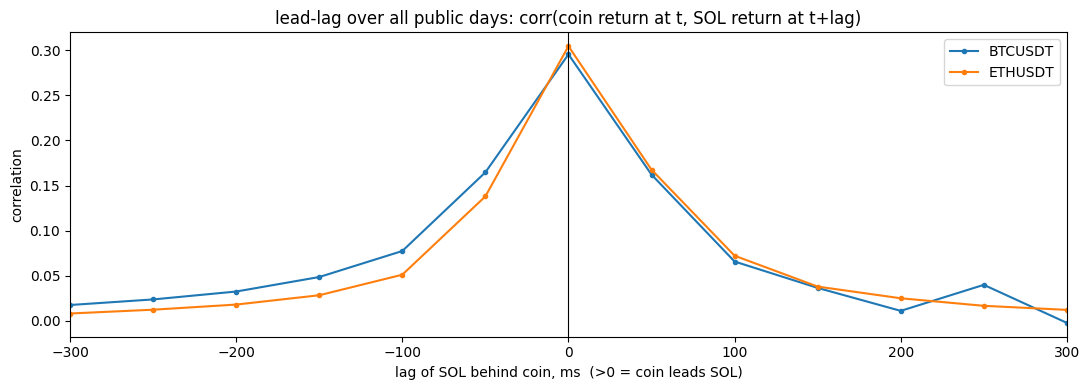

In [12]:
# Cross-asset: do BTC/ETH lead SOL? Over EVERY public day, put the three coins on a shared
# 50 ms clock, then measure (a) same-bar movement and (b) the lead-lag: corr of a coin's
# return at t vs SOL's at t+k, over multiple k. Peak at k>0 (>=1 bar = 50 ms) is a real, tradable
# lead; peak at k=0 is just simultaneous movement. Each grid mid is the last snapshot <= the
# grid point (asof), so it stays past-data only. Streamed day by day, accumulating per-lag sums, so
# memory stays flat over the 89 days. Uses the shared toolbox: load_book / asof.
import numpy as np, pandas as pd
import matplotlib.pyplot as plt

XA_SYMS = ["SOLUSDT", "BTCUSDT", "ETHUSDT"]                 # SOL is the one we compare the others against
XA_DAYS = sorted(p.name[:8] for p in (MARKET_DATA_PATH / "SOLUSDT").glob("*_orderbook_10.parquet"))
XA_STEP_US = 50_000                                        # 50 ms; as printed earlier all three books strobe ~53 ms, so this is the finest shared grid
LAGS = np.arange(-6, 7)                                    # lags to scan, bars: -6..+6 = +-300 ms
ZERO = int(np.where(LAGS == 0)[0][0])                      # index of k=0 in LAGS

# (server_time, log mid) for one coin-day; the shared book filter via the toolbox loader.
def _logmid(sym, day):
    b = load_book(sym, day, size_levels=1)
    return b.server_time.to_numpy(), np.log((b.bid_price_1.to_numpy() + b.ask_price_1.to_numpy()) / 2)

# 50 ms log-mid returns per coin on a shared grid, for one day.
def _day_rets(day):
    m = {s: _logmid(s, day) for s in XA_SYMS}
    # shared window: start at the latest first-snapshot, end at the earliest last-snapshot
    g0 = max(st[0] for st, _ in m.values()); g1 = min(st[-1] for st, _ in m.values())
    grid = np.arange(g0, g1, XA_STEP_US)                   # the shared 50 ms grid points
    # per coin: sample the log mid at the last snapshot <= each grid point (asof), then diff -> 50 ms return
    return {s: np.diff(asof(st, lm, grid)) for s, (st, lm) in m.items()}

# Pooled Pearson per lag, accumulated across days (running sums, no big arrays kept).
# corr( coin[t], SOL[t+k] ); k>0 means the coin leads SOL by k bars.
acc = {s: {m: np.zeros(len(LAGS)) for m in ("n", "x", "y", "xy", "xx", "yy")}
       for s in ("BTCUSDT", "ETHUSDT")}
for day in XA_DAYS:
    r = _day_rets(day); sol = r["SOLUSDT"]
    for s in ("BTCUSDT", "ETHUSDT"):
        c, A = r[s], acc[s]
        for i, k in enumerate(LAGS):
            # align a = r_X[t] with b = r_SOL[t+k], sliced within the day so no pair crosses midnight.
            a, b = (c[:len(c) - k], sol[k:]) if k >= 0 else (c[-k:], sol[:len(sol) + k])
            A["n"][i] += a.size; A["x"][i] += a.sum(); A["y"][i] += b.sum()
            A["xy"][i] += a @ b; A["xx"][i] += a @ a; A["yy"][i] += b @ b

# six running sums -> Pearson r per lag.
def pearson(s):
    A = acc[s]; n = A["n"]
    return (n * A["xy"] - A["x"] * A["y"]) / np.sqrt((n * A["xx"] - A["x"]**2) * (n * A["yy"] - A["y"]**2))

cc = {s: pearson(s) for s in ("BTCUSDT", "ETHUSDT")}
print(f"days={len(XA_DAYS)}  bars~{int(acc['BTCUSDT']['n'][ZERO]):,}")
print(f"same-bar corr:  SOL-BTC={cc['BTCUSDT'][ZERO]:.3f}   SOL-ETH={cc['ETHUSDT'][ZERO]:.3f}")
for s in ("BTCUSDT", "ETHUSDT"):
    kb = int(LAGS[np.argmax(cc[s])])
    print(f"{s}: peak {cc[s].max():.3f} at {kb:+d} bars ({kb*XA_STEP_US//1000:+d} ms);  +1 bar (50 ms)={cc[s][ZERO+1]:.3f}")

fig, ax = plt.subplots(figsize=(11, 4))
for s in ("BTCUSDT", "ETHUSDT"):
    ax.plot(LAGS * XA_STEP_US / 1000, cc[s], "o-", ms=3, label=s)
ax.axvline(0, color="black", lw=0.8)
ax.set_xlim(-300, 300)                                     # central +-300 ms; markers at the 50 ms strobe spacing
ax.set_title("lead-lag over all public days: corr(coin return at t, SOL return at t+lag)")
ax.set_xlabel("lag of SOL behind coin, ms  (>0 = coin leads SOL)")
ax.set_ylabel("correlation")
ax.legend()
plt.tight_layout(); plt.show()

So, no. Neither leads.

Both curves peak at lag 0: in the same bar SOL-BTC is 0.295 and SOL-ETH 0.304 (the same-bar corr printed above), and that is the top of each curve. By +1 bar (50 ms) they are already down to 0.162 and 0.168, and the plot falls off the same way on the other side. So the hump sits on 0. It is not shifted to a positive lag.

That is not positive for us (as explained earlier).

So cross-asset is a co-move but not a lead. The correlation is about 0.30 at the same instant, it is just simultaneous so I cannot bet a direction on it. I am still looking for a feature that points a way.

Another idea: momentum is backward-looking. The book imbalance is a number between −1 and 1 that says how much resting size sits on the bid versus the ask. It is more of a forward-looking feature, and I know it at the cutoff. It might predict the imminent move, and in particular cover the blind spot where momentum is flat (where my own trailing feature saw nothing).

Formally, the book imbalance of coin $X$ over its top $k$ levels is
$$I_k^X = \frac{\sum_{i \le k} V^X_{b,i} - \sum_{i \le k} V^X_{a,i}}{\sum_{i \le k} V^X_{b,i} + \sum_{i \le k} V^X_{a,i}} \in [-1, 1],$$
summing the resting sizes ($V^X_{b,i}, V^X_{a,i}$ from the concepts cell) over levels $1$ to $k$. Positive means more size resting on the bid, so upward pressure. On SOL I try three depths: the touch $I_1^{\mathrm{SOL}}$ (level 1 alone), then $I_5^{\mathrm{SOL}}$ and $I_{10}^{\mathrm{SOL}}$ (summed over the top 5 and top 10 levels). The deeper ones are really for the second, harder problem where I also trade past the touch. I read each as-of at the cutoff and sign it by my side, so a positive value leans my way (0 is balanced, 1 is everything on my side). I write the signed fill-level feature, for any coin $X$, as $I_i^X(x) := \sigma(x)\, I_i^{\leftarrow,X}(c(x))$: the fill argument $x$ and the folded sign $\sigma(x)$ mark it as the signed feature, distinct from the unsigned book $I_i^X$. On SOL it is $I_i^{\mathrm{SOL}}(x)$, on BTC $I_i^{\mathrm{BTC}}(x)$, and so on. The samples file dropped the sizes, so `load_book` re-reads them from the raw order book (its filter drops the session sentinels and the one-sided 9999999999 rows) and `asof` takes the last snapshot at or before each cutoff, so I stay causal.

I also compute the microprice minus the mid. For coin $X$ the microprice is the size-weighted mid, $M^X = (P^X_{b,1} V^X_{a,1} + P^X_{a,1} V^X_{b,1})/(V^X_{b,1} + V^X_{a,1})$. With the spread $s^X = P^X_{a,1} - P^X_{b,1}$ and the level-1 imbalance $I_1^X$ (the $k = 1$ case above), putting it over $2(V^X_{b,1} + V^X_{a,1})$:

$$M^X - m^X = \frac{P^X_{b,1} V^X_{a,1} + P^X_{a,1} V^X_{b,1}}{V^X_{b,1} + V^X_{a,1}} - \frac{P^X_{a,1} + P^X_{b,1}}{2} = \frac{(V^X_{b,1} - V^X_{a,1})(P^X_{a,1} - P^X_{b,1})}{2(V^X_{b,1} + V^X_{a,1})} = \frac{s^X}{2}\, I_1^X.$$

So the microprice minus the mid is exactly the half-spread $s^X/2$ times the level-1 imbalance. It points the same way as imbalance, just weighted by the spread. I compute it on SOL to see whether that weighting helps.

Then the test, the same binning as the size and move features earlier. I sort every trade by the signed feature and cut into ten equal piles (deciles): pile 0 is the tenth of trades where the signed imbalance was most against me, pile 9 the tenth where it was most in my favor. So the piles run from the most-negative signed value up to the most-positive. In each pile I take the mean 1s profit. If that mean is flat across the piles, the feature tells me nothing. If it climbs from pile 0 to pile 9, then the more the book favored my side the more I made on average. That lines the trades up from worst to best. That is the sorting I want.

It is even better still if the top piles cross above zero while the bottom ones stay below: then taking the high-imbalance trades and skipping the low ones already makes money on its own!

I show the win rate too. I look hardest at the trades where momentum was flat, since that is the blind spot I am trying to cover.

aligned samples: 30,337,634   baseline mean = -0.194 bps
corr(imb1_signed, profit_bps) = +0.203
corr(imb5_signed, profit_bps) = +0.102
corr(imb10_signed, profit_bps) = +0.065
corr(micro_signed, profit_bps) = +0.201

=== mean 1s profit by signed imbalance decile, per depth (>0 = book in my favor) ===

-- imb1_signed --
         n  mean_bps  win_pct
f                            
0  3033764    -0.983    8.939
1  3033763    -0.654    9.513
2  3033763    -0.446   10.989
3  3033764    -0.304   12.092
4  3033763    -0.197   13.749
5  3033763    -0.092   15.802
6  3033764     0.004   18.036
7  3033763     0.099   21.083
8  3033763     0.222   26.045
9  3033764     0.407   35.283

-- imb5_signed --
         n  mean_bps  win_pct
f                            
0  3033764    -0.583   14.240
1  3033763    -0.427   13.258
2  3033763    -0.334   13.714
3  3033764    -0.264   14.411
4  3033763    -0.201   15.271
5  3033763    -0.150   16.218
6  3033764    -0.095   17.445
7  3033763    -0.038   19.089
8

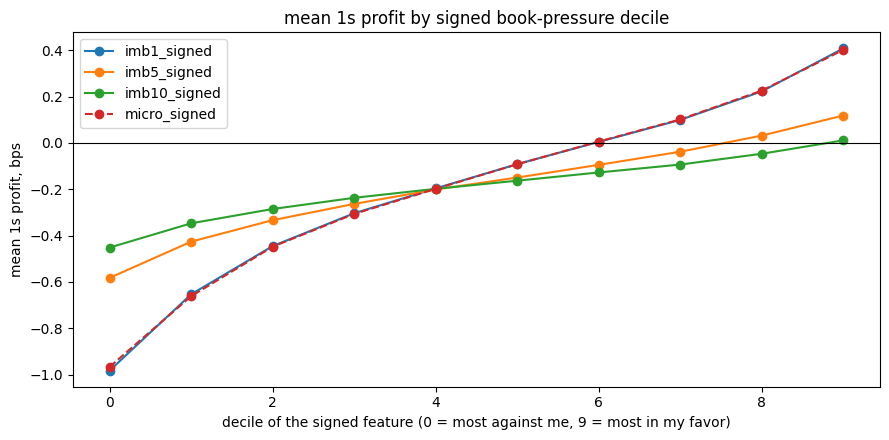

In [13]:
# Book imbalance and microprice at the cutoff, over all 89 days. For each sample I attach the book
# pressure from the last snapshot at or before its cutoff (asof, causal), sign it by my side, then
# bin each signed feature into deciles (the same test as the size/move features) and read mean profit
# and win rate per decile. Uses the shared toolbox: load_book / asof / side_sign / corr / decile_profit.
import numpy as np, pandas as pd
import matplotlib.pyplot as plt

# imb1_of: unsigned L1 imbalance (bid_size_1 - ask_size_1)/(sum) for a loaded book; sign it by side at
# the sample. Defined here because this is where imbalance is introduced, and the later cells (TFI,
# cross-asset, the model) reuse it. This cell computes imb1/imb5/imb10 inline just below to compare depths.
def imb1_of(book):
    b1, a1 = book.bid_size_1.to_numpy(), book.ask_size_1.to_numpy()
    return (b1 - a1) / (b1 + a1)

IMB_BID = [f"bid_size_{i}" for i in range(1, 11)]           # imb1 uses L1, imb5 the top 5, imb10 the whole book
IMB_ASK = [f"ask_size_{i}" for i in range(1, 11)]
imb_samp = samples[["date", "events_before_server_time", "dir", "profit_1s_with_rebate", "sol_mid_move_1s_bps"]]
IMB_DAYS = sorted(samples["date"].unique())

# attach imb1, imb5, imb10 and microprice-mid (bps) to one day's samples, as of each cutoff.
def _imb_day(day):
    book = load_book("SOLUSDT", day, size_levels=10)        # server_time, L1 prices, all 10 size levels; filtered
    bt = book.server_time.to_numpy()
    b1, a1   = book.bid_size_1.to_numpy(), book.ask_size_1.to_numpy()
    b5, a5   = book[IMB_BID[:5]].sum(axis=1).to_numpy(), book[IMB_ASK[:5]].sum(axis=1).to_numpy()
    b10, a10 = book[IMB_BID].sum(axis=1).to_numpy(), book[IMB_ASK].sum(axis=1).to_numpy()
    mid   = (book.bid_price_1.to_numpy() + book.ask_price_1.to_numpy()) / 2
    micro = (book.bid_price_1.to_numpy() * a1 + book.ask_price_1.to_numpy() * b1) / (b1 + a1)
    series = {"imb1": (b1 - a1) / (b1 + a1), "imb5": (b5 - a5) / (b5 + a5),
              "imb10": (b10 - a10) / (b10 + a10), "micro_bps": (micro - mid) / mid * 1e4}
    s = imb_samp[imb_samp.date == day]
    c = s["events_before_server_time"].to_numpy()
    out = {"date": s["date"].to_numpy(), "dir": s["dir"].to_numpy(),
           "bps": s["profit_1s_with_rebate"].to_numpy() * 1e4,
           "sol_mid_move_1s_bps": s["sol_mid_move_1s_bps"].to_numpy()}
    for k, v in series.items(): out[k] = asof(bt, v, c)     # each sample: last book row at or before its cutoff
    return pd.DataFrame(out)

# stream all days, stack, drop samples with no valid book before their cutoff
res = pd.concat([_imb_day(d) for d in IMB_DAYS], ignore_index=True).dropna(subset=["imb1", "imb5", "imb10", "micro_bps"])
# sign each feature by my side: +1 long (bid), -1 short (ask), so >0 = book leans my way
sgn = side_sign(res["dir"])
res["imb1_signed"]  = res["imb1"]      * sgn
res["imb5_signed"]  = res["imb5"]      * sgn
res["imb10_signed"] = res["imb10"]     * sgn
res["micro_signed"] = res["micro_bps"] * sgn
print(f"aligned samples: {len(res):,}   baseline mean = {res['bps'].mean():.3f} bps")
for col in ("imb1_signed", "imb5_signed", "imb10_signed", "micro_signed"):
    print(f"corr({col}, profit_bps) = {corr(res[col], res['bps']):+.3f}")

# decile table per imbalance depth (micro is the same curve as imb1, so it stays out of the tables)
IMB_COLS = ["imb1_signed", "imb5_signed", "imb10_signed"]
print("\n=== mean 1s profit by signed imbalance decile, per depth (>0 = book in my favor) ===")
for col in IMB_COLS:
    print(f"\n-- {col} --")
    print(decile_profit(res[col], res["bps"]).to_string(float_format=lambda v: f"{v:.3f}"))

# the blind spot: only the trades where my trailing momentum was exactly 0
z = res[res["sol_mid_move_1s_bps"] == 0]
print(f"\n=== momentum==0 subset (n={len(z):,}, baseline {z['bps'].mean():.3f} bps), per depth ===")
for col in IMB_COLS:
    print(f"\n-- {col} (corr {corr(z[col], z['bps']):+.3f}) --")
    print(decile_profit(z[col], z["bps"]).to_string(float_format=lambda v: f"{v:.3f}"))

# plot: mean profit vs decile for the signed features
fig, ax = plt.subplots(figsize=(9, 4.5))
for col in ("imb1_signed", "imb5_signed", "imb10_signed", "micro_signed"):
    d = decile_profit(res[col], res["bps"])
    # micro_signed sits right on top of imb1_signed, so dash it to let imb1 show through underneath
    ax.plot(d.index, d["mean_bps"], "o--" if col == "micro_signed" else "o-", label=col)
ax.axhline(0, color="black", lw=0.8)
ax.set_title("mean 1s profit by signed book-pressure decile")
ax.set_xlabel("decile of the signed feature (0 = most against me, 9 = most in my favor)")
ax.set_ylabel("mean 1s profit, bps")
ax.legend()
plt.tight_layout(); plt.show()

Now this one works!

For the first time a feature makes mean profit climb monotone and drags the win rate up with it. The signed level-1 imbalance runs from −0.983 bps in the worst decile to +0.407 in the best, win rate 9% up to 35% (the $I_1^{\mathrm{SOL}}$ table above). It crosses zero at decile 6, so the top four deciles all make money on average. So this is not the |move| paradox: the book pressure does point a direction. Take the high-imbalance trades, skip the low ones, and I am already green.

The depth surprised me (maybe due to my inexperience even tough the question is said to be harder). I thought more levels would help, but it is the other way round: top of book is sharpest, deeper dilutes. The correlations are $I_1^{\mathrm{SOL}}$ +0.203, $I_5^{\mathrm{SOL}}$ +0.102, $I_{10}^{\mathrm{SOL}}$ +0.065 (printed above), so level 1 alone is twice $I_5^{\mathrm{SOL}}$ and $I_{10}^{\mathrm{SOL}}$ is the weakest. The decile spreads say the same: $I_1^{\mathrm{SOL}}$ runs −0.983 to +0.407, $I_5^{\mathrm{SOL}}$ only −0.583 to +0.118, $I_{10}^{\mathrm{SOL}}$ barely tilts at −0.452 to +0.011. For the 1-second move the edge sits right at the touch, and summing slower size deeper out just blurs it. So for this default problem $I_1^{\mathrm{SOL}}$ is the one to keep, not $I_5^{\mathrm{SOL}}$. (Deeper may earn its place on the harder deep-fills problem, I will check there.)

The microprice was no surprise once I had the formula. micro_signed is the dashed line sitting right on top of $I_1^{\mathrm{SOL}}$, with correlations +0.201 and +0.203. That is exactly micro − mid = (s/2) $I_1^{\mathrm{SOL}}$: same sign, just weighted by the spread. So the spread weighting buys me nothing here. micro beats $I_5^{\mathrm{SOL}}$, but only because micro is $I_1^{\mathrm{SOL}}$ in disguise.

The best part: it does not just survive the blind spot, it sharpens there. On the trades where my momentum was flat (61% of them, 18.56M), $I_1^{\mathrm{SOL}}$'s correlation rises to +0.245, above the +0.203 over everything. The deciles run −0.827 to +0.370, top four still positive. So imbalance sees what momentum can't, and sees it better.

It is a small edge in size (the best $I_1^{\mathrm{SOL}}$ decile is +0.407 bps). But it is the first real direction I have. So imbalance goes into the model as the directional signal, with volume and volatility kept for sizing the risk.

Now lets search for something else:

The book is a strobe. It only refreshes about every 53 ms (the gap I measured earlier). So every book feature, imbalance included, is blind to whatever moves between two snapshots. The trades feed is different. It is event-driven: one row per trade, stamped when the trade happened. So it is the one feed that can see inside a snapshot.

So the next feature is signed trade flow. Each trade prints which side aggressed: a buyer lifting the asks, or a seller hitting the bids. Over a window $(c(x)-w,\ c(x)]$ ending at the cutoff I sum the aggressor volume on coin $X$'s tape on each side, $\mathrm{buy}^X_w(x)$ and $\mathrm{sell}^X_w(x)$, and take

$$\mathrm{TFI}^X_w(x) = \frac{\mathrm{buy}^X_w(x) - \mathrm{sell}^X_w(x)}{\mathrm{buy}^X_w(x) + \mathrm{sell}^X_w(x)} \in [-1, 1].$$

Positive means net buying, so the aggressors were leaning the price up. Then I sign it by my side $\sigma(x)$ (the maker side), exactly like the imbalance: a maker bid (a long) keeps the sign, a maker ask (a short) flips it. The signed feature is $\sigma(x)\,\mathrm{TFI}^X_w(x)$. After that, positive always means the recent flow was pushing my way. Here I read SOL's own tape, so $X = \mathrm{SOL}$. I write $\mathrm{TFI}_w(x) := \mathrm{TFI}^{\mathrm{SOL}}_w(x)$.

What I expect, and the risk. Aggressive flow tends to keep going for a moment. Informed traders do not fire once (?), they keep pushing the same way. If that holds, flow leaning my way should mean the next second leans my way, so signed flow predicts the profit with a positive sign. The other tail is the danger I keep hitting. When the flow leans hard against me, someone is running through my resting side. That is the adverse selection that makes blind fills bleed. The counter-risk is mean reversion: a burst of buying pushes the price up now, but it goes too far and comes back down before the 1 s mark-out (the price one second after the fill, compared to the price I filled at). So if the price has come back down by then, flow that leaned my way actually leaves me worse off, and the correlation comes out negative. Continuation and reversion disagree on the sign. The decile table below decides: if mean profit climbs as the signed flow goes from against me to with me, continuation wins; if it falls, reversion does.

The window length is the real choice. The "sees inside the strobe" part is free: the feed is event-driven, so the flow reacts the instant a trade lands, whatever length I sum over. The window only trades freshness against stability. Too short and a ratio over one or two trades is noise. Too long and I am just re-measuring the trailing move I already have. So, like I did with book depth, I do not guess a length. I scan three, each a real clock in the problem: one strobe gap (~53 ms, the book's blind interval), 100 ms (the window the samples are thinned in), and 1 s (the horizon the profit and the momentum feature already use). The code prints how many trades land in each window, so I can see where the ratio gets too thin to trust.

There is also a different way to bound the flow: forget the clock and count trades instead. I take the last N trades before the cutoff, however far back in time that reaches. This adapts to the tape. A busy burst packs the N trades into a few ms; a quiet patch reaches back much further. The downside is staleness: in a dead minute the last N trades can be a minute old, and I am only predicting one second ahead. So I do not expect it to beat the clock, but it is cheap and fun to see. To compare the two fairly, I match the amount of tape: I set N to the median number of trades a time window holds. Then an event window and its matching time window cover about the same number of trades, and the only difference is whether the edge is drawn by time or by count. I plot the two families side by side.

One more thing falls out of each last-N window for free: how long those N trades took. N trades packed into a few ms means the tape is hot right now; the same N spread over a second means it is quiet. That span is a local trade rate. It does not point a direction, so I leave it unsigned. From the size and move features earlier I expect it to flag risk, not direction: a hot tape swings harder both ways, and that is where the mean reversion bites. So I keep one as a separate risk feature per window, and I test each on its own, by its own deciles, to see if it behaves like the |move| feature did.

I compute the trade flow two ways: by volume (the size traded on each side) and by count (the number of prints on each side) (the same formula as above but count instead of vol). I learned that a sweep is one aggressive order big enough to trade through several book levels at once. It shows up as several prints sharing one timestamp. So the two split when a few big sweeps sit among many small trades. The worst losers earlier were big aggressor sweeps, so I expect the volume version to correlate more strongly with profit than the count version. Count is the cheap robustness check.

Same treatment as the imbalance cell, so the two compare directly: the correlation of the signed feature with profit, the per-decile mean profit and win rate, over all 89 days, streamed day by day. The intensity feature gets the same decile read, just unsigned. I look hardest at the momentum-flat trades again, the blind spot. This cell reads only the trades feed, so the 9999999999 book sentinel never enters. I keep the trade validity filter from before (server_time, price, volume all > 0).

As a safety check I also line the flow up against the book imbalance from the imbalance cell. If flow is just a noisier echo of the book, it should add nothing once I already know the imbalance. So I compare corr(imbalance, profit) with corr(flow, profit), then read the partial corr of flow given imbalance and corr(flow, profit) inside fixed imbalance bins.

Another idea to developp later is how much of my own level got eaten. This is a different question. It asks how much of the resting size at my price the aggressors traded through. That is a fill-quality measure, and it needs the book lined up with the trades, so it gets its own cell. 

This cell is about one clean question: does signed flow point a direction?

median trades per time window (sets the matched event-window N):
    53ms (  53 ms):  N = 2
   100ms ( 100 ms):  N = 2
      1s (1000 ms):  N = 14

samples: 30,337,634   baseline mean profit = -0.194 bps

corr(signed TFI, profit_bps)   [NaN% = window held no trades]:
    53ms:  time vol +0.053 cnt +0.053 (NaN 77.3%)   |   event vol +0.035 cnt +0.036 (NaN  0.0%)
   100ms:  time vol +0.049 cnt +0.049 (NaN 60.8%)   |   event vol +0.035 cnt +0.036 (NaN  0.0%)
      1s:  time vol +0.034 cnt +0.037 (NaN  3.2%)   |   event vol +0.053 cnt +0.061 (NaN  0.0%)

corr(local trade rate, profit_bps)   [unsigned risk gauge]:
  rate   53ms:  corr -0.011   (NaN 27.6%)
  rate  100ms:  corr -0.011   (NaN 27.6%)
  rate     1s:  corr -0.009   (NaN  5.8%)

momentum==0 subset (n=18,560,911, baseline -0.140 bps):
    53ms:  time vol +0.045    event vol +0.023
   100ms:  time vol +0.034    event vol +0.023
      1s:  time vol +0.020    event vol +0.038

=== mean 1s profit by signed TFI decile (volume) ===

-- t

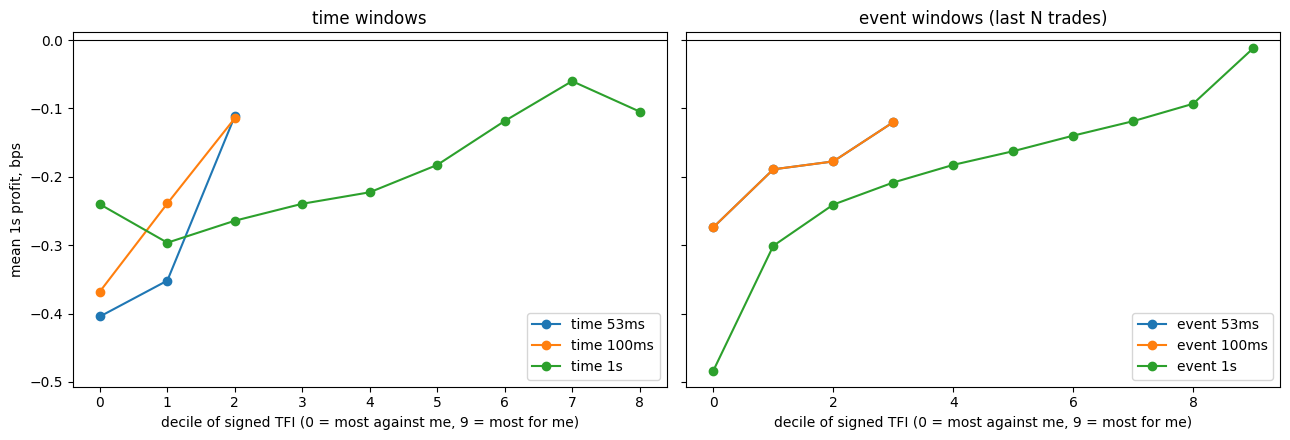


=== does the 1s flow add over book imbalance? ===
corr(imbalance, profit)                = +0.203
corr(flow, profit)                     = +0.034
corr(flow, imbalance)                  = +0.180   (overlap of the two signals)
partial corr(flow, profit | imbalance) = -0.003   (flow's lift after the book is known)
inside each imbalance bin:  mean profit (bps)   corr(flow, profit)
  imb         <-0.8:  mean=-1.004   corr(flow,prof)=+0.003
  imb    -0.8..-0.6:  mean=-0.694   corr(flow,prof)=+0.000
  imb    -0.6..-0.4:  mean=-0.475   corr(flow,prof)=-0.004
  imb    -0.4..-0.2:  mean=-0.308   corr(flow,prof)=-0.007
  imb    -0.2..+0.0:  mean=-0.177   corr(flow,prof)=-0.008
  imb    +0.0..+0.2:  mean=-0.054   corr(flow,prof)=-0.007
  imb    +0.2..+0.4:  mean=+0.058   corr(flow,prof)=-0.004
  imb    +0.4..+0.6:  mean=+0.171   corr(flow,prof)=+0.001
  imb    +0.6..+0.8:  mean=+0.307   corr(flow,prof)=+0.006
  imb         >+0.8:  mean=+0.447   corr(flow,prof)=+0.008


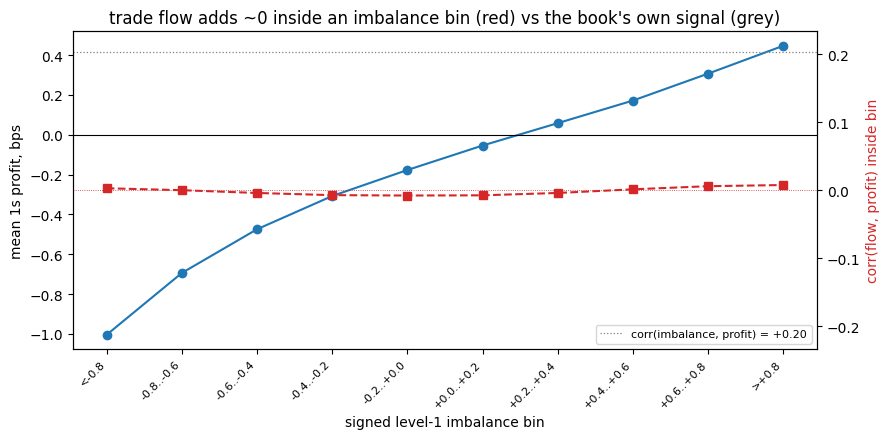

In [14]:
# Signed trade-flow imbalance (TFI) at the cutoff, over all 89 days. The trades feed is event-driven,
# so it sees inside the 53 ms book strobe. For each sample I sum aggressor volume (and count) on each
# side over a window ending at the cutoff, form TFI = (buy - sell)/(buy + sell), sign it by my side,
# and bin into deciles (the same test as the imbalance cell). Two window families: time windows, and
# event windows (the last N trades). I also keep an unsigned local trade rate as a risk feature.
# Where a window holds no trades the TFI is 0/0 = NaN; I keep that NaN (an empty window is still some
# information, a dead tape) instead of filling it with 0, and I print the NaN share per window below.
# Uses the shared toolbox: load_trades / load_book / asof / side_sign / corr / decile_profit / partial_corr, plus imb1_of from the imbalance cell.
import numpy as np, pandas as pd
import matplotlib.pyplot as plt

# the three time windows, microseconds: one strobe gap (~53 ms, the book's blind interval from the
# book-gap cell), the 100 ms sample-thinning window, and the 1 s profit / momentum horizon.
TF_WINS = [53_000, 100_000, 1_000_000]
TF_LBL  = ["53ms", "100ms", "1s"]
# sample fields I need, split by day once so the two passes below do not rescan 30M rows each.
tf_samp     = samples[["date", "events_before_server_time", "dir", "profit_1s_with_rebate", "sol_mid_move_1s_bps"]]
samp_by_day = dict(tuple(tf_samp.groupby("date", sort=True)))
TF_DAYS     = sorted(samp_by_day)

# one day's valid trade times (server_time > 0 only), sorted: the cheap reader for the occupancy pass.
# Deliberately looser than load_trades (no price/volume filter): the few dropped trades cannot move a median.
def _times(day):
    tr = pd.read_parquet(MARKET_DATA_PATH / f"SOLUSDT/{day}_trades.parquet", columns=["server_time"])
    return np.sort(tr.loc[tr.server_time > 0, "server_time"].to_numpy())

# PASS 1: set the event-window sizes N from the data, not by guessing. N = median number of trades a
# time window holds. I pool a per-sample occupancy histogram over all days (memory stays flat) and
# read the median off it.
OCC_CAP  = 10_000   # histogram cap; the median occupancy is ~tens, so clipping the rare huge bursts cannot move it
occ_hist = np.zeros((len(TF_WINS), OCC_CAP + 1), dtype=np.int64)
for day in TF_DAYS:
    t = _times(day)
    c = samp_by_day[day]["events_before_server_time"].to_numpy()      # this day's cutoffs
    j = np.searchsorted(t, c, side="right")                           # trades at or before c (causal)
    for w, W in enumerate(TF_WINS):
        i = np.searchsorted(t, c - W, side="right")                   # trades at or before c - W
        occ_hist[w] += np.bincount(np.minimum(j - i, OCC_CAP), minlength=OCC_CAP + 1)   # occupancy = trades in (c-W, c]

# median occupancy per window = smallest count whose cumulative share reaches half; floor at 2 so the ratio means something.
def _median(h):
    cum = np.cumsum(h); return int(np.searchsorted(cum, cum[-1] / 2))
TF_N = [max(_median(h), 2) for h in occ_hist]
print("median trades per time window (sets the matched event-window N):")
for lbl, W, n in zip(TF_LBL, TF_WINS, TF_N):
    print(f"  {lbl:>6} ({W // 1000:>4} ms):  N = {n}")

# one day's valid trades, sorted: times t, a buy mask (aggressor_dir == 0 is a Bid aggressor, a buyer
# lifting asks), and volume. Same validity filter as everywhere, via the toolbox loader.
def _trades(day):
    tr = load_trades("SOLUSDT", day)
    return tr.server_time.to_numpy(), (tr.aggressor_dir.to_numpy() == 0), tr.volume.to_numpy().astype(float)

# PASS 2: the features. Build cumulative buy/sell volume and count over the sorted trades, then for
# each sample subtract the cumulatives at the two ends of every window (a window sum is one difference).
def _tfi_day(day):
    t, buy, vol = _trades(day)
    sell = ~buy
    # cumulative sums with a leading 0, so the sum over trades [lo, j) is cum[j] - cum[lo].
    cbv = np.concatenate([[0.0], np.cumsum(np.where(buy,  vol, 0.0))])   # cumulative buy volume
    csv = np.concatenate([[0.0], np.cumsum(np.where(sell, vol, 0.0))])   # cumulative sell volume
    cbc = np.concatenate([[0], np.cumsum(buy.astype(np.int64))])         # cumulative buy count
    csc = np.concatenate([[0], np.cumsum(sell.astype(np.int64))])        # cumulative sell count
    s   = samp_by_day[day]
    c   = s["events_before_server_time"].to_numpy()
    j   = np.searchsorted(t, c, side="right")                            # trades at or before the cutoff
    sgn = side_sign(s["dir"])                                            # +1 long (bid), -1 short (ask)
    out = {"bps": s["profit_1s_with_rebate"].to_numpy() * 1e4, "mom": s["sol_mid_move_1s_bps"].to_numpy()}
    # signed volume- and count-TFI over the trades [lo, j); signed so > 0 = flow pushed my way.
    # float32 keeps the 30M-row table light (a ratio in [-1, 1] needs no more precision).
    def _tfi(lo):
        bv, sv = cbv[j] - cbv[lo], csv[j] - csv[lo]
        bc, sc = cbc[j] - cbc[lo], csc[j] - csc[lo]
        with np.errstate(invalid="ignore", divide="ignore"):
            return (sgn * (bv - sv) / (bv + sv)).astype(np.float32), (sgn * (bc - sc) / (bc + sc)).astype(np.float32)
    for lbl, W in zip(TF_LBL, TF_WINS):                                  # time window: trades in (c-W, c]
        out[f"time_{lbl}_vol"], out[f"time_{lbl}_cnt"] = _tfi(np.searchsorted(t, c - W, side="right"))
    for lbl, n in zip(TF_LBL, TF_N):                                     # event window: the last N trades <= c
        out[f"evt_{lbl}_vol"], out[f"evt_{lbl}_cnt"] = _tfi(np.maximum(j - n, 0))
    # local trade rate (unsigned risk gauge), one per event window: N trades / the time they spanned
    # = trades per second. NaN when <2 trades or a zero span (the last N share a timestamp); for the
    # rate that NaN flags a same-instant burst, not a dead tape, so it is read the other way round.
    for lbl, n in zip(TF_LBL, TF_N):
        lo = np.maximum(j - n, 0); m = j - lo
        span_s = (t[np.maximum(j - 1, 0)] - t[lo]) / 1e6 if t.size else np.zeros(len(j))
        with np.errstate(invalid="ignore", divide="ignore"):
            out[f"rate_{lbl}"] = np.where((m >= 2) & (span_s > 0), m / span_s, np.nan).astype(np.float32)
    return pd.DataFrame(out)

# stream all days and stack (one row per sample; NaN in a column where that window had no trades).
res = pd.concat([_tfi_day(d) for d in TF_DAYS], ignore_index=True)
print(f"\nsamples: {len(res):,}   baseline mean profit = {res['bps'].mean():.3f} bps")

# corr of each signed TFI with profit (volume vs count, time vs event), with the NaN share per window.
print("\ncorr(signed TFI, profit_bps)   [NaN% = window held no trades]:")
for l in TF_LBL:
    cv, ev = res[f"time_{l}_vol"], res[f"evt_{l}_vol"]
    print(f"  {l:>6}:  time vol {corr(cv, res['bps']):+.3f} cnt {corr(res[f'time_{l}_cnt'], res['bps']):+.3f} (NaN {cv.isna().mean()*100:4.1f}%)"
          f"   |   event vol {corr(ev, res['bps']):+.3f} cnt {corr(res[f'evt_{l}_cnt'], res['bps']):+.3f} (NaN {ev.isna().mean()*100:4.1f}%)")
# the local trade rate (unsigned). here NaN mostly means the last N shared a timestamp (a burst).
print("\ncorr(local trade rate, profit_bps)   [unsigned risk gauge]:")
for l in TF_LBL:
    r = res[f"rate_{l}"]
    print(f"  rate {l:>6}:  corr {corr(r, res['bps']):+.3f}   (NaN {r.isna().mean()*100:4.1f}%)")

# the blind spot: trades where the trailing momentum was exactly 0 (volume TFI only).
z = res[res["mom"] == 0]
print(f"\nmomentum==0 subset (n={len(z):,}, baseline {z['bps'].mean():.3f} bps):")
for l in TF_LBL:
    print(f"  {l:>6}:  time vol {corr(z[f'time_{l}_vol'], z['bps']):+.3f}    event vol {corr(z[f'evt_{l}_vol'], z['bps']):+.3f}")

# per-decile count, mean profit, win rate: signed TFI (0 = most against me, 9 = most for me), rate
# unsigned (0 = quietest, 9 = busiest). decile_profit drops NaN rows and returns n / mean_bps / win_pct.
VOL_COLS  = [f"time_{l}_vol" for l in TF_LBL] + [f"evt_{l}_vol" for l in TF_LBL]
RATE_COLS = [f"rate_{l}" for l in TF_LBL]
DEC = {col: decile_profit(res[col], res["bps"]) for col in VOL_COLS + RATE_COLS}   # precompute once, reuse for tables and plot
print("\n=== mean 1s profit by signed TFI decile (volume) ===")
for col in VOL_COLS:
    print(f"\n-- {col} --")
    print(DEC[col].to_string(float_format=lambda v: f"{v:.3f}"))
print("\n=== mean 1s profit by local trade rate decile (unsigned risk gauge) ===")
for col in RATE_COLS:
    print(f"\n-- {col} --")
    print(DEC[col].to_string(float_format=lambda v: f"{v:.3f}"))

# plot: decile mean profit, time family vs event family side by side (volume), shared y.
fig, (axL, axR) = plt.subplots(1, 2, figsize=(13, 4.5), sharey=True)
for l in TF_LBL:
    axL.plot(DEC[f"time_{l}_vol"].index, DEC[f"time_{l}_vol"]["mean_bps"], "o-", label=f"time {l}")
    axR.plot(DEC[f"evt_{l}_vol"].index,  DEC[f"evt_{l}_vol"]["mean_bps"],  "o-", label=f"event {l}")
for ax, ttl in ((axL, "time windows"), (axR, "event windows (last N trades)")):
    ax.axhline(0, color="black", lw=0.8); ax.set_title(ttl); ax.legend()
    ax.set_xlabel("decile of signed TFI (0 = most against me, 9 = most for me)")
axL.set_ylabel("mean 1s profit, bps")
plt.tight_layout(); plt.show()


# --- safety check: does the 1 s trade flow add over the book imbalance, or just echo it? ---
# I attach the signed level-1 imbalance to each sample (last snapshot at or before the cutoff, via
# asof) and reuse the signed 1 s flow already in res, then compare corr(imbalance, profit) with
# corr(flow, profit), their overlap corr(flow, imbalance), and the partial corr of flow given
# imbalance (its lift once the book is known). Only a book read is added.
def _imb_signed(day):
    s   = samp_by_day[day]
    c   = s["events_before_server_time"].to_numpy()
    bk  = load_book("SOLUSDT", day, size_levels=1)
    return asof(bk.server_time.to_numpy(), imb1_of(bk), c) * side_sign(s["dir"])
res["imb_signed"] = np.concatenate([_imb_signed(d) for d in TF_DAYS])   # aligned to res (same per-day order)

# all three corrs on the common non-NaN rows, so the partial corr is consistent.
rc = pd.DataFrame({"flow": res["time_1s_vol"], "imb": res["imb_signed"], "prof": res["bps"]}).dropna()
r_ip = corr(rc["imb"], rc["prof"]); r_tp = corr(rc["flow"], rc["prof"]); r_ti = corr(rc["flow"], rc["imb"])
partial = partial_corr(rc["prof"], rc["flow"], {"imb": rc["imb"]})      # flow's lift once the book is known
print("\n=== does the 1s flow add over book imbalance? ===")
print(f"corr(imbalance, profit)                = {r_ip:+.3f}")
print(f"corr(flow, profit)                     = {r_tp:+.3f}")
print(f"corr(flow, imbalance)                  = {r_ti:+.3f}   (overlap of the two signals)")
print(f"partial corr(flow, profit | imbalance) = {partial:+.3f}   (flow's lift after the book is known)")

# mean profit and in-bin corr(flow, profit) inside fixed imbalance bins: if flow added, the in-bin
# corr stays positive; if it echoes imbalance, it collapses to ~0 once the bin is fixed.
IMB_EDGES = np.round(np.linspace(-1, 1, 11), 2)[1:-1]
rc["b"] = np.digitize(rc["imb"].to_numpy(), IMB_EDGES)
mp = rc.groupby("b")["prof"].mean()
ic = rc.groupby("b")[["flow", "prof"]].apply(lambda x: x["flow"].corr(x["prof"]))
lab = [f"<{IMB_EDGES[0]:+.1f}"] + [f"{IMB_EDGES[k]:+.1f}..{IMB_EDGES[k+1]:+.1f}" for k in range(len(IMB_EDGES) - 1)] + [f">{IMB_EDGES[-1]:+.1f}"]
# the numbers behind the red line, so "flat at 0" can be read off rather than eyeballed off the axis.
print("inside each imbalance bin:  mean profit (bps)   corr(flow, profit)")
for b in range(len(lab)):
    if b in mp.index:
        print(f"  imb {lab[b]:>13}:  mean={mp[b]:+.3f}   corr(flow,prof)={ic[b]:+.3f}")

# plot: imbalance sorts profit (blue, left axis); flow's pull inside each imbalance bin (red, right
# axis) sits at ~0. The red axis is pinned to imbalance's own corr scale (grey line at corr(imbalance,
# profit)), so a near-zero red line reads as flat rather than as a zoomed-in wiggle.
fig, ax = plt.subplots(figsize=(9, 4.5))
xb = np.arange(len(lab))
ax.plot(xb, [mp.get(b, np.nan) for b in xb], "o-")
ax.axhline(0, color="black", lw=0.8)
ax2 = ax.twinx()
ax2.plot(xb, [ic.get(b, np.nan) for b in xb], "s--", color="tab:red")
ax2.axhline(r_ip, color="gray", lw=0.9, ls=":", label=f"corr(imbalance, profit) = {r_ip:+.2f}")
ax2.axhline(0, color="tab:red", lw=0.6, ls=":")
ax2.set_ylim(-1.15 * abs(r_ip), 1.15 * abs(r_ip))          # pin to imbalance's corr scale so ~0 reads flat
ax.set_xticks(xb); ax.set_xticklabels(lab, rotation=45, ha="right", fontsize=8)
ax.set_xlabel("signed level-1 imbalance bin"); ax.set_ylabel("mean 1s profit, bps")
ax2.set_ylabel("corr(flow, profit) inside bin", color="tab:red")
ax2.legend(loc="lower right", fontsize=8)
ax.set_title("trade flow adds ~0 inside an imbalance bin (red) vs the book's own signal (grey)")
plt.tight_layout(); plt.show()

So trade flow is real, but weak.

It does sort. The signed event-1s TFI runs monotone from −0.484 bps in the worst decile to −0.012 in the best, and the win rate climbs with it, 16% to 27% (the evt_1s_vol table). Both rise together, so this is a direction signal, not the |move| paradox. But look where it tops out: −0.012, still < 0. The best flow decile is basically break-even. The book imbalance, by contrast, had its best decile at +0.407, clearly green. So on its own, trade flow never crosses zero, and the corr says the same: +0.053 against imbalance's +0.203, about four times weaker. As a standalone rule it just says skip.

The event window always holds the same number of trades, so every imbalance ratio rests on the same amount of evidence. The 1 s clock does not. In a quiet second it can hold just one or two trades, and if they all lean one way the ratio jumps to +1. That +1 comes from a near-empty window, not from the flow actually leaning one way. These fake extremes fall into the top and bottom time deciles and blur them. That is probably the bend I see at the top of time-1s. So we may have an explanation of why counting trades beat timing them.

The local trade rate is a pure risk gauge for the model, exactly like |move|. As the tape gets busier the win rate climbs (5% to 27%) but the mean profit falls (−0.078 to −0.309). I win more often and lose more when wrong, and the bad side wins. The quietest tape is the safest. So the rate flags when it is risky, not which way to bet. Again. Same as the size smile and |move|: they tell me when it is dangerous, never which side to take. Its NaN is the odd one out. The rate is trades divided by the time they spanned, so it goes NaN when the last few trades all share one microsecond and the span is zero. That stacking is a sweep, the busiest the tape gets. So here NaN means busy, the opposite of the empty-window NaN that means dead.

So the book imbalance is still the only feature that crosses into profit. Does flow add anything on top of it, or just repeat it? The safety check at the bottom of the cell settles it: no. Flow and imbalance overlap (corr +0.18), and once I hold the imbalance fixed the flow goes empty. The partial corr of flow given imbalance is −0.003, and inside every imbalance bin the corr(flow, profit) stays within ±0.008. On the plot that is the flat red line, far below the grey line at the book's own +0.20. The blue line going green is not news, it is the imbalance edge re-drawn on fixed bins. So the picture did not move: book imbalance is the directional signal, flow is a noisier echo of it, and the trade rate stays a risk gauge. It still goes to the model, imbalance as the edge with volume, volatility and the local trade rate for sizing.

Back to brainstorming, before the model. Let me lay the pieces out properly first.

What I already have: from the imbalance cell above, my one direction signal is the signed level-1 imbalance $I_1^{\mathrm{SOL}}(x) = \sigma(x)\, I_1^{\leftarrow,\,\mathrm{SOL}}(c(x))$, the only feature that crossed into profit on its own. I also keep how that lean is moving, its 1s momentum
$$\Delta I^{\mathrm{SOL}}(x) = \sigma(x)\,\big(I_1^{\leftarrow,\,\mathrm{SOL}}(c(x)) - I_1^{\leftarrow,\,\mathrm{SOL}}(c(x) - 1\,\mathrm{s})\big).$$
So $I_1^{\mathrm{SOL}}$ is the lean now, $\Delta I^{\mathrm{SOL}}$ is whether that lean is building or fading. In the code these two are the `imb1` and `dimb` columns the model reads.

This hint me to dig more with the data set of BTC and ETH. I already tried to get a feature from them: predictability of return (correlation), in the lead-lag cell (above). To recall, I put the three coins' returns on a shared 50 ms clock and scanned the cross-correlation
$$\rho_X(k) = \mathrm{corr}\big(r_X^{\leftarrow}[t],\, r_{\mathrm{SOL}}^{\leftarrow}[t+k]\big),$$
so $k > 0$ means coin $X$ moves first and co-move is when the peak is at $k = 0$: same instant, no lead. A lead I could actually trade has to clear the latency and the strobe, so it has to sit at $k \ge 1$ bar (at least 50 ms out). It did not. So cross-asset returns are a dead end.

But that test only ever looked at realized returns. It never looked at the book. And a book imbalance is a pressure I can read before the move happens. On SOL that pressure already helps: $I_1^{\mathrm{SOL}}$ leans the next second my way, and $\Delta I^{\mathrm{SOL}}$ says whether that lean is building. BTC and ETH carry the exact same kind of book, the question is: do BTC's and ETH's book imbalance, and how it is moving, line up with what SOL does next, in a way SOL's own book does not already say? If yes, it is a feature. If they are just SOL's book echo, they are worth nothing. The test below decides.

I build BTC's and ETH's signed level-1 imbalance exactly like SOL's,
$$I_1^{\mathrm{BTC}}(x) = \sigma(x)\, I_1^{\leftarrow,\,\mathrm{BTC}}(c(x)), \qquad I_1^{\mathrm{ETH}}(x) = \sigma(x)\, I_1^{\leftarrow,\,\mathrm{ETH}}(c(x)),$$
each from the last snapshot of that coin's book with $\mathrm{server\_time} \le c(x)$. I also take each one's 1s momentum, the same change I formed for SOL,
$$\Delta I^{\mathrm{BTC}}(x) = \sigma(x)\,\big(I_1^{\leftarrow,\,\mathrm{BTC}}(c(x)) - I_1^{\leftarrow,\,\mathrm{BTC}}(c(x) - 1\,\mathrm{s})\big), \qquad \Delta I^{\mathrm{ETH}}(x) = \sigma(x)\,\big(I_1^{\leftarrow,\,\mathrm{ETH}}(c(x)) - I_1^{\leftarrow,\,\mathrm{ETH}}(c(x) - 1\,\mathrm{s})\big).$$
This is the same causal rule SOL's own features obey, so no look-ahead. In the code these four are the `btc`, `eth`, `btc_dimb`, `eth_dimb` columns. The 53 ms strobe applies to all three books the same way. (Level 1 only for now. The deeper levels are for the harder deep-fills question, to keep in mind...)

I decide to keep BTC and ETH apart: for example I do not blend them into one average. Two coins is two order books, so two signals. A hand-average $\tfrac{1}{2}(I_1^{\mathrm{BTC}} + I_1^{\mathrm{ETH}})$ freezes them at equal weight and forces a linear rule. A model can do more with the raw pair. It can weight one coin above the other. It can also use a nonlinear agreement rule, something like "trust the pressure only when $\mathrm{sign}(I_1^{\mathrm{BTC}}) = \mathrm{sign}(I_1^{\mathrm{ETH}})$". No single averaged scalar can express that.

Now I will test whether this is genuinely new information, or just SOL's own book in disguise. The coins co-move, so $I_1^{\mathrm{BTC}}$ and $I_1^{\mathrm{ETH}}$ are bound to correlate with SOL's own imbalance. A plain $\mathrm{corr}(I_1^{\mathrm{BTC}}, \pi)$ therefore proves nothing. It could be an echo, the way trade flow turned out to be. So I use the partial correlation, the same test that killed flow. I regress out of both the profit $\pi$ and the candidate $X$ everything my own book already explains, then correlate what is left:
$$\rho_{\mathrm{partial}}\big(\pi, X \mid I_1^{\mathrm{SOL}}, \Delta I^{\mathrm{SOL}}\big) = \mathrm{corr}\big(\pi - \widehat{\pi},\; X - \widehat{X}\big),$$
where $\widehat{\pi}$ and $\widehat{X}$ are the linear projections of $\pi$ and $X$ on $\{1, I_1^{\mathrm{SOL}}, \Delta I^{\mathrm{SOL}}\}$. For a single control $Z$ this is the closed form
$$\rho_{\mathrm{partial}}(\pi, X \mid Z) = \frac{r_{\pi X} - r_{\pi Z}\, r_{X Z}}{\sqrt{(1 - r_{\pi Z}^2)\,(1 - r_{X Z}^2)}}.$$
Residualizing on $\{I_1^{\mathrm{SOL}}, \Delta I^{\mathrm{SOL}}\}$ strips out everything SOL's own book already says, so what is left is what BTC and ETH add on top. $\Delta I^{\mathrm{SOL}}$'s own partial is the reference here for the size of a real add: if $I_1^{\mathrm{BTC}}$ and $I_1^{\mathrm{ETH}}$ show a genuine partial next to it and their mean-profit deciles cross green, then the other two books carry a direction SOL's own does not. This will be a cross-asset feature I could use for the model.

aligned samples: 30,337,634   baseline corr(imb1, profit) = +0.203
(dimb is already in the model; its partial prints here as the reference for the size of an add)



 feature  corr_prof  corr_imb1  partial_imb1  partial_imb1_dimb  dec_bot  dec_top  green_dec
     btc    +0.1174    +0.4193       +0.0362            +0.0370  -0.7182  +0.1944          2
     eth    +0.1311    +0.4235       +0.0508            +0.0495  -0.7399  +0.2073          2
     avg    +0.1451    +0.4921       +0.0529            +0.0526  -0.7777  +0.2409          3
btc_dimb    +0.0910    +0.2645       +0.0395            +0.0280  -0.5901  +0.0387          1
eth_dimb    +0.0941    +0.2436       +0.0469            +0.0357  -0.5946  +0.0650          1
avg_dimb    +0.1085    +0.2970       +0.0515            +0.0392  -0.6579  +0.1113          1
    dimb    +0.1457    +0.5652       +0.0382                NaN  -0.7897  +0.2355          2

multiple-partial over {imb1,dimb} (joint add of a feature set):


  avg level alone           = +0.0526


  BTC+ETH levels separate   = +0.0537


  levels + their momentum   = +0.0550


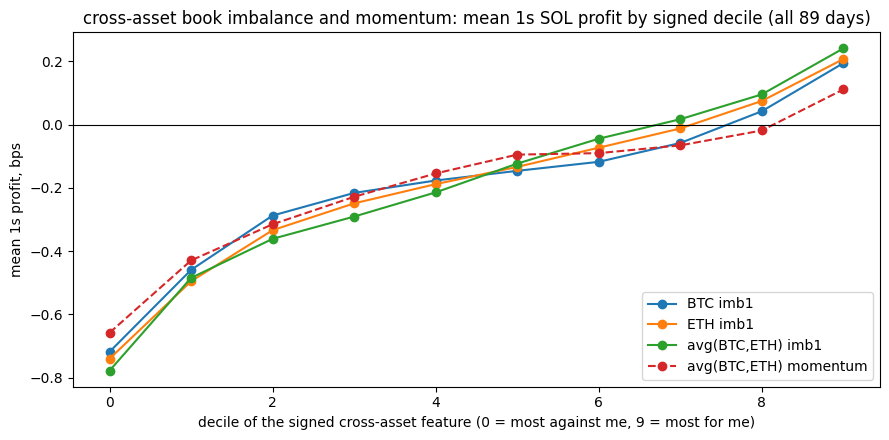

In [6]:
# Cross-asset BOOK IMBALANCE and its MOMENTUM, over all 89 days. The lead-lag cell tested cross-asset
# RETURNS (co-move, no lead); this tests cross-asset book STATE: BTC's and ETH's signed L1 imbalance
# and its 1s momentum, as of the cutoff, as a predictor of SOL's next-second profit. Kept SEPARATE
# (two feeds, let the model weight each) and controlled for SOL's own imb1 and dimb via the PARTIAL
# corr (the add-over-imb1 test that killed flow). Uses the shared toolbox: load_book / asof (causal
# read at server_time <= c) / side_sign / corr / decile_profit / partial_corr, plus imb1_of from the imbalance cell.
import numpy as np, pandas as pd
import matplotlib.pyplot as plt

xi_by_day = dict(tuple(samples[["date", "events_before_server_time", "dir", "profit_1s_with_rebate"]].groupby("date", sort=True)))

# one day: SOL imb1 + dimb (controls) and BTC/ETH imb1 + their 1s momentum, each as of the cutoff, signed.
def _xi_day(day):
    s = xi_by_day[day]; c = s["events_before_server_time"].to_numpy(); sgn = side_sign(s["dir"])
    books = {sym: load_book(sym, day, size_levels=1) for sym in ("SOLUSDT", "BTCUSDT", "ETHUSDT")}  # each once
    def imb_at(sym, lag=0):
        b = books[sym]; return asof(b.server_time.to_numpy(), imb1_of(b), c, lag)
    sol, solp = imb_at("SOLUSDT"), imb_at("SOLUSDT", 1_000_000)
    btc, btcp = imb_at("BTCUSDT"), imb_at("BTCUSDT", 1_000_000)
    eth, ethp = imb_at("ETHUSDT"), imb_at("ETHUSDT", 1_000_000)
    return pd.DataFrame({"prof_bps": s["profit_1s_with_rebate"].to_numpy() * 1e4,
                         "imb1": sol * sgn, "dimb": (sol - solp) * sgn,
                         "btc": btc * sgn, "eth": eth * sgn,
                         "btc_dimb": (btc - btcp) * sgn, "eth_dimb": (eth - ethp) * sgn})

res = pd.concat([_xi_day(d) for d in sorted(xi_by_day)], ignore_index=True)
res["avg"] = (res["btc"] + res["eth"]) / 2
res["avg_dimb"] = (res["btc_dimb"] + res["eth_dimb"]) / 2
prof = res["prof_bps"].to_numpy()
ctl1 = {"imb1": res["imb1"].to_numpy()}
ctl2 = {"imb1": res["imb1"].to_numpy(), "dimb": res["dimb"].to_numpy()}

print(f"aligned samples: {len(res):,}   baseline corr(imb1, profit) = {corr(res['imb1'], prof):+.3f}")
print("(dimb is already in the model; its partial prints here as the reference for the size of an add)\n")
rows = []
for f in ["btc", "eth", "avg", "btc_dimb", "eth_dimb", "avg_dimb", "dimb"]:
    d = decile_profit(res[f], prof)["mean_bps"]
    rows.append(dict(feature=f, corr_prof=corr(res[f], prof), corr_imb1=corr(res[f], res["imb1"]),
                     partial_imb1=partial_corr(prof, res[f].to_numpy(), ctl1),
                     partial_imb1_dimb=partial_corr(prof, res[f].to_numpy(), ctl2),
                     dec_bot=d.iloc[0], dec_top=d.iloc[-1], green_dec=int((d > 0).sum())))
print(pd.DataFrame(rows).to_string(index=False, float_format=lambda v: f"{v:+.4f}"))

# joint add over {imb1,dimb}: multiple-partial (residualize profit and each feat, then corr profit's
# residual with its best linear fit on the feats' residuals). Levels separate vs a hand-average, and
# whether the momentum buys anything on top of the levels.
def _mult_partial(feats):
    d = res[["prof_bps"] + feats + ["imb1", "dimb"]].replace([np.inf, -np.inf], np.nan).dropna()
    A = np.column_stack([np.ones(len(d)), d["imb1"].to_numpy(), d["dimb"].to_numpy()])
    rz = lambda y: y - A @ np.linalg.lstsq(A, y, rcond=None)[0]
    ry = rz(d["prof_bps"].to_numpy()); RC = np.column_stack([rz(d[f].to_numpy()) for f in feats])
    return np.corrcoef(ry, RC @ np.linalg.lstsq(RC, ry, rcond=None)[0])[0, 1]
print("\nmultiple-partial over {imb1,dimb} (joint add of a feature set):")
print(f"  avg level alone           = {_mult_partial(['avg']):+.4f}")
print(f"  BTC+ETH levels separate   = {_mult_partial(['btc','eth']):+.4f}")
print(f"  levels + their momentum   = {_mult_partial(['btc','eth','btc_dimb','eth_dimb']):+.4f}")

# plot: decile mean profit, signed. Levels solid, averaged momentum dashed.
fig, ax = plt.subplots(figsize=(9, 4.5))
for f, lbl, st in [("btc", "BTC imb1", "o-"), ("eth", "ETH imb1", "o-"),
                   ("avg", "avg(BTC,ETH) imb1", "o-"), ("avg_dimb", "avg(BTC,ETH) momentum", "o--")]:
    d = decile_profit(res[f], prof)["mean_bps"]; ax.plot(d.index, d.values, st, label=lbl)
ax.axhline(0, color="black", lw=0.8)
ax.set_title("cross-asset book imbalance and momentum: mean 1s SOL profit by signed decile (all 89 days)")
ax.set_xlabel("decile of the signed cross-asset feature (0 = most against me, 9 = most for me)")
ax.set_ylabel("mean 1s profit, bps")
ax.legend(); plt.tight_layout(); plt.show()

So it works, and it is the cross-asset imbalance level, not the momentum.

Start with the reference. On all 89 days SOL's own $\Delta I^{\mathrm{SOL}}$ clears $I_1^{\mathrm{SOL}}$ by partial +0.038 (the $\Delta I^{\mathrm{SOL}}$ row). That is the size of a real add. The cross-asset levels match it. ETH's book imbalance sits at partial +0.051, the average of BTC and ETH at +0.053, and both hold when I also strip out SOL's $\Delta I^{\mathrm{SOL}}$ (+0.050 and +0.053). Their deciles bend the whole way up. The average runs from -0.78 bps in the worst decile to +0.24 in the best, and its top three deciles are green. So the plot is telling the truth: when the other two books lean my way, SOL's next second leans my way too, and I knew it at the cutoff. It is genuinely new, not an echo. $I_1^{\mathrm{SOL}}$ already explains a lot (the average shares corr 0.49 with it), but +0.053 is left over after I remove $I_1^{\mathrm{SOL}}$ and $\Delta I^{\mathrm{SOL}}$.

BTC is the weak one though. On its own its partial is +0.036, just under the +0.038 reference, while ETH is at +0.051. So ETH carries most of the cross-asset edge and BTC adds little alone. That is why the average beats either single coin (top decile +0.24 against +0.19 for BTC and +0.21 for ETH): it leans on the stronger ETH and cancels each book's own noise.

So I will keep them apart because the numbers back it. I will fed them separately, BTC and ETH give a joint partial of +0.054 over {$I_1^{\mathrm{SOL}}$, $\Delta I^{\mathrm{SOL}}$}, above the hand-average's +0.053. Tiny, but it is the right sign, so both go in raw and the tree weights them.

The momentum is real but redundant, so it stays out. On its own it looks fine: the averaged cross-momentum has partial +0.052, and it is less tangled with $I_1^{\mathrm{SOL}}$ than the levels are (corr 0.30 against 0.49). But it is just imbalance momentum on other coins, so it overlaps SOL's own $\Delta I^{\mathrm{SOL}}$. Control for $\Delta I^{\mathrm{SOL}}$ and it sinks to +0.039, back at the reference, with only its top decile green (+0.11, against the level's +0.24). And stacked on top of the levels it buys almost nothing: the joint partial goes from +0.0537 to +0.0550 when I add both momentum features, a +0.001 gain. The level already holds the cross-asset direction. The momentum is a weaker echo of it and of SOL's $\Delta I^{\mathrm{SOL}}$.

So two features go into the model: $I_1^{\mathrm{BTC}}$ and $I_1^{\mathrm{ETH}}$, the signed level-1 imbalance of each coin, kept separate. The cross-momentum adds nothing new, so it stays out. The book state carries a real direction, and it is the first thing I have found that adds to imbalance about as much as SOL's own momentum does.

Still on finding direction, one last idea from inside the book before I turn to the other kind of feature. $\Delta I^{\mathrm{SOL}}$ compares the lean now to one snapshot 1 s back, so it stands on two noisy points. The strobe gives me about nineteen snapshots in that second (the 53 ms gap above); so if we use them all and write $\bar I^{\,\mathrm{SOL}}(c)$ for the mean of $I_1^{\mathrm{SOL}}$ over the snapshots in $(c - 1\,\mathrm{s},\, c]$, and take the deviation from it,
$$D(x) = \sigma(x)\,\big(I_1^{\leftarrow,\,\mathrm{SOL}}(c(x)) - \bar I^{\,\mathrm{SOL}}(c(x))\big),$$
then we may get something interesting.
I do the same thing as before but with this new object and on the same 1 s window as $\Delta I^{\mathrm{SOL}}$. The difference: $\Delta I^{\mathrm{SOL}}$ compares two single snapshots, $D$ compares now to the average of the whole past second. I try the same object on BTC and ETH too. In the code these are `devavg`, `btc_dev`, `eth_dev`.

In [7]:
# Deviation-from-average imbalance, over all 89 days: the lean now minus its own 1s snapshot mean,
# signed by my side; the same object on BTC and ETH. Controls are the full direction set
# {imb1, dimb, btc, eth}; dimb's own partial over imb1 prints as the reference. Uses the shared toolbox:
# load_book / asof / side_sign / corr / decile_profit / partial_corr, plus imb1_of.
import numpy as np, pandas as pd

dv_by_day = dict(tuple(samples[["date", "events_before_server_time", "dir", "profit_1s_with_rebate"]].groupby("date", sort=True)))

def _dv_day(day):
    s = dv_by_day[day]; c = s["events_before_server_time"].to_numpy(); sgn = side_sign(s["dir"])
    out = {"month": s["date"].str[:6].to_numpy(), "prof_bps": s["profit_1s_with_rebate"].to_numpy() * 1e4}
    for nm, sym in (("imb1", "SOLUSDT"), ("btc", "BTCUSDT"), ("eth", "ETHUSDT")):
        bk = load_book(sym, day, size_levels=1); bt = bk.server_time.to_numpy()
        with np.errstate(invalid="ignore", divide="ignore"):
            imb = imb1_of(bk)
        cur = asof(bt, imb, c)
        S = np.concatenate([[0.0], np.nancumsum(imb)])               # snapshot-mean over (c-1s, c], NaN-safe
        Cn = np.concatenate([[0.0], np.cumsum(~np.isnan(imb))])
        ihi = np.searchsorted(bt, c, "right"); ilo = np.searchsorted(bt, c - 1_000_000, "right")
        nn_w = Cn[ihi] - Cn[ilo]
        avg = np.where(nn_w > 0, (S[ihi] - S[ilo]) / np.maximum(nn_w, 1), np.nan)
        out[nm] = cur * sgn
        out["devavg" if nm == "imb1" else nm + "_dev"] = (cur - avg) * sgn
        if nm == "imb1":
            out["dimb"] = (cur - asof(bt, imb, c, 1_000_000)) * sgn
    return pd.DataFrame(out)

dv = pd.concat([_dv_day(d) for d in sorted(dv_by_day)], ignore_index=True)
prof = dv["prof_bps"].to_numpy()
ctl = {k: dv[k].to_numpy() for k in ["imb1", "dimb", "btc", "eth"]}
print(f"samples: {len(dv):,}   reference: partial(dimb | imb1) = {partial_corr(prof, dv['dimb'].to_numpy(), {'imb1': ctl['imb1']}):+.4f}\n")
rows = []
for f in ["devavg", "btc_dev", "eth_dev"]:
    d = decile_profit(dv[f], prof)["mean_bps"]
    rows.append(dict(feature=f, corr_prof=corr(dv[f], prof), partial_ctl4=partial_corr(prof, dv[f].to_numpy(), ctl),
                     corr_dimb=corr(dv[f], dv["dimb"]), dec_bot=d.iloc[0], dec_top=d.iloc[-1], green=int((d > 0).sum())))
print(pd.DataFrame(rows).to_string(index=False, float_format=lambda v: f"{v:+.4f}"))
print("\ndevavg by month (partial over the four controls):")
for m, g in dv.groupby("month"):
    p = g["prof_bps"].to_numpy(); cm = {k: g[k].to_numpy() for k in ["imb1", "dimb", "btc", "eth"]}
    d = decile_profit(g["devavg"], p)["mean_bps"]
    print(f"  {m}: partial {partial_corr(p, g['devavg'].to_numpy(), cm):+.4f}   deciles bot {d.iloc[0]:+.3f} top {d.iloc[-1]:+.3f}, green {int((d > 0).sum())}")

samples: 30,337,634   reference: partial(dimb | imb1) = +0.0382



feature  corr_prof  partial_ctl4  corr_dimb  dec_bot  dec_top  green
 devavg    +0.1621       +0.0345    +0.7695  -0.8771  +0.2688      3
btc_dev    +0.1053       +0.0254    +0.3594  -0.6682  +0.0668      1
eth_dev    +0.1078       +0.0308    +0.3186  -0.6597  +0.0791      2

devavg by month (partial over the four controls):


  202602: partial +0.0243   deciles bot -0.975 top +0.270, green 3


  202603: partial +0.0365   deciles bot -0.847 top +0.294, green 3


  202604: partial +0.0479   deciles bot -0.664 top +0.234, green 3


So the SOL one is real, and the cross versions are a bit weaker.

On all 89 days $D$ has partial +0.0345 over {imb1, dimb, btc, eth}; for scale, dimb's own add over imb1 prints at +0.0382 above. $D$ is mostly $\Delta I^{\mathrm{SOL}}$ re-expressed (corr +0.77). By month: February +0.0243, March +0.0365, April +0.0479, and the deciles bend the right way every month, three green at the top. btc_dev and eth_dev sit at +0.0254 and +0.0308, with fewer green deciles.

All three are positive and they are not echoes, so all three go in. That is I think the standard rule: a feature that adds something (even something tiny) goes into the model and the trees weight it; only echoes and zeros (?) stay out.

Now the other kind. Everything I hunted so far was direction: which way the next second goes. The cells above say there is not much left to find there; every new candidate came out an echo of $I_1^{\mathrm{SOL}}$ or added close to nothing new. But $\phi$ has a second kind of feature, risk, and I never hunted it seriously: I only kept the three that fell out of the earlier cells ($v$, $|m|$, $\rho$). The loss anatomy above says this is worth money: the worst 5% of fills carry about half the loss. A risk feature does not need to know which way the second goes. The model predicts the mean, and around fills with a heavy adverse tail the mean is negative, so a good size signal moves fills across the take/skip boundary just like a direction signal does.

A risk feature is unsigned, so the old test is wrong for it: it will not sort signed profit. It should predict the size $|\pi|$. So the screen is the partial of $|\pi|$ on the candidate given the trio $\{v, |m|, \rho\}$ I already have, and I print what each of the trio scores given the other two as the reference. I also print the correlation with each of the trio, because I want new information, not $|m|$ re-measured. The candidates, all read at the cutoff:

- the spread: a wide spread means the makers already see danger;
- the depth: the total size resting at level 1, both sides, logged; a thin book is a fragile book;
- the flips: how many times the mid changed across the snapshots in $(c - 1\,\mathrm{s},\, c]$;
- BTC's and ETH's $|1\,\mathrm{s}\ \text{mid move}|$: how hard the other two coins moved in the past second, for when SOL's own $|m|$ is still calm;
- the print displacement: how far this fill printed past my side's last-snapshot quote; the sweep already went past the last snapshot (the fill's own price is part of the sample, so this is allowed: the question is always whether an order already resting at this price should have been there).

In the code: `spread`, `depth`, `flips`, `btc_amv`, `eth_amv`, `absdispq`.

In [8]:
# The risk screen, over all 89 days: does a candidate predict the SIZE of the next second beyond
# {v, |m|, rho}? Screen = partial(|pi|, candidate | trio) with the trio's own leave-one-out partials
# as the reference, the correlation with each trio member, and the mean-profit / win-rate deciles. rate is
# rebuilt from the tape exactly as in the model cell. Uses the shared toolbox helpers.
import numpy as np, pandas as pd

rk_by_day = dict(tuple(samples[["date", "events_before_server_time", "dir", "price", "volume",
                                "profit_1s_with_rebate", "sol_mid_move_1s_bps"]].groupby("date", sort=True)))

def _rk_day(day):
    s = rk_by_day[day]; c = s["events_before_server_time"].to_numpy(); sgn = side_sign(s["dir"])
    bk = load_book("SOLUSDT", day, size_levels=1); bt = bk.server_time.to_numpy()
    bid, ask = bk.bid_price_1.to_numpy(), bk.ask_price_1.to_numpy()
    mid = (bid + ask) / 2
    ihi = np.searchsorted(bt, c, "right"); ilo = np.searchsorted(bt, c - 1_000_000, "right")
    flip = np.concatenate([[0.0], (np.diff(mid) != 0).astype(float)])
    Fc = np.concatenate([[0.0], np.cumsum(flip)])
    flips = (Fc[ihi] - Fc[ilo]).astype(float); flips[ihi == 0] = np.nan
    q_same = np.where(sgn > 0, asof(bt, bid, c), asof(bt, ask, c))
    tt = load_trades("SOLUSDT", day).server_time.to_numpy()
    rate = (np.searchsorted(tt, c, "right") - np.searchsorted(tt, c - 1_000_000, "right")).astype(float)
    out = {"y": s["profit_1s_with_rebate"].to_numpy() * 1e4,
           "vol": s["volume"].to_numpy(), "absmove": np.abs(s["sol_mid_move_1s_bps"].to_numpy()), "rate": rate,
           "spread": asof(bt, (ask - bid) / mid, c) * 1e4,
           "depth": np.log1p(asof(bt, bk.bid_size_1.to_numpy() + bk.ask_size_1.to_numpy(), c)),
           "flips": flips,
           "absdispq": np.abs(s["price"].to_numpy() - q_same) / asof(bt, mid, c) * 1e4}
    for nm, sym in (("btc_amv", "BTCUSDT"), ("eth_amv", "ETHUSDT")):
        xb = load_book(sym, day); xt = xb.server_time.to_numpy()
        xmid = (xb.bid_price_1.to_numpy() + xb.ask_price_1.to_numpy()) / 2
        out[nm] = np.abs(asof(xt, xmid, c) - asof(xt, xmid, c, 1_000_000)) / asof(xt, xmid, c) * 1e4
    return pd.DataFrame(out)

rk = pd.concat([_rk_day(d) for d in sorted(rk_by_day)], ignore_index=True)
y = rk["y"].to_numpy(); absy = np.abs(y)
TRIO = ["vol", "absmove", "rate"]
print(f"samples: {len(rk):,}   the reference (each of the trio given the other two):")
for f in TRIO:
    others = {k: rk[k].to_numpy() for k in TRIO if k != f}
    print(f"  partial(|y|, {f:7s} | rest) = {partial_corr(absy, rk[f].to_numpy(), others):+.4f}")
ctl = {k: rk[k].to_numpy() for k in TRIO}
rows = []
for f in ["spread", "depth", "flips", "btc_amv", "eth_amv", "absdispq"]:
    d = decile_profit(rk[f], y)
    rows.append(dict(feature=f, partial_absy=partial_corr(absy, rk[f].to_numpy(), ctl),
                     c_vol=corr(rk[f], rk["vol"]), c_absmove=corr(rk[f], rk["absmove"]), c_rate=corr(rk[f], rk["rate"]),
                     prof_bot=d["mean_bps"].iloc[0], prof_top=d["mean_bps"].iloc[-1],
                     win_bot=d["win_pct"].iloc[0], win_top=d["win_pct"].iloc[-1]))
print()
print(pd.DataFrame(rows).to_string(index=False, float_format=lambda v: f"{v:+.4f}"))

samples: 30,337,634   the reference (each of the trio given the other two):


  partial(|y|, vol     | rest) = +0.0347


  partial(|y|, absmove | rest) = +0.1902


  partial(|y|, rate    | rest) = +0.1169



 feature  partial_absy   c_vol  c_absmove  c_rate  prof_bot  prof_top  win_bot  win_top
  spread       +0.0161 +0.0067    +0.1128 +0.1246   -0.2603   -0.2289 +23.2156 +18.9930
   depth       -0.1672 +0.0352    -0.1678 -0.1316   -0.3161   -0.1392 +27.0176 +11.4070
   flips       +0.2693 +0.0138    +0.7278 +0.6548   -0.1564   -0.3766 +13.3972 +35.9452
 btc_amv       +0.1189 +0.0151    +0.7148 +0.4754   -0.1344   -0.3613 +12.4264 +30.9699
 eth_amv       +0.1302 +0.0151    +0.7203 +0.4879   -0.1201   -0.3634 +11.2912 +31.7657
absdispq       +0.0750 +0.0075    +0.1236 +0.1785   -0.1942   -0.1942 +17.1531 +17.1531


The risk side was not empty at all.

flips is the strongest size signal in the whole notebook: partial +0.2693 over the trio, above even $|m|$'s own +0.1902. Its deciles show the familiar paradox shape: the win rate rises with flips (13.4% to 35.9%) while the mean profit falls (-0.16 to -0.38 bps). Many mid changes mean a big next second, in both directions, and the adverse side wins on average.

depth is the uncorrelated one I was hoping for: partial -0.1672 with at most 0.17 of correlation to the trio.

BTC's and ETH's moves carry information too: btc_amv +0.1189 and eth_amv +0.1302, both well above vol's own +0.0347.

absdispq is modest (+0.0750) and its decile row collapses: most fills print exactly at the stale quote, so the feature is 0 almost everywhere and only the nonzero part carries information. spread is the weakest (+0.0161), and positive still counts.

All six go into $\phi$ next to the trio of previous risk features and the trees weight them.

One more risk idea, from the fill itself. Every fill has a price $P(x)$, and the stale book gives ten levels per side. So I can ask a simple question: how much size rests on my side at $P(x)$ and past it? I call it the support. It is the size that stands behind my fill. If the price wants to move through me, it has to trade through all of that size first. So thick support should mean a smaller next second. This is close to depth, but not the same: depth is level 1 on both sides; the support is my side only, at my price, over all ten levels. In the code this is `supp` (logged, like depth). The screen is the same as for the other risk features, plus one extra check: the partial given depth.

In [5]:
# The support behind the fill, over all 89 days: the size resting on my side at P(x) and past it,
# read from the stale 10-level snapshot. Screen: the risk partial over {vol, absmove, rate}, the
# same partial given depth too (depth is the closest feature already in phi), and the deciles.
# Uses the shared toolbox: load_book (10 levels) / load_trades / asof / side_sign / corr /
# decile_profit / partial_corr.
import numpy as np, pandas as pd

sp_by_day = dict(tuple(samples[["date", "events_before_server_time", "dir", "price", "volume",
                                "profit_1s_with_rebate", "sol_mid_move_1s_bps"]].groupby("date", sort=True)))
SP_PB = [f"bid_price_{i}" for i in range(1, 11)]; SP_SB = [f"bid_size_{i}" for i in range(1, 11)]
SP_PA = [f"ask_price_{i}" for i in range(1, 11)]; SP_SA = [f"ask_size_{i}" for i in range(1, 11)]

def _sp_day(day):
    s = sp_by_day[day]; c = s["events_before_server_time"].to_numpy()
    sgn = side_sign(s["dir"]); P = s["price"].to_numpy()
    bk = load_book("SOLUSDT", day, size_levels=10, price_levels=10); bt = bk.server_time.to_numpy()
    ihi = np.searchsorted(bt, c, "right"); idx = np.maximum(ihi - 1, 0); ok = ihi > 0
    Pc = P[:, None]
    bp = bk[SP_PB].to_numpy()[idx]; bs = bk[SP_SB].to_numpy()[idx]
    ap = bk[SP_PA].to_numpy()[idx]; asz = bk[SP_SA].to_numpy()[idx]
    supp = np.where(sgn > 0, np.where(bp <= Pc, bs, 0.0).sum(1), np.where(ap >= Pc, asz, 0.0).sum(1))
    supp[~ok] = np.nan
    b1, a1 = bk.bid_size_1.to_numpy(), bk.ask_size_1.to_numpy()
    tt = load_trades("SOLUSDT", day).server_time.to_numpy()
    rate = (np.searchsorted(tt, c, "right") - np.searchsorted(tt, c - 1_000_000, "right")).astype(float)
    return pd.DataFrame({"y": s["profit_1s_with_rebate"].to_numpy() * 1e4,
                         "supp": np.log1p(supp), "depth": np.log1p(asof(bt, b1 + a1, c)),
                         "vol": s["volume"].to_numpy(), "absmove": np.abs(s["sol_mid_move_1s_bps"].to_numpy()),
                         "rate": rate})

sp = pd.concat([_sp_day(d) for d in sorted(sp_by_day)], ignore_index=True)
y = sp["y"].to_numpy(); absy = np.abs(y)
ctl = {k: sp[k].to_numpy() for k in ["vol", "absmove", "rate"]}
print(f"samples: {len(sp):,}")
print(f"supp: partial(|y| | vol,absmove,rate) = {partial_corr(absy, sp['supp'].to_numpy(), ctl):+.4f}")
print(f"supp: partial(|y| | same + depth)     = {partial_corr(absy, sp['supp'].to_numpy(), dict(ctl, depth=sp['depth'].to_numpy())):+.4f}")
print(f"corr(supp, depth) = {corr(sp['supp'], sp['depth']):+.4f}\n")
print(decile_profit(sp["supp"], y).to_string(float_format=lambda v: f"{v:+.3f}"))

samples: 30,337,634


supp: partial(|y| | vol,absmove,rate) = -0.1797


supp: partial(|y| | same + depth)     = -0.1127


corr(supp, depth) = +0.5175



         n  mean_bps  win_pct
f                            
0  3033769    -0.456  +26.349
1  3033768    -0.322  +21.223
2  3033764    -0.273  +18.601
3  3033786    -0.219  +17.030
4  3033743    -0.184  +16.027
5  3033759    -0.154  +15.226
6  3033755    -0.128  +14.708
7  3033764    -0.098  +14.378
8  3033766    -0.071  +13.931
9  3033760    -0.039  +14.058


So the support carries its own information. The partial over the trio is -0.1797, and it stays at -0.1127 after I also control for depth (the two only share a 0.52 correlation). Thick support means a smaller, safer second: the mean climbs from -0.456 bps in the thinnest decile to -0.039 in the thickest, while the win rate falls (26.3% down to 14.1%), the same trade-off the other size features show. So supp goes into $\phi$ as the tenth risk feature.

## 1.2 Model building

After this brainstorming session I want to build models using the found features.

Now the model. Every check so far served one decision: for a candidate fill, take it or skip it. I turn that into a function of the features I trust.

Features. For each sample $x$ I build a vector $\phi(x) \in \mathbb{R}^d$. Two kinds:

direction, signed by my side so that $>0$ means it points my way: the level-1 book imbalance $I_1^{\mathrm{SOL}}$, its 1 s momentum $\Delta I^{\mathrm{SOL}}$, its deviation $D$ from the 1 s snapshot mean (the devavg cell above), the cross-asset pair $I_1^{\mathrm{BTC}}$ and $I_1^{\mathrm{ETH}}$, kept separate, and their deviations btc_dev and eth_dev (same cell).
risk, unsigned, for when to be careful rather than which way: the trade size $v$, the recent absolute move $|m|$, the local trade rate $\rho$ (the trailing 1 s trade count), and the risk cell's finds: the spread, the L1 depth, the quote flips, the fill's print past the stale quote, BTC's and ETH's own $|1\,\mathrm{s}\ \text{move}|$, and the support behind the fill (the supp cell above).
So $\phi(x)$ stacks seven direction features and ten risk features, $\phi(x) \in \mathbb{R}^d$, $d = 17$. I leave out what the earlier cells killed: deeper and weighted book imbalance (redundant with $I_1^{\mathrm{SOL}}$), trade flow (an echo of $I_1^{\mathrm{SOL}}$), cross-asset returns (no lead), and the cross-asset imbalance momentum (redundant with the levels). I keep the recent move only through its magnitude $|m|$: its sign was the toy-momentum direction, which was weak and which imbalance beats.

Decision. I want a map $x \mapsto {\text{take}, \text{skip}} = {+1, -1}$. I get it from one real score $s:\mathbb{R}^d \to \mathbb{R}$ and take the fill when it is positive:
$$\text{decide}(x) = \operatorname{sign} s(\phi(x)), \qquad \text{take} \iff s(\phi(x)) > 0.$$
The score is the model's estimate of the 1 s profit, $s(\phi(x)) \approx \mathbb{E}[\pi(x)\mid \phi(x)]$. Taking exactly the fills with positive expected profit is what maximizes the total $\sum \pi$. The boundary $s = 0$ costs nothing either way (zero expected profit adds zero), and the task selects on output $> 0$, so I skip it.

Why boosted trees and not a line. A linear score $s = \beta^\top \phi$ cannot fit what I saw. The size curve was a U: worst at both ends, least bad in the middle, so profit is not monotone in $v$. The $|m|$ effect was the paradox: win rate up while mean profit falls. And the imbalance-momentum add is an interaction, $\Delta I^{\mathrm{SOL}}$ helps more where $I_1^{\mathrm{SOL}}$ is small than where it is large. A line gives one slope per feature and no interactions, so it misses all three. Gradient boosted trees are sums of step functions of the features, so a U, a bend, and an interaction come for free. So I fit a HistGradientBoosting regressor on $\pi$, not a linear model.

How I train the trees: the target is the profit in bps and the loss is the squared error, so the fitted score is a conditional mean, exactly the $\mathbb{E}[\pi \mid \phi]$ the decision rule wants, and a big win or loss moves the fit by its full size. The trees themselves are kept light and regularized: a cap of 300 boosting rounds of 63-leaf trees, a small learning rate (0.05) so no single round dominates, and at least 1000 samples per leaf plus an L2 penalty so a leaf cannot fit a handful of glitch fills. With tens of millions of rows in every fit, those limits cost nothing. A NaN imbalance (no snapshot before the cutoff) is handled natively: NaN is just one more branch at a split, so every sample stays.

For the stopping, each fit sets aside a random tenth of its training rows and can stop after 20 rounds without improvement there; the cap is 300 rounds, and I did not tune it. That tenth is a shuffled split inside the two training months. I accept it here because it only picks the number of rounds, the held-out month never enters it, and sklearn's HistGradientBoosting cannot be handed a validation set of my choice (for the net below I drive the stopping myself, so there I use a temporal slice instead). Everything is seeded, so a re-run gives back the same trees.

How I validate. $\phi$ carries no clock: no date, no month. That is on purpose, so it can transfer to a month it never saw. But the test is a whole hidden month, probably January or May, just outside Feb-Apr, and the months are different regimes (Feb the volatile one, April the calm one). A random shuffle would leak that time structure and flatter me. So I split by month, train on two and test on the third:

train Feb + March, test April,
train March + April, test February.
Testing on April is the model reaching forward (a stand-in for May); testing on February is it reaching back (a stand-in for January). I skip the middle fold (train February and April, test March): it asks an interpolation question, and the hidden month is an extrapolation. If both hold, it should survive the real hidden month. For the final submission I retrain on all three.

In [4]:
# Model training. Build phi (cached) and fit the two month-out folds + the final model: one model,
# three fits, nothing else. This is the slow
# cell (the fits, and the feature build the first time); the reporting and plots are in the next cell, so
# I can re-print or re-plot without retraining. Set REBUILD_FEATURES = True to rebuild the cached features.
import numpy as np, pandas as pd
import pyarrow.parquet as pq
from sklearn.ensemble import HistGradientBoostingRegressor

FEAT_PATH = ROOT / "data/samples/model_features.parquet"
REBUILD_FEATURES = False
FEATS = ["imb1", "dimb", "devavg", "btc", "eth", "btc_dev", "eth_dev",      # direction
         "vol", "absmove", "rate", "spread", "depth", "flips", "absdispq", "btc_amv", "eth_amv", "supp"]   # risk
NEED  = FEATS + ["y_ret", "y_bps", "month", "date"]

# features for one day's samples: SOL's signed L1 imbalance, its 1s change and its deviation from the
# 1s snapshot mean; BTC's and ETH's signed L1 imbalance and their |1s mid move| (same causal read at
# the cutoff); and the SOL risk reads: trade rate, spread, L1 depth, quote flips, print past the stale quote.
def _feat_day(day, samp):
    s   = samp[day]
    c   = s["events_before_server_time"].to_numpy()
    sgn = side_sign(s["dir"])                                          # +1 long (bid), -1 short (ask)
    bk  = load_book("SOLUSDT", day, size_levels=10, price_levels=10)   # all 10 levels (supp needs the ladder)
    with np.errstate(invalid="ignore", divide="ignore"):
        imb_a = imb1_of(bk)
    bt  = bk.server_time.to_numpy()
    cur  = asof(bt, imb_a, c)                                          # last snapshot <= cutoff
    prev = asof(bt, imb_a, c, 1_000_000)                               # last snapshot <= cutoff - 1s
    bid, ask = bk.bid_price_1.to_numpy(), bk.ask_price_1.to_numpy()
    mid = (bid + ask) / 2
    ihi = np.searchsorted(bt, c, "right"); ilo = np.searchsorted(bt, c - 1_000_000, "right")
    S = np.concatenate([[0.0], np.nancumsum(imb_a)])                   # 1s snapshot-mean of the lean
    Cn = np.concatenate([[0.0], np.cumsum(~np.isnan(imb_a))])          # non-NaN snapshots per window (one NaN
    nn_w = Cn[ihi] - Cn[ilo]                                           # snapshot must not break the sums after it)
    avg = np.where(nn_w > 0, (S[ihi] - S[ilo]) / np.maximum(nn_w, 1), np.nan)
    flip = np.concatenate([[0.0], (np.diff(mid) != 0).astype(float)])  # quote flips over (c-1s, c]
    Fc = np.concatenate([[0.0], np.cumsum(flip)])
    flips = (Fc[ihi] - Fc[ilo]).astype(float); flips[ihi == 0] = np.nan
    q_same = np.where(sgn > 0, asof(bt, bid, c), asof(bt, ask, c))     # my side's stale quote
    PB = [f"bid_price_{i}" for i in range(1, 11)]; SB = [f"bid_size_{i}" for i in range(1, 11)]
    PA = [f"ask_price_{i}" for i in range(1, 11)]; SA = [f"ask_size_{i}" for i in range(1, 11)]
    idx = np.maximum(ihi - 1, 0); okb = ihi > 0                        # the stale snapshot per fill
    Pc = s["price"].to_numpy()[:, None]
    bp = bk[PB].to_numpy()[idx]; bsz = bk[SB].to_numpy()[idx]
    apx = bk[PA].to_numpy()[idx]; asz = bk[SA].to_numpy()[idx]
    supp = np.where(sgn > 0, np.where(bp <= Pc, bsz, 0.0).sum(1),      # size on my side at P and past it
                    np.where(apx >= Pc, asz, 0.0).sum(1))
    supp[~okb] = np.nan
    cross = {}
    for nm, sym in (("btc", "BTCUSDT"), ("eth", "ETHUSDT")):           # the cross-asset books, same read
        xb = load_book(sym, day, size_levels=1); xt = xb.server_time.to_numpy()
        with np.errstate(invalid="ignore", divide="ignore"):
            xi = imb1_of(xb)
        cross[nm] = asof(xt, xi, c)
        Sx = np.concatenate([[0.0], np.nancumsum(xi)])                 # their 1s snapshot-mean, NaN-safe
        Cx = np.concatenate([[0.0], np.cumsum(~np.isnan(xi))])
        xhi = np.searchsorted(xt, c, "right"); xlo = np.searchsorted(xt, c - 1_000_000, "right")
        xw = Cx[xhi] - Cx[xlo]
        cross[nm + "_dev"] = cross[nm] - np.where(xw > 0, (Sx[xhi] - Sx[xlo]) / np.maximum(xw, 1), np.nan)
        xmid = (xb.bid_price_1.to_numpy() + xb.ask_price_1.to_numpy()) / 2
        cross[nm + "_amv"] = np.abs(asof(xt, xmid, c) - asof(xt, xmid, c, 1_000_000)) / asof(xt, xmid, c) * 1e4
    tt  = load_trades("SOLUSDT", day).server_time.to_numpy()           # sorted trade times
    rate = (np.searchsorted(tt, c, "right") - np.searchsorted(tt, c - 1_000_000, "right")).astype(float)
    ret = s["profit_1s_with_rebate"].to_numpy(); dt = s["date"].to_numpy()
    return pd.DataFrame({"imb1": (cur * sgn).astype(np.float32), "dimb": ((cur - prev) * sgn).astype(np.float32),
                         "devavg": ((cur - avg) * sgn).astype(np.float32),
                         "btc": (cross["btc"] * sgn).astype(np.float32), "eth": (cross["eth"] * sgn).astype(np.float32),
                         "btc_dev": (cross["btc_dev"] * sgn).astype(np.float32), "eth_dev": (cross["eth_dev"] * sgn).astype(np.float32),
                         "vol": s["volume"].to_numpy().astype(np.float32),
                         "absmove": np.abs(s["sol_mid_move_1s_bps"].to_numpy()).astype(np.float32),
                         "rate": rate.astype(np.float32),
                         "spread": (asof(bt, (ask - bid) / mid, c) * 1e4).astype(np.float32),
                         "depth": np.log1p(asof(bt, bk.bid_size_1.to_numpy() + bk.ask_size_1.to_numpy(), c)).astype(np.float32),
                         "flips": flips.astype(np.float32),
                         "supp": np.log1p(supp).astype(np.float32),
                         "absdispq": (np.abs(s["price"].to_numpy() - q_same) / asof(bt, mid, c) * 1e4).astype(np.float32),
                         "btc_amv": cross["btc_amv"].astype(np.float32), "eth_amv": cross["eth_amv"].astype(np.float32),
                         "y_bps": (ret * 1e4).astype(np.float32), "y_ret": ret.astype(np.float32),
                         "month": np.array([d[:6] for d in dt]), "date": dt})

# load the cache only if it has every column I need (so adding a feature auto-triggers a rebuild).
_have = FEAT_PATH.exists() and set(NEED) <= set(pq.ParquetFile(FEAT_PATH).schema.names)
if not REBUILD_FEATURES and _have:
    F = pd.read_parquet(FEAT_PATH); print(f"loaded features: {len(F):,} rows (cache)")
else:
    mf = samples[["date", "events_before_server_time", "dir", "price", "volume", "sol_mid_move_1s_bps", "profit_1s_with_rebate"]]
    samp_by_day = dict(tuple(mf.groupby("date", sort=True)))
    F = pd.concat([_feat_day(d, samp_by_day) for d in sorted(samp_by_day)], ignore_index=True)
    FEAT_PATH.parent.mkdir(parents=True, exist_ok=True); F.to_parquet(FEAT_PATH, index=False)
    print(f"built + cached features: {len(F):,} rows")

# the regressor: predicts E[1s profit | phi] (bps); take a fill iff the prediction > 0. NaN imbalance is
# handled natively, so I keep every sample. Params are light; the 300-round cap is not tuned.
def _make():
    return HistGradientBoostingRegressor(loss="squared_error", learning_rate=0.05, max_iter=300,
                                         max_leaf_nodes=63, min_samples_leaf=1000, l2_regularization=1.0, random_state=0,
                                         early_stopping=True, validation_fraction=0.1, n_iter_no_change=20)

# train the two month-out folds; keep each held-out month's date, return, imbalance and prediction for the
# reporting cell (so it never has to retrain). Then the final model on all three months for submission.
FOLDS = [(["202602", "202603"], "202604"), (["202603", "202604"], "202602")]
FOLD_RES = {}
for train_m, test_m in FOLDS:
    tr = F[F.month.isin(train_m)]; te = F[F.month == test_m]
    pred = _make().fit(tr[FEATS], tr["y_bps"]).predict(te[FEATS])
    FOLD_RES[test_m] = te[["date", "y_ret", "imb1"]].assign(pred=pred).reset_index(drop=True)
final = _make().fit(F[FEATS], F["y_bps"])
print(f"trained: 2 month-out folds + final on all {len(F):,} samples (report + plots in the next cell)")

loaded features: 30,337,634 rows (cache)


trained: 2 month-out folds + final on all 30,337,634 samples (report + plots in the next cell)


=== month-out validation (total = summed 1s return on the held-out month) ===


  test       rule    n_sel   total  pct_oracle  mean_bps    win
202604      model  3538959   63.52       34.48      0.18  17.50
202604     imb1>0  4063405   51.40       27.90      0.13  16.64
202604 accept_all  8486600 -101.23      -54.95     -0.12  11.25
202604     oracle   954427  184.23      100.00      1.93 100.00
202602      model  4234402  110.65       18.09      0.26  30.61
202602     imb1>0  5199612   75.90       12.41      0.15  29.36
202602 accept_all 11244140 -292.68      -47.86     -0.26  21.93
202602     oracle  2466114  611.55      100.00      2.48 100.00


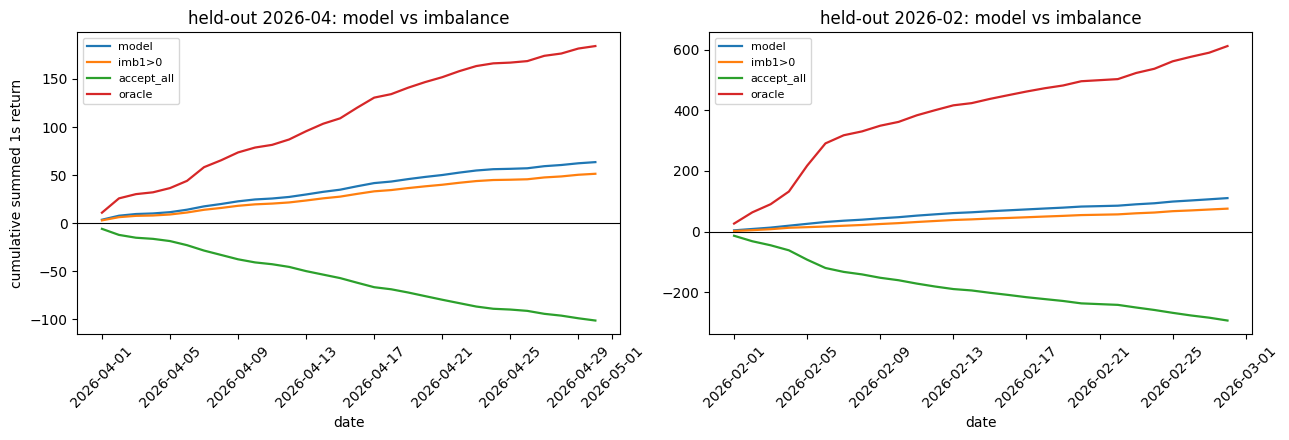

In [7]:
# Reporting for the trained model. Re-run this freely (no retraining): it reads the folds the training
# cell left in FOLD_RES. The score table per held-out month, then equity curves: the cumulative summed
# 1s return over the month for the model vs imb1>0 vs accept-all vs the oracle.
import numpy as np, pandas as pd
import matplotlib.pyplot as plt

# the four selections on one held-out month's frame fr (each a boolean mask over its rows).
def _rules(fr):
    return {"model": fr["pred"].to_numpy() > 0, "imb1>0": fr["imb1"].to_numpy() > 0,
            "accept_all": np.ones(len(fr), bool), "oracle": fr["y_ret"].to_numpy() > 0}

print("=== month-out validation (total = summed 1s return on the held-out month) ===")
rr = []
for m, fr in FOLD_RES.items():
    r = fr["y_ret"].to_numpy(); orc = r[r > 0].sum()                    # oracle total = sum of the positive returns
    for nm, sel in _rules(fr).items():
        rr.append(dict(test=m, rule=nm, n_sel=int(sel.sum()), total=r[sel].sum(),
                       pct_oracle=100 * r[sel].sum() / orc, mean_bps=1e4 * r[sel].mean() if sel.any() else 0.0,
                       win=100 * (r[sel] > 0).mean() if sel.any() else 0.0))
print(pd.DataFrame(rr).to_string(index=False, float_format=lambda v: f"{v:.2f}"))

# equity curve: per held-out month, the running total of each rule's selected 1s return, day by day.
def _cum(fr, sel):
    g = pd.Series(np.where(sel, fr["y_ret"].values, 0.0)).groupby(fr["date"].values).sum().sort_index()
    return pd.to_datetime(g.index, format="%Y%m%d"), g.cumsum().values
fig, axes = plt.subplots(1, len(FOLD_RES), figsize=(13, 4.5))
for ax, (m, fr) in zip(np.atleast_1d(axes), FOLD_RES.items()):
    for nm, sel in _rules(fr).items():
        x, y = _cum(fr, sel); ax.plot(x, y, lw=1.6, label=nm)
    ax.axhline(0, color="black", lw=0.8); ax.set_title(f"held-out {m[:4]}-{m[4:]}: model vs imbalance")
    ax.set_xlabel("date"); ax.tick_params(axis="x", rotation=45); ax.legend(fontsize=8)
axes[0].set_ylabel("cumulative summed 1s return")
plt.tight_layout(); plt.show()

So the model works, on both sides of the data.

Reading held-out April: the full model keeps +63.52 of the summed return, where the plain imb1>0 rule keeps +51.40 and taking everything loses -101.23. On held-out February it is +110.65 against +75.90 and -292.68. As before it takes fewer fills than the imb1 rule and earns more per fill (0.18 vs 0.13 mean bps in April, 0.26 vs 0.15 in February).

One warning I want written down: the feature screens earlier in the notebook use all three months, on purpose. The hidden month is the real test, and I want the feature set chosen on all the data I have. The cost is small but real: the totals above are then a little optimistic as estimates of a new month, because the feature choices saw these two. The folds test the fitted weights; the hidden month tests everything.

Both directions hold (reaching forward to April, back to February), so I trust the recipe for the hidden month: retrain on all three, take iff the prediction is positive.

I want to build another model: a neural network, on the same job. One score per fill, take iff it is positive.


I am taking the same $\phi$ and the same folds: the seventeen features of the model above, and the same month-out split: train two months, test the third, final on all three. Otherwise the two models are not comparable.

For the loss function, my objective is total selected profit, not accuracy. A plain yes/no cross-entropy on $\mathrm{sign}(\pi)$ treats a +0.01 bps winner and a +5 bps winner the same, which is wrong. So the net regresses the 1s profit in bps (squared error), like the trees, and the yes/no is the sign of the output. The size of $\pi$ then weights each sample by how much it matters.

How shallow my network is going to be: two hidden layers of respectively size (32, 16) with the ReLU activation function. Seventeen tabular features do not need depth; extra capacity is just more room to memorize a regime, so I will avoid it to counter overfitting.

The trees split on raw values so they never cared about scale, a neural net does. I standardize every feature on training statistics only. The unsigned risk features are positive and heavy-tailed, so they go in as $\log(1+\cdot)$ first (a monotone map, same information; the depth is already a log). A NaN imbalance (no snapshot before the cutoff) becomes 0 after standardizing, the train mean: no book, no lean.

For the training I use Adam, minibatches of 8192 (millions of rows, big batches keep a pass fast), fixed seed. Early stopping watches a temporal validation slice, the last tenth of the training days. A shuffled validation split would leak the time structure the month-out split is there to respect.

No torch in this venv, so the neural net is sklearn's MLP. I drive it one epoch at a time (`partial_fit`), so the optimizer state carries across epochs and the early stopping is mine, on the temporal slice.

In [6]:
# The neural net. Same phi and same month-out folds as the trees: per fold, standardize on the training
# months only, fit on their first ~90% of days, early-stop on the last tenth (a TEMPORAL validation
# slice, later days only, never a shuffle), then score the held-out month. Final net on all three months.
# One partial_fit call = one epoch, so Adam's state carries across epochs and the stopping rule is mine.
# Seeded everywhere, so a re-run reproduces.
import numpy as np, pandas as pd
from copy import deepcopy
from sklearn.neural_network import MLPRegressor
from sklearn.preprocessing import StandardScaler

NN_RISK = ["vol", "absmove", "rate", "spread", "flips", "absdispq", "btc_amv", "eth_amv"]   # positive, heavy-tailed -> log(1+.); depth is already a log
NN_MAX_EPOCHS, NN_PATIENCE = 60, 5                # stop after 5 epochs with no improvement on the val slice

def _nn_X(df, scaler=None, feats=None, risk=None):   # features -> standardized matrix (fits the scaler if None)
    feats = FEATS if feats is None else feats; risk = NN_RISK if risk is None else risk
    X = df[feats].astype(np.float32).copy()
    X[risk] = np.log1p(X[risk])
    if scaler is None: scaler = StandardScaler().fit(X)              # NaN-aware: nan-mean/var per column
    return np.nan_to_num(scaler.transform(X), nan=0.0).astype(np.float32, copy=False), scaler

def _nn_fit(tr, feats=None, risk=None):
    days = np.sort(tr["date"].unique()); vd = days[-max(1, len(days) // 10):]   # the temporal val slice
    fit, val = tr[~tr["date"].isin(vd)], tr[tr["date"].isin(vd)]
    Xf, scaler = _nn_X(fit, feats=feats, risk=risk); yf = fit["y_bps"].to_numpy()
    Xv, _ = _nn_X(val, scaler, feats=feats, risk=risk); yv = val["y_bps"].to_numpy()
    net = MLPRegressor(hidden_layer_sizes=(32, 16), activation="relu", solver="adam",
                       batch_size=8192, learning_rate_init=1e-3, shuffle=False, random_state=0)
    rng = np.random.default_rng(0); best_mse, best_w, since = np.inf, None, 0
    for ep in range(NN_MAX_EPOCHS):
        order = rng.permutation(len(Xf))          # my own per-epoch shuffle (seeded)
        net.partial_fit(Xf[order], yf[order])     # one full pass, 8192-row minibatches
        mse = float(np.mean((net.predict(Xv) - yv) ** 2))
        if mse < best_mse: best_mse, best_w, since = mse, (deepcopy(net.coefs_), deepcopy(net.intercepts_)), 0
        else: since += 1
        if since >= NN_PATIENCE: break
    net.coefs_, net.intercepts_ = best_w          # roll back to the best-val epoch
    print(f"  {len(days)} train days (last {len(vd)} = validation): stopped after {ep + 1} epochs, best val MSE {best_mse:.3f}")
    return scaler, net

NN_PRED = {}                                      # held-out-month net predictions, keyed like FOLD_RES
for train_m, test_m in FOLDS:
    print(f"fold: train {'+'.join(train_m)} -> test {test_m}")
    tr = F[F.month.isin(train_m)]; te = F[F.month == test_m]
    scaler, net = _nn_fit(tr)
    NN_PRED[test_m] = net.predict(_nn_X(te, scaler)[0])
print("final: all three months")
nn_scaler, nn_final = _nn_fit(F)
print("trained: 2 month-out folds + final (report + overlay in the next cell)")

fold: train 202602+202603 -> test 202604


  59 train days (last 5 = validation): stopped after 13 epochs, best val MSE 2.373


fold: train 202603+202604 -> test 202602


  61 train days (last 6 = validation): stopped after 11 epochs, best val MSE 0.926


final: all three months


  89 train days (last 8 = validation): stopped after 16 epochs, best val MSE 0.948
trained: 2 month-out folds + final (report + overlay in the next cell)


=== NN month-out validation (total = summed 1s return on the held-out month) ===


  test       rule    n_sel   total  pct_oracle  mean_bps    win
202604         nn  3793869   62.51       33.93      0.16  16.76
202604        gbt  3538959   63.52       34.48      0.18  17.50
202604 accept_all  8486600 -101.23      -54.95     -0.12  11.25
202604     oracle   954427  184.23      100.00      1.93 100.00
202602         nn  4202266  108.33       17.71      0.26  30.81
202602        gbt  4234402  110.65       18.09      0.26  30.61
202602 accept_all 11244140 -292.68      -47.86     -0.26  21.93
202602     oracle  2466114  611.55      100.00      2.48 100.00


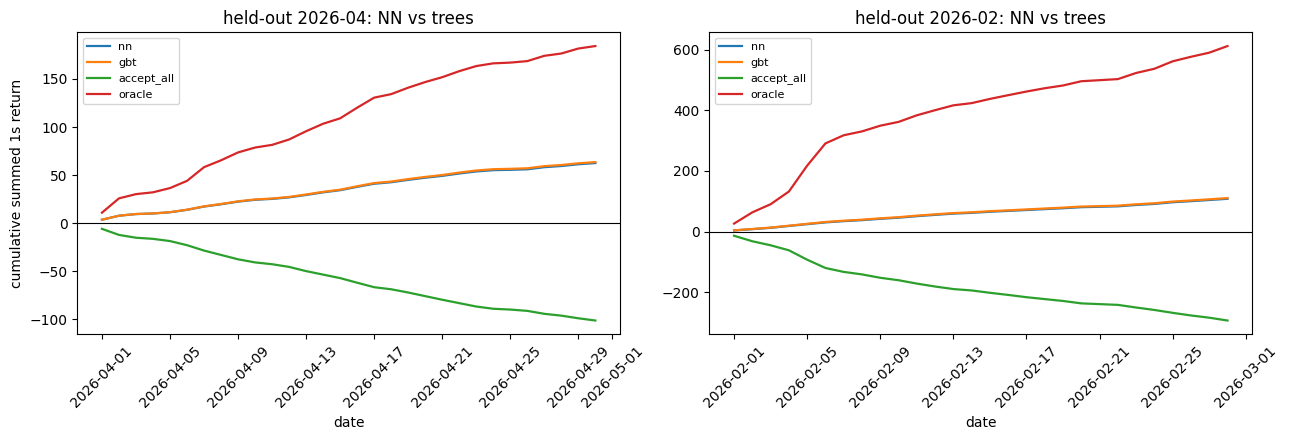

In [9]:
# Reporting for the net, mirroring the tree report: the same score table per held-out month, then
# equity curves overlaying the NN and the trees (with accept-all and the oracle) on one axes per fold.
# Reads FOLD_RES (tree preds) and NN_PRED (net preds) and reuses _cum; re-run freely, no retraining.
import numpy as np, pandas as pd
import matplotlib.pyplot as plt

def _nn_rules(fr, m):
    return {"nn": NN_PRED[m] > 0, "gbt": fr["pred"].to_numpy() > 0,
            "accept_all": np.ones(len(fr), bool), "oracle": fr["y_ret"].to_numpy() > 0}

print("=== NN month-out validation (total = summed 1s return on the held-out month) ===")
rr = []
for m, fr in FOLD_RES.items():
    r = fr["y_ret"].to_numpy(); orc = r[r > 0].sum()
    for nm, sel in _nn_rules(fr, m).items():
        rr.append(dict(test=m, rule=nm, n_sel=int(sel.sum()), total=r[sel].sum(),
                       pct_oracle=100 * r[sel].sum() / orc, mean_bps=1e4 * r[sel].mean() if sel.any() else 0.0,
                       win=100 * (r[sel] > 0).mean() if sel.any() else 0.0))
print(pd.DataFrame(rr).to_string(index=False, float_format=lambda v: f"{v:.2f}"))

fig, axes = plt.subplots(1, len(FOLD_RES), figsize=(13, 4.5))
for ax, (m, fr) in zip(np.atleast_1d(axes), FOLD_RES.items()):
    for nm, sel in _nn_rules(fr, m).items():
        x, y = _cum(fr, sel); ax.plot(x, y, lw=1.6, label=nm)
    ax.axhline(0, color="black", lw=0.8); ax.set_title(f"held-out {m[:4]}-{m[4:]}: NN vs trees")
    ax.set_xlabel("date"); ax.tick_params(axis="x", rotation=45); ax.legend(fontsize=8)
axes[0].set_ylabel("cumulative summed 1s return")
plt.tight_layout(); plt.show()

Close, but the trees keep the lead.

On held-out April the net keeps +62.51 where the trees keep +63.52; on February +108.33 against +110.65. The curves sit almost on top of each other. In April the net takes more fills for less per fill (0.16 vs 0.18 mean bps); its total ends slightly lower on both folds.

I read that as a good sign: the information is in $\phi$, not in the model type.

For the submission of the first problem, I keep the trees: better totals on both folds, native NaN handling, no scaler to carry around.

# 2. The second problem: deep fills

## 2.1 Brainstorming

We give this model for the first problem. Now we tackle the second, harder one: the deep fills. We redo a small brainstorming first. Then we build the same two models.

The README extension flips one flag: `BEST_PRICE_TRADES = False`. This keeps only the trades that printed strictly past the best price seen at the cutoff. A trade lands there only when an aggressor takes the whole best level and keeps going. Such sweeps come from large, likely informed orders. So we expect worse adverse selection than before. First we build this set and look at it.

In [7]:
# The deep sample set. Same build as the starter cell, one change: best_price_trades=False. Cached
# like the main set; delete the file (or set REBUILD_DEEP = True) to rebuild. Then the per-month
# shape of the set: how many fills, how many flat / win / lose, and the accept-all and oracle totals.
import pandas as pd

DEEP_PATH = ROOT / "data/samples/starter_samples_deep.parquet"
REBUILD_DEEP = False
if not REBUILD_DEEP and DEEP_PATH.exists():
    samples_deep = pd.read_parquet(DEEP_PATH)
    print(f"loaded {len(samples_deep):,} cached rows from {DEEP_PATH}")
else:
    samples_deep = build_samples(market_data_root=MARKET_DATA_PATH, start_date=START_DATE, end_date=END_DATE,
                                 latency_us=LATENCY_US, select_window_us=SELECT_WINDOW_US,
                                 best_price_trades=False, rebate_bps=REBATE_BPS,
                                 profit_horizon_us=PROFIT_HORIZON_US, workers=WORKERS)
    DEEP_PATH.parent.mkdir(parents=True, exist_ok=True)
    samples_deep.to_parquet(DEEP_PATH, index=False, compression="zstd")
    print(f"wrote {len(samples_deep):,} rows to {DEEP_PATH}")

rows = []
groups = list(samples_deep.groupby(samples_deep["date"].str[:6])) + [("ALL", samples_deep)]
for m, g in groups:
    r = g["profit_1s_with_rebate"].to_numpy()
    rows.append(dict(month=m, n=len(g), zero_pct=100 * (r == 0).mean(), win_pct=100 * (r > 0).mean(),
                     loss_pct=100 * (r < 0).mean(), mean_bps=1e4 * r.mean(),
                     accept_all=r.sum(), oracle=r[r > 0].sum()))
print()
print(pd.DataFrame(rows).to_string(index=False, float_format=lambda v: f"{v:.2f}"))

loaded 1,530,418 cached rows from data/samples/starter_samples_deep.parquet



 month       n  zero_pct  win_pct  loss_pct  mean_bps  accept_all  oracle
202602  814859     21.40    26.76     51.84     -0.91      -74.37   74.30
202603  471280     28.98    21.16     49.86     -0.83      -39.22   25.77
202604  244279     36.95    17.01     46.04     -0.78      -19.17   10.00
   ALL 1530418     26.21    23.48     50.31     -0.87     -132.76  110.07


The table says the problem got much harder. The set is small: 1,530,418 fills, about 5% of the first set. The flat share drops from 57% to 26%. Half the fills lose. Only 23% win. The average fill costs -0.87 bps. Taking everything loses -132.76 over the period. The oracle only makes +110.07. And most deep fills happen in February, the most volatile month. So these fills move, and they mostly move against us. The adverse selection story from the README is real.

Do the seventeen features still work on this set? I run the two screens from before. For direction: corr with profit, and the partial over {imb1, dimb, btc, eth} (each feature is scored against the other three). For risk: the partial of $|\pi|$ over the trio {v, |m|, $\rho$}. I add two things special to this set. First, deeper book imbalance (imb5, imb10): these fills go past level 1, so maybe the deeper book matters now. Second, the print displacement absdispq: here every fill is past the stale quote, so it measures how deep the sweep went.

In [8]:
# The two screens on the deep set, over all 89 days. Direction: corr + partial over the other
# direction features. Risk: partial of |pi| over {vol, absmove, rate}, with the trio's own
# leave-one-out partials as the reference. imb5/imb10 need the 10-level book (size_levels=10).
# Uses the shared toolbox: load_book / load_trades / asof / side_sign / corr / decile_profit /
# partial_corr, plus imb1_of.
import numpy as np, pandas as pd

dp_by_day = dict(tuple(samples_deep[["date", "events_before_server_time", "dir", "price", "volume",
                                     "profit_1s_with_rebate", "sol_mid_move_1s_bps"]].groupby("date", sort=True)))
DP_B = [f"bid_size_{i}" for i in range(1, 11)]
DP_A = [f"ask_size_{i}" for i in range(1, 11)]

def _dp_day(day):
    s = dp_by_day[day]; c = s["events_before_server_time"].to_numpy(); sgn = side_sign(s["dir"])
    bk = load_book("SOLUSDT", day, size_levels=10); bt = bk.server_time.to_numpy()
    bid, ask = bk.bid_price_1.to_numpy(), bk.ask_price_1.to_numpy()
    mid = (bid + ask) / 2
    b5, a5 = bk[DP_B[:5]].sum(axis=1).to_numpy(), bk[DP_A[:5]].sum(axis=1).to_numpy()
    b10, a10 = bk[DP_B].sum(axis=1).to_numpy(), bk[DP_A].sum(axis=1).to_numpy()
    with np.errstate(invalid="ignore", divide="ignore"):
        i1 = imb1_of(bk); i5 = (b5 - a5) / (b5 + a5); i10 = (b10 - a10) / (b10 + a10)
    cur, prev = asof(bt, i1, c), asof(bt, i1, c, 1_000_000)
    ihi = np.searchsorted(bt, c, "right"); ilo = np.searchsorted(bt, c - 1_000_000, "right")
    Sc = np.concatenate([[0.0], np.nancumsum(i1)])
    Cc = np.concatenate([[0.0], np.cumsum(~np.isnan(i1))])
    ncw = Cc[ihi] - Cc[ilo]
    avg = np.where(ncw > 0, (Sc[ihi] - Sc[ilo]) / np.maximum(ncw, 1), np.nan)
    flip = np.concatenate([[0.0], (np.diff(mid) != 0).astype(float)])
    Fc = np.concatenate([[0.0], np.cumsum(flip)])
    flips = (Fc[ihi] - Fc[ilo]).astype(float); flips[ihi == 0] = np.nan
    q_same = np.where(sgn > 0, asof(bt, bid, c), asof(bt, ask, c))
    tt = load_trades("SOLUSDT", day).server_time.to_numpy()
    rate = (np.searchsorted(tt, c, "right") - np.searchsorted(tt, c - 1_000_000, "right")).astype(float)
    out = {"y": s["profit_1s_with_rebate"].to_numpy() * 1e4,
           "imb1": cur * sgn, "imb5": asof(bt, i5, c) * sgn, "imb10": asof(bt, i10, c) * sgn,
           "dimb": (cur - prev) * sgn, "devavg": (cur - avg) * sgn,
           "vol": s["volume"].to_numpy(), "absmove": np.abs(s["sol_mid_move_1s_bps"].to_numpy()), "rate": rate,
           "spread": asof(bt, (ask - bid) / mid, c) * 1e4,
           "depth": np.log1p(asof(bt, bk.bid_size_1.to_numpy() + bk.ask_size_1.to_numpy(), c)),
           "flips": flips,
           "absdispq": np.abs(s["price"].to_numpy() - q_same) / asof(bt, mid, c) * 1e4}
    for nm, sym in (("btc", "BTCUSDT"), ("eth", "ETHUSDT")):
        xb = load_book(sym, day, size_levels=1); xt = xb.server_time.to_numpy()
        with np.errstate(invalid="ignore", divide="ignore"):
            xi = imb1_of(xb)
        xmid = (xb.bid_price_1.to_numpy() + xb.ask_price_1.to_numpy()) / 2
        out[nm] = asof(xt, xi, c) * sgn
        out[nm + "_amv"] = np.abs(asof(xt, xmid, c) - asof(xt, xmid, c, 1_000_000)) / asof(xt, xmid, c) * 1e4
    return pd.DataFrame(out)

dp = pd.concat([_dp_day(d) for d in sorted(dp_by_day)], ignore_index=True)
y = dp["y"].to_numpy(); absy = np.abs(y)
DIR4 = ["imb1", "dimb", "btc", "eth"]

print(f"samples: {len(dp):,}\n")
print("=== direction on deep fills (partial = over the other direction features) ===")
rows = []
for f in ["imb1", "dimb", "btc", "eth", "devavg", "imb5", "imb10"]:
    ctl = {k: dp[k].to_numpy() for k in DIR4 if k != f}
    d = decile_profit(dp[f], y)["mean_bps"]
    rows.append(dict(feature=f, corr_y=corr(dp[f], y), partial=partial_corr(y, dp[f].to_numpy(), ctl),
                     dec_bot=d.iloc[0], dec_top=d.iloc[-1], green=int((d > 0).sum())))
print(pd.DataFrame(rows).to_string(index=False, float_format=lambda v: f"{v:+.4f}"))

print("\n=== risk on deep fills: partial(|y|, X | {vol, absmove, rate}) ===")
TRIO = ["vol", "absmove", "rate"]
for f in TRIO:
    others = {k: dp[k].to_numpy() for k in TRIO if k != f}
    print(f"  ref {f:8s}: {partial_corr(absy, dp[f].to_numpy(), others):+.4f}")
ctl_r = {k: dp[k].to_numpy() for k in TRIO}
for f in ["spread", "depth", "flips", "btc_amv", "eth_amv", "absdispq"]:
    print(f"  {f:8s}: partial {partial_corr(absy, dp[f].to_numpy(), ctl_r):+.4f}")
q = dp["absdispq"].dropna()
print("\nabsdispq quantiles (bps):", {p: round(float(q.quantile(p)), 2) for p in [0.01, 0.25, 0.5, 0.75, 0.99]})

samples: 1,530,418

=== direction on deep fills (partial = over the other direction features) ===


feature  corr_y  partial  dec_bot  dec_top  green
   imb1 -0.0324  -0.0299  -0.5898  -1.0692      0
   dimb -0.0166  +0.0035  -0.7795  -0.9783      0
    btc -0.0031  +0.0044  -0.9363  -0.8951      0
    eth -0.0001  +0.0082  -0.9633  -0.8849      0
 devavg -0.0165  +0.0081  -0.7867  -0.9708      0
   imb5 -0.0013  +0.0132  -0.9153  -0.9144      0
  imb10 +0.0032  +0.0120  -0.9159  -0.8886      0

=== risk on deep fills: partial(|y|, X | {vol, absmove, rate}) ===
  ref vol     : +0.0027
  ref absmove : +0.1830


  ref rate    : +0.1306
  spread  : partial +0.0799


  depth   : partial -0.1823
  flips   : partial +0.3138


  btc_amv : partial +0.1043
  eth_amv : partial +0.1284


  absdispq: partial +0.0488

absdispq quantiles (bps): {0.01: 0.95, 0.25: 1.12, 0.5: 1.17, 0.75: 1.21, 0.99: 3.18}


Direction is dead here. imb1's corr with profit is -0.03; on the first set it was about +0.20. Every decile of every direction feature is red. The deeper imbalance does not help either: imb5 and imb10 sit near +0.013, with red deciles too. So the README's hint does not work as direction on this set. The reason is simple. These fills exist because an aggressor already swept through the book. The informed order already acted. The stale book lean tells us nothing more about the next second.

Risk still works, and works harder than before. flips is at +0.31, depth at -0.18, the cross moves at +0.10 and +0.13, spread at +0.08 (five times its value on the first set). vol stops mattering here (+0.003): on this set the size of the fill does not matter, the sweep does. absdispq has a narrow range: the median displacement is 1.17 bps, about one tick, so most deep fills sit just one level past the stale quote.

The seventeen features stay (the direction ones cost nothing and the trees can ignore them). The next idea adds two more.

One more idea (that I learned late): iceberg and hidden orders. An iceberg order is a big resting order that shows only a small visible slice; each time the slice is traded away, the exchange shows the next slice at the same price. A hidden order does not show at all. Our data has no order ids, so we cannot see these orders. But we can see their footprint, per side, over the last second before the cutoff:

- replenishment (`repl`): the visible size added to a side while it was being hit. I take the change of the ten-level size on that side and add back what the tape consumed there. Iceberg refills land here, and so do makers who re-quote fast.
- excess execution (`exc`): the volume that traded on a side beyond everything that side displayed at the start of the window. The visible book alone cannot explain that volume; something hidden filled part of it.

Why it matters here: a deep fill lives or dies on whether the sweep gets absorbed, and hidden size on my side is exactly the absorption the visible book does not show. I build a my-side and an opposite-side version of both (my side = the side I rest on) and run the two screens as always.

In [9]:
# The hidden-liquidity footprint, over the deep set. Per side, over (c-1s, c]:
#   cons = tape volume that hit that side; V = the ten-level visible size of that side
#   repl = V(c) - V(c-1s) + cons     (size added while being hit: refills and re-quotes)
#   exc  = max(0, cons - V(c-1s))    (volume beyond everything displayed at the window start)
# The two screens as always; the controls come from the dp frame of the screens cell above.
import numpy as np, pandas as pd

hb_by_day = dict(tuple(samples_deep[["date", "events_before_server_time", "dir"]].groupby("date", sort=True)))
HB_SB = [f"bid_size_{i}" for i in range(1, 11)]; HB_SA = [f"ask_size_{i}" for i in range(1, 11)]

def _hb_day(day):
    s = hb_by_day[day]; c = s["events_before_server_time"].to_numpy(); sgn = side_sign(s["dir"])
    bk = load_book("SOLUSDT", day, size_levels=10); bt = bk.server_time.to_numpy()
    Vb = bk[HB_SB].sum(axis=1).to_numpy(); Va = bk[HB_SA].sum(axis=1).to_numpy()
    vb_c, vb_p = asof(bt, Vb, c), asof(bt, Vb, c, 1_000_000)
    va_c, va_p = asof(bt, Va, c), asof(bt, Va, c, 1_000_000)
    tr = load_trades("SOLUSDT", day)
    tt = tr.server_time.to_numpy(); tv = tr.volume.to_numpy(); ad = tr.aggressor_dir.to_numpy()
    Cb = np.concatenate([[0.0], np.cumsum(np.where(ad == 1, tv, 0.0))])   # sells hitting the bids
    Ca = np.concatenate([[0.0], np.cumsum(np.where(ad == 0, tv, 0.0))])   # buys lifting the asks
    hi = np.searchsorted(tt, c, "right"); lo = np.searchsorted(tt, c - 1_000_000, "right")
    cons_b, cons_a = Cb[hi] - Cb[lo], Ca[hi] - Ca[lo]
    repl_b = vb_c - vb_p + cons_b; repl_a = va_c - va_p + cons_a
    exc_b = np.maximum(0.0, cons_b - vb_p); exc_a = np.maximum(0.0, cons_a - va_p)
    bid = sgn > 0
    return pd.DataFrame({"repl_my": np.where(bid, repl_b, repl_a), "repl_opp": np.where(bid, repl_a, repl_b),
                         "exc_my": np.log1p(np.where(bid, exc_b, exc_a)),
                         "exc_opp": np.log1p(np.where(bid, exc_a, exc_b))})

HID = ["repl_my", "repl_opp", "exc_my", "exc_opp"]
hb = pd.concat([_hb_day(d) for d in sorted(hb_by_day)], ignore_index=True)   # row-aligned with dp
y = dp["y"].to_numpy(); absy = np.abs(y)
print(f"how often the footprint fires: exc_my > 0 on {100*(hb['exc_my']>0).mean():.1f}% of fills, exc_opp on {100*(hb['exc_opp']>0).mean():.1f}%\n")
ctl_d = {k: dp[k].to_numpy() for k in ["imb1", "dimb", "btc", "eth"]}
ctl_r = {k: dp[k].to_numpy() for k in ["vol", "absmove", "rate"]}
print("direction screen (partial over {imb1, dimb, btc, eth}):")
for f in HID:
    d = decile_profit(hb[f], y)["mean_bps"]
    print(f"  {f:9s}: corr {corr(hb[f], y):+.4f}  partial {partial_corr(y, hb[f].to_numpy(), ctl_d):+.4f}  "
          f"dec bot {d.iloc[0]:+.3f} top {d.iloc[-1]:+.3f} green {int((d > 0).sum())}")
print("\nrisk screen (partial of |y| over {vol, absmove, rate}):")
for f in HID:
    print(f"  {f:9s}: partial {partial_corr(absy, hb[f].to_numpy(), ctl_r):+.4f}")

how often the footprint fires: exc_my > 0 on 1.0% of fills, exc_opp on 1.0%

direction screen (partial over {imb1, dimb, btc, eth}):


  repl_my  : corr +0.0030  partial +0.0079  dec bot -0.807 top -0.896 green 0


  repl_opp : corr +0.0051  partial +0.0038  dec bot -0.910 top -0.805 green 0


  exc_my   : corr -0.0011  partial +0.0004  dec bot -0.867 top -0.867 green 0


  exc_opp  : corr +0.0043  partial +0.0059  dec bot -0.867 top -0.867 green 0

risk screen (partial of |y| over {vol, absmove, rate}):
  repl_my  : partial -0.0017


  repl_opp : partial -0.0549
  exc_my   : partial +0.0363


  exc_opp  : partial +0.0083


The footprint is real but rare: something hidden fills part of a sweep on about 1% of these windows. As direction all four columns are dead (partials at or under +0.008, every decile red). As risk, two of them carry a little size information: repl_opp at -0.0549 and exc_my at +0.0363 (for scale, flips printed +0.3138 above). A clear signal counts whatever its sign (the sign only says which way the size moves), so those two go into the deep model. The other two sit at noise level and stay out.

## 2.2 Model building

Now the models, exactly as before. Same recipe. The features are the seventeen from the first problem plus the two hidden-size columns from the iceberg cell above, so nineteen. Same trees, same folds, same rule: take a fill iff the predicted 1 s profit is positive. Then the same net, with the same loss and the same temporal early stopping. One thing to expect from the table above: on this set half the fills lose. So the model's main job here is to skip.

In [10]:
# Deep model training. Same trees, same folds; the features are the seventeen plus the two
# hidden-size columns from the iceberg cell (attached below, row-aligned by construction). The feature
# build reuses _feat_day (it takes the per-day dict as an argument) and caches to its own file.
# Three fits: two month-out folds and the final model.
import numpy as np, pandas as pd
import pyarrow.parquet as pq

FEAT_DEEP_PATH = ROOT / "data/samples/model_features_deep.parquet"
REBUILD_DEEP_FEATURES = False
_have_d = FEAT_DEEP_PATH.exists() and set(NEED) <= set(pq.ParquetFile(FEAT_DEEP_PATH).schema.names)
if not REBUILD_DEEP_FEATURES and _have_d:
    F_D = pd.read_parquet(FEAT_DEEP_PATH); print(f"loaded deep features: {len(F_D):,} rows (cache)")
else:
    mf_d = samples_deep[["date", "events_before_server_time", "dir", "price", "volume", "sol_mid_move_1s_bps", "profit_1s_with_rebate"]]
    deep_by_day = dict(tuple(mf_d.groupby("date", sort=True)))
    F_D = pd.concat([_feat_day(d, deep_by_day) for d in sorted(deep_by_day)], ignore_index=True)
    FEAT_DEEP_PATH.parent.mkdir(parents=True, exist_ok=True); F_D.to_parquet(FEAT_DEEP_PATH, index=False)
    print(f"built + cached deep features: {len(F_D):,} rows")

F_D["repl_opp"] = hb["repl_opp"].to_numpy(np.float32)
F_D["exc_my"] = hb["exc_my"].to_numpy(np.float32)
FEATS_DEEP = FEATS + ["repl_opp", "exc_my"]

FOLD_RES_D = {}
for train_m, test_m in FOLDS:
    tr = F_D[F_D.month.isin(train_m)]; te = F_D[F_D.month == test_m]
    pred = _make().fit(tr[FEATS_DEEP], tr["y_bps"]).predict(te[FEATS_DEEP])
    FOLD_RES_D[test_m] = te[["date", "y_ret", "imb1"]].assign(pred=pred).reset_index(drop=True)
final_deep = _make().fit(F_D[FEATS_DEEP], F_D["y_bps"])
print(f"trained: 2 month-out folds + final on all {len(F_D):,} deep samples (report next cell)")

loaded deep features: 1,530,418 rows (cache)


trained: 2 month-out folds + final on all 1,530,418 deep samples (report next cell)


=== deep set: month-out validation (total = summed 1s return on the held-out month) ===
  test       rule  n_sel  total  pct_oracle  mean_bps    win
202604      model   1969   0.04        0.40      0.21  44.44
202604     imb1>0  42465  -4.38      -43.80     -1.03  21.43
202604 accept_all 244279 -19.17     -191.66     -0.78  17.01
202604     oracle  41543  10.00      100.00      2.41 100.00
202602      model  19314  -1.15       -1.55     -0.60  41.26
202602     imb1>0 149127 -15.95      -21.46     -1.07  30.42
202602 accept_all 814859 -74.37     -100.10     -0.91  26.76
202602     oracle 218065  74.30      100.00      3.41 100.00


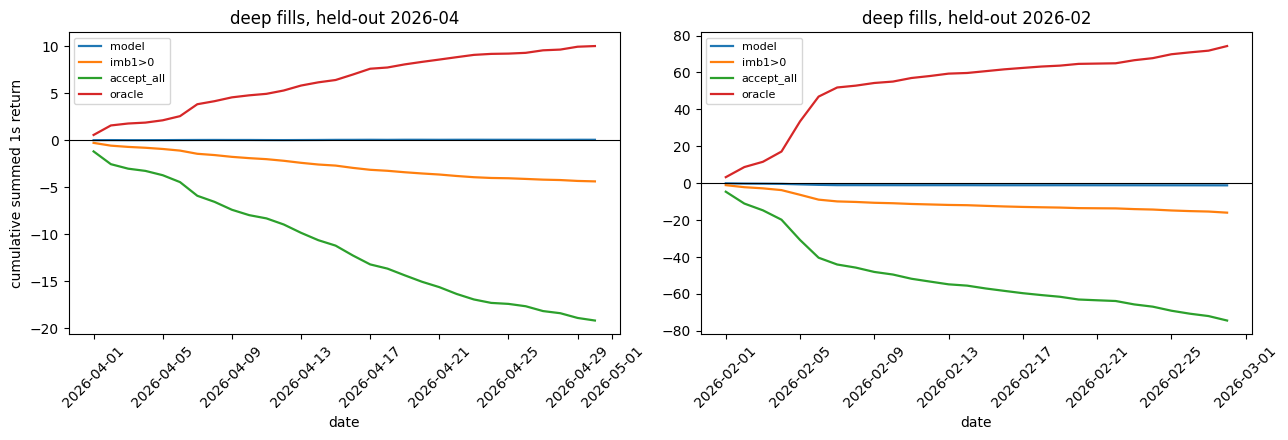

In [11]:
# Reporting for the deep model, same shape as the first report: the score table per held-out month,
# then the equity curves. Reads FOLD_RES_D; reuses _rules and _cum from the first report cell.
import numpy as np, pandas as pd
import matplotlib.pyplot as plt

print("=== deep set: month-out validation (total = summed 1s return on the held-out month) ===")
rr = []
for m, fr in FOLD_RES_D.items():
    r = fr["y_ret"].to_numpy(); orc = r[r > 0].sum()
    for nm, sel in _rules(fr).items():
        rr.append(dict(test=m, rule=nm, n_sel=int(sel.sum()), total=r[sel].sum(),
                       pct_oracle=100 * r[sel].sum() / orc, mean_bps=1e4 * r[sel].mean() if sel.any() else 0.0,
                       win=100 * (r[sel] > 0).mean() if sel.any() else 0.0))
print(pd.DataFrame(rr).to_string(index=False, float_format=lambda v: f"{v:.2f}"))

fig, axes = plt.subplots(1, len(FOLD_RES_D), figsize=(13, 4.5))
for ax, (m, fr) in zip(np.atleast_1d(axes), FOLD_RES_D.items()):
    for nm, sel in _rules(fr).items():
        x, yv = _cum(fr, sel); ax.plot(x, yv, lw=1.6, label=nm)
    ax.axhline(0, color="black", lw=0.8); ax.set_title(f"deep fills, held-out {m[:4]}-{m[4:]}")
    ax.set_xlabel("date"); ax.tick_params(axis="x", rotation=45); ax.legend(fontsize=8)
axes[0].set_ylabel("cumulative summed 1s return")
plt.tight_layout(); plt.show()

The models barely take anything.

On held-out April the trees pick 1,969 fills out of 244,279 and end at +0.04. On held-out February they pick 19,314 out of 814,859 and end at -1.15. Both are far better than the other rules: the imb1>0 rule loses -4.38 and -15.95, taking everything loses -19.17 and -74.37. But the totals themselves sit at zero. The reading is plain: on this set the expected profit is negative almost everywhere, so a rule that only takes positive predictions correctly takes almost nothing. What it does take wins more than 40% of the time (44% in April, 41% in February). So the model does find the least bad fills. There is just very little money in them.

That is the honest answer for the deep problem, at this horizon, with these features.

Before I accept the zero, I test other ideas, all in one cell:

- the prior: I train the first problem's trees on the same training months (on the full set) and feed their prediction to the deep model as one extra feature. The first problem's model saw thirty million fills; maybe the deep model can lean on what it learned. The prior never sees the held-out month.
- turn-around signals: the signed move and the signed trade flow. Both failed as momentum on the first problem. Deep fills are where a reversal signal would show up, if one exists: maybe after a sweep the price comes back. In the code: `smove`, `stfi`.
- the hour of the day (UTC). Deep fills cluster in time; maybe some hours are safer.
- a smaller leaf minimum: `min_samples_leaf = 1000` was sized for thirty million rows, and this set is twenty times smaller, so I scan a small grid. One warning, written down on purpose: picking hyperparameters by their held-out totals is selection on the test months. I allow it in this one cell only, as an upper bound: if even that cannot go positive, nothing here can.

In [12]:
# The rescue attempts, one cell. Reference row "base" = the deep model above (same trees, same phi).
# prior = the first problem's trees fit on the SAME training months of the FULL set, scored on the
# deep rows, fed as one extra feature. smove/stfi/hour are computed here (causal reads, as always).
# The leaf grid is selection on the held-out months, allowed here only as an upper bound.
import numpy as np, pandas as pd
from sklearn.ensemble import HistGradientBoostingRegressor

rs_by_day = dict(tuple(samples_deep[["date", "events_before_server_time", "dir",
                                     "sol_mid_move_1s_bps"]].groupby("date", sort=True)))

def _rs_day(day):
    s = rs_by_day[day]; c = s["events_before_server_time"].to_numpy(); sgn = side_sign(s["dir"])
    tr = load_trades("SOLUSDT", day)
    tt = tr.server_time.to_numpy(); tv = tr.volume.to_numpy()
    tsig = np.where(tr.aggressor_dir.to_numpy() == 0, 1.0, -1.0)      # 0 = bid aggressor = buyer
    CB = np.concatenate([[0.0], np.cumsum(tsig * tv)]); CV = np.concatenate([[0.0], np.cumsum(tv)])
    hi = np.searchsorted(tt, c, "right"); lo = np.searchsorted(tt, c - 1_000_000, "right")
    num, den = CB[hi] - CB[lo], CV[hi] - CV[lo]
    with np.errstate(invalid="ignore", divide="ignore"):
        stfi = np.where(den > 0, num / den, 0.0) * sgn
    return pd.DataFrame({"smove": sgn * s["sol_mid_move_1s_bps"].to_numpy(), "stfi": stfi,
                         "hour": ((c // 3_600_000_000) % 24).astype(float)})

F_R = F_D.copy()
ex = pd.concat([_rs_day(d) for d in sorted(rs_by_day)], ignore_index=True)
for k in ("smove", "stfi", "hour"):
    F_R[k] = ex[k].to_numpy(np.float32)

def _mk(msl=1000, l2=1.0):
    return HistGradientBoostingRegressor(loss="squared_error", learning_rate=0.05, max_iter=300,
                                         max_leaf_nodes=63, min_samples_leaf=msl, l2_regularization=l2,
                                         random_state=0, early_stopping=True, validation_fraction=0.1,
                                         n_iter_no_change=20)

print("month-out totals per rescue (base = the deep model above):")
for train_m, test_m in FOLDS:
    prior = _mk().fit(F[F.month.isin(train_m)][FEATS], F[F.month.isin(train_m)]["y_bps"])
    F_R["prior"] = prior.predict(F_R[FEATS]).astype(np.float32)
    tr = F_R[F_R.month.isin(train_m)]; te = F_R[F_R.month == test_m]
    r = te["y_ret"].to_numpy()
    print(f"held-out {test_m}:")
    for nm, feats, msl, l2 in [("base", FEATS_DEEP, 1000, 1.0),
                               ("+signals", FEATS_DEEP + ["smove", "stfi", "hour"], 1000, 1.0),
                               ("+prior", FEATS_DEEP + ["prior"], 1000, 1.0),
                               ("leaf 200", FEATS_DEEP, 200, 1.0), ("leaf 50", FEATS_DEEP, 50, 1.0),
                               ("leaf 200, l2 10", FEATS_DEEP, 200, 10.0), ("leaf 50, l2 10", FEATS_DEEP, 50, 10.0)]:
        pred = _mk(msl, l2).fit(tr[feats], tr["y_bps"]).predict(te[feats])
        sel = pred > 0
        print(f"  {nm:16s} n_sel {int(sel.sum()):>7,}  total {r[sel].sum():+7.2f}", flush=True)

month-out totals per rescue (base = the deep model above):


held-out 202604:


  base             n_sel   1,969  total   +0.04


  +signals         n_sel   1,961  total   +0.04


  +prior           n_sel   2,650  total   -0.02


  leaf 200         n_sel   1,217  total   +0.02


... (7 outputs left out)

  leaf 200         n_sel  25,116  total   -1.88


  leaf 50          n_sel  19,575  total   -1.35


  leaf 200, l2 10  n_sel  19,589  total   -1.46


  leaf 50, l2 10   n_sel  17,912  total   -1.39


None of it works. On held-out April the totals stay around zero (the best reach +0.04). On held-out February every idea makes things worse than the base model: the signals push it to -1.98, the prior to -2.72, and every leaf setting stays negative. The prior is worth one sentence: the first problem's model knows direction, and on these fills direction misleads, because a deep fill happens exactly after the informed order pushed through the book. And remember above: the leaf grid was allowed to pick its settings on the held-out months, and even that does not go positive.

So the zero stands. The deep set does not pay at this horizon with this information.

I do now a neural net to see if he catches something the tree doesn't.

In [13]:
# The deep net. Same architecture, same loss, same temporal early stopping as the first net, on the
# deep feature set. Reuses _nn_X and _nn_fit (they take the feature list as an argument).
NN_PRED_D = {}
for train_m, test_m in FOLDS:
    print(f"fold: train {'+'.join(train_m)} -> test {test_m}")
    tr = F_D[F_D.month.isin(train_m)]; te = F_D[F_D.month == test_m]
    scaler_d, net_d = _nn_fit(tr, feats=FEATS_DEEP)
    NN_PRED_D[test_m] = net_d.predict(_nn_X(te, scaler_d, feats=FEATS_DEEP)[0])
print("final: all three months")
nn_scaler_d, nn_final_d = _nn_fit(F_D, feats=FEATS_DEEP)
print("trained: 2 month-out folds + final (report next cell)")

fold: train 202602+202603 -> test 202604


  59 train days (last 5 = validation): stopped after 30 epochs, best val MSE 13.299
fold: train 202603+202604 -> test 202602


  61 train days (last 6 = validation): stopped after 16 epochs, best val MSE 5.589
final: all three months


  89 train days (last 8 = validation): stopped after 17 epochs, best val MSE 5.355
trained: 2 month-out folds + final (report next cell)


=== deep set: NN month-out validation (total = summed 1s return on the held-out month) ===
  test       rule  n_sel  total  pct_oracle  mean_bps    win
202604         nn   1281   0.00        0.05      0.04  40.28
202604        gbt   1969   0.04        0.40      0.21  44.44
202604 accept_all 244279 -19.17     -191.66     -0.78  17.01
202604     oracle  41543  10.00      100.00      2.41 100.00
202602         nn   4399  -0.00       -0.00     -0.00  43.99
202602        gbt  19314  -1.15       -1.55     -0.60  41.26
202602 accept_all 814859 -74.37     -100.10     -0.91  26.76
202602     oracle 218065  74.30      100.00      3.41 100.00


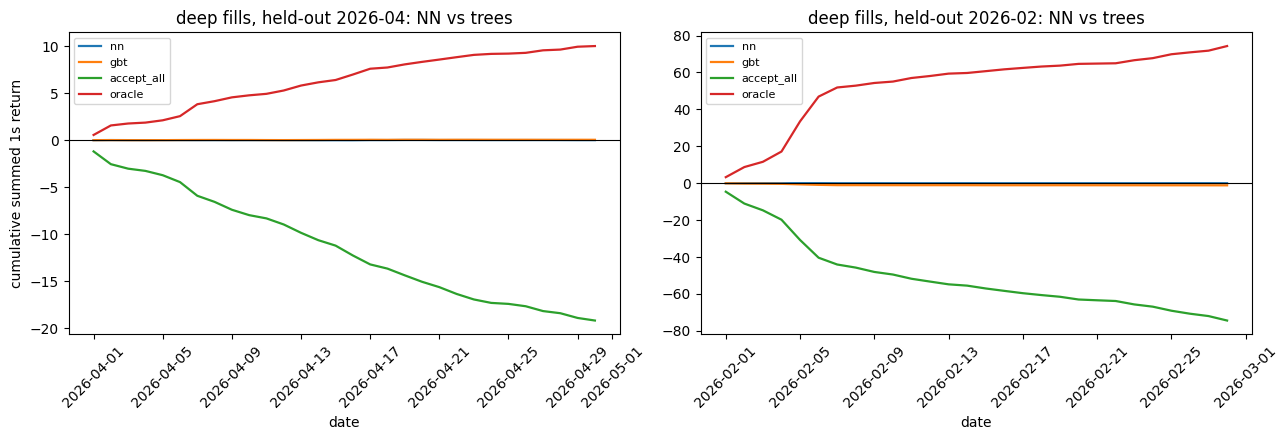

In [14]:
# Reporting for the deep net, same shape as before: the score table, then equity curves overlaying
# the net and the trees (with accept-all and the oracle). Reads FOLD_RES_D and NN_PRED_D; reuses _cum.
import numpy as np, pandas as pd
import matplotlib.pyplot as plt

def _nn_rules_d(fr, m):
    return {"nn": NN_PRED_D[m] > 0, "gbt": fr["pred"].to_numpy() > 0,
            "accept_all": np.ones(len(fr), bool), "oracle": fr["y_ret"].to_numpy() > 0}

print("=== deep set: NN month-out validation (total = summed 1s return on the held-out month) ===")
rr = []
for m, fr in FOLD_RES_D.items():
    r = fr["y_ret"].to_numpy(); orc = r[r > 0].sum()
    for nm, sel in _nn_rules_d(fr, m).items():
        rr.append(dict(test=m, rule=nm, n_sel=int(sel.sum()), total=r[sel].sum(),
                       pct_oracle=100 * r[sel].sum() / orc, mean_bps=1e4 * r[sel].mean() if sel.any() else 0.0,
                       win=100 * (r[sel] > 0).mean() if sel.any() else 0.0))
print(pd.DataFrame(rr).to_string(index=False, float_format=lambda v: f"{v:.2f}"))

fig, axes = plt.subplots(1, len(FOLD_RES_D), figsize=(13, 4.5))
for ax, (m, fr) in zip(np.atleast_1d(axes), FOLD_RES_D.items()):
    for nm, sel in _nn_rules_d(fr, m).items():
        x, yv = _cum(fr, sel); ax.plot(x, yv, lw=1.6, label=nm)
    ax.axhline(0, color="black", lw=0.8); ax.set_title(f"deep fills, held-out {m[:4]}-{m[4:]}: NN vs trees")
    ax.set_xlabel("date"); ax.tick_params(axis="x", rotation=45); ax.legend(fontsize=8)
axes[0].set_ylabel("cumulative summed 1s return")
plt.tight_layout(); plt.show()

The net refuses even more fills. It picks 1,281 fills in April for 0.00 and 4,399 in February for -0.00; the trees end at +0.04 and -1.15. All of these totals are within noise of zero. The two models and the screens agree: there is close to nothing to select here.

So for the second problem I hand in the net: it holds the no-trade answer best while still being a model (it would select fills if the prediction ever turned positive). In conclusion of the second problem, it seems that the best strategy is deciding not to trade.

Last step: save the four trained models to `solution/`, so the repository holds the four files I hand in. Each file holds the fitted model with the feature list it expects (and the scaler for the nets). The hand-in per problem: the trees for problem 1, the net for problem 2.

In [15]:
# Save the trained models. Each joblib file holds the model, the feature list, and (for the nets)
# the scaler, so a fresh process can load and predict without this notebook.
import joblib

SOL_DIR = ROOT / "solution"
SOL_DIR.mkdir(parents=True, exist_ok=True)
joblib.dump({"model": final, "feats": FEATS}, SOL_DIR / "p1_gbt.joblib")
joblib.dump({"net": nn_final, "scaler": nn_scaler, "feats": FEATS, "risk": NN_RISK}, SOL_DIR / "p1_nn.joblib")
joblib.dump({"model": final_deep, "feats": FEATS_DEEP}, SOL_DIR / "p2_gbt.joblib")
joblib.dump({"net": nn_final_d, "scaler": nn_scaler_d, "feats": FEATS_DEEP, "risk": NN_RISK}, SOL_DIR / "p2_nn.joblib")
for p in sorted(SOL_DIR.glob("*.joblib")):
    print(f"{p.name:16s} {p.stat().st_size/1e6:6.1f} MB")

p1_gbt.joblib       2.2 MB
p1_nn.joblib        0.0 MB
p2_gbt.joblib       2.2 MB
p2_nn.joblib        0.0 MB
